In [ ]:
!pip install torch torchvision scikit-learn pillow numpy

In [ ]:
%%writefile model.py

import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import models


# =========================
# SE Block
# =========================
class SEBlock(nn.Module):
    def __init__(self, channels, reduction=16):
        super().__init__()
        hidden = max(channels // reduction, 8)
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.fc = nn.Sequential(
            nn.Linear(channels, hidden, bias=False),
            nn.ReLU(inplace=True),
            nn.Linear(hidden, channels, bias=False),
            nn.Sigmoid()
        )

    def forward(self, x):
        b, c, _, _ = x.shape
        y = self.pool(x).view(b, c)
        y = self.fc(y).view(b, c, 1, 1)
        return x * y


# =========================
# Channel Attention
# =========================
class ChannelAttention(nn.Module):
    def __init__(self, in_planes, ratio=16):
        super().__init__()
        hidden = max(in_planes // ratio, 8)
        self.avg_pool = nn.AdaptiveAvgPool2d(1)
        self.max_pool = nn.AdaptiveMaxPool2d(1)

        self.fc1 = nn.Conv2d(in_planes, hidden, kernel_size=1, bias=False)
        self.relu = nn.ReLU(inplace=True)
        self.fc2 = nn.Conv2d(hidden, in_planes, kernel_size=1, bias=False)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        avg_out = self.fc2(self.relu(self.fc1(self.avg_pool(x))))
        max_out = self.fc2(self.relu(self.fc1(self.max_pool(x))))
        out = avg_out + max_out
        return self.sigmoid(out)


# =========================
# Spatial Attention
# =========================
class SpatialAttention(nn.Module):
    def __init__(self, kernel_size=7):
        super().__init__()
        padding = 3 if kernel_size == 7 else 1
        self.conv = nn.Conv2d(2, 1, kernel_size=kernel_size, padding=padding, bias=False)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        avg_out = torch.mean(x, dim=1, keepdim=True)
        max_out, _ = torch.max(x, dim=1, keepdim=True)
        x_cat = torch.cat([avg_out, max_out], dim=1)
        return self.sigmoid(self.conv(x_cat))


# =========================
# CBAM Block
# =========================
class CBAMBlock(nn.Module):
    def __init__(self, channels, ratio=16, kernel_size=7):
        super().__init__()
        self.ca = ChannelAttention(channels, ratio=ratio)
        self.sa = SpatialAttention(kernel_size=kernel_size)

    def forward(self, x):
        x = x * self.ca(x)
        x = x * self.sa(x)
        return x


# =========================
# CNN Branch
# =========================
class CNNBranch(nn.Module):
    def __init__(self, out_dim=256):
        super().__init__()
        backbone = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.DEFAULT)

        # EfficientNet feature extractor
        self.features = backbone.features
        self.se = SEBlock(1280)
        self.cbam = CBAMBlock(1280)

        self.pool = nn.AdaptiveAvgPool2d(1)
        self.proj = nn.Sequential(
            nn.Linear(1280, 512),
            nn.ReLU(inplace=True),
            nn.Dropout(0.3),
            nn.Linear(512, out_dim),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        x = self.features(x)          # [B,1280,7,7]
        x = self.se(x)
        x = self.cbam(x)
        feat_map = x
        x = self.pool(x).flatten(1)   # [B,1280]
        x = self.proj(x)              # [B,out_dim]
        return x, feat_map


# =========================
# ViT Branch
# =========================
class ViTBranch(nn.Module):
    def __init__(self, out_dim=256):
        super().__init__()
        self.vit = models.vit_b_16(weights=models.ViT_B_16_Weights.DEFAULT)
        vit_in = self.vit.heads.head.in_features
        self.vit.heads.head = nn.Identity()

        self.proj = nn.Sequential(
            nn.Linear(vit_in, 512),
            nn.ReLU(inplace=True),
            nn.Dropout(0.3),
            nn.Linear(512, out_dim),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        x = self.vit(x)               # [B,768]
        x = self.proj(x)              # [B,out_dim]
        return x


# =========================
# Feature Fusion
# =========================
class FusionHead(nn.Module):
    def __init__(self, in_dim=512, hidden_dim=256):
        super().__init__()
        self.fusion = nn.Sequential(
            nn.Linear(in_dim, hidden_dim),
            nn.ReLU(inplace=True),
            nn.Dropout(0.3),
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(inplace=True)
        )

    def forward(self, cnn_feat, vit_feat):
        x = torch.cat([cnn_feat, vit_feat], dim=1)
        return self.fusion(x)


# =========================
# Proposed Hybrid Model
# =========================
class HybridCBAMViT(nn.Module):
    def __init__(self, num_classes=4, feature_dim=256):
        super().__init__()
        self.cnn_branch = CNNBranch(out_dim=feature_dim)
        self.vit_branch = ViTBranch(out_dim=feature_dim)
        self.fusion_head = FusionHead(in_dim=feature_dim * 2, hidden_dim=256)

        self.classifier = nn.Sequential(
            nn.Dropout(0.3),
            nn.Linear(256, 128),
            nn.ReLU(inplace=True),
            nn.Dropout(0.2),
            nn.Linear(128, num_classes)
        )

        self.uncertainty_head = nn.Sequential(
            nn.Dropout(0.3),
            nn.Linear(256, 64),
            nn.ReLU(inplace=True),
            nn.Linear(64, 1)
        )

    def forward(self, x):
        cnn_feat, feat_map = self.cnn_branch(x)
        vit_feat = self.vit_branch(x)
        fused = self.fusion_head(cnn_feat, vit_feat)

        logits = self.classifier(fused)
        uncertainty = self.uncertainty_head(fused)

        return {
            "logits": logits,
            "uncertainty": uncertainty,
            "cnn_feat": cnn_feat,
            "vit_feat": vit_feat,
            "fused_feat": fused,
            "feature_map": feat_map
        }

# second data reults 

In [1]:
import os
import json
import copy
import random
import numpy as np
from collections import Counter
import logging
from pathlib import Path

import torch
import torch.nn as nn
import torch.optim as optim
from torch.cuda.amp import GradScaler, autocast
from torch.utils.data import DataLoader, Subset, WeightedRandomSampler
from torchvision import datasets, transforms, models
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score
from tqdm.auto import tqdm

# timm gives fast pretrained backbones (pip install timm)
try:
    import timm
    TIMM_AVAILABLE = True
except ImportError:
    TIMM_AVAILABLE = False
    print("⚠️  timm not available. Will use torchvision models as fallback.")

# Setup logging for debugging network issues
logging.basicConfig(level=logging.INFO)
logger = logging.getLogger(__name__)


# =========================
# Config
# =========================
TRAIN_DIR = "/kaggle/input/datasets/munibanoreen512/second-dataset/Epic and CSCR hospital Dataset/Train"
IMG_SIZE    = 224
BATCH_SIZE  = 64          # larger batch → better GPU utilisation
EPOCHS      = 15          # Increased from 20 (training from scratch needs more epochs)
LR          = 1e-3        # Increased from 3e-4 (random init needs higher LR)
WEIGHT_DECAY = 1e-4
VAL_SPLIT   = 0.2
NUM_WORKERS = 4
SEED        = 42
PATIENCE    = 8           # Increased from 6 (more tolerance for convergence)

MODEL_PATH       = "best_brain_tumor_model.pth"
HISTORY_PATH     = "history_brain_tumor.json"
CLASS_NAMES_PATH = "class_names.json"

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = torch.cuda.is_available()   # automatic mixed precision

# Model loading strategy: 'timm', 'torchvision', or 'local'
# ⚠️ IMPORTANT: Set to "torchvision" or "local" to avoid network calls entirely
# "timm" still requires downloading weights - only use if you have working internet
MODEL_LOADING_STRATEGY = "torchvision"  # Options: "timm", "torchvision", "local" | SAFE DEFAULT: "torchvision"


# =========================
# Seed
# =========================
def set_seed(seed: int = 42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = True   # speeds up conv ops

set_seed(SEED)


# =========================
# Transforms (stronger augmentation → better generalisation)
# =========================
train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(p=0.2),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.1),
    transforms.RandomAffine(degrees=0, translate=(0.1, 0.1)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406],
                         [0.229, 0.224, 0.225]),
    transforms.RandomErasing(p=0.2, scale=(0.02, 0.1)),   # CutOut‑style
])

val_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406],
                         [0.229, 0.224, 0.225]),
])


# =========================
# Dataset
# =========================
full_dataset = datasets.ImageFolder(TRAIN_DIR)
class_names  = full_dataset.classes
num_classes  = len(class_names)

print(f"Classes      : {class_names}")
print(f"Total images : {len(full_dataset)}")
print(f"Device       : {DEVICE}  |  AMP: {USE_AMP}")

with open(CLASS_NAMES_PATH, "w") as f:
    json.dump(class_names, f)

# Train / val split
indices = np.arange(len(full_dataset))
np.random.shuffle(indices)
val_size     = int(len(indices) * VAL_SPLIT)
val_indices  = indices[:val_size]
train_indices = indices[val_size:]

train_dataset = copy.deepcopy(full_dataset)
val_dataset   = copy.deepcopy(full_dataset)
train_dataset.transform = train_transform
val_dataset.transform   = val_transform

train_subset = Subset(train_dataset, train_indices)
val_subset   = Subset(val_dataset,   val_indices)

# Weighted sampler to handle class imbalance
train_targets  = [full_dataset.samples[i][1] for i in train_indices]
class_counts   = Counter(train_targets)
class_weights  = {cls: 1.0 / cnt for cls, cnt in class_counts.items()}
sample_weights = [class_weights[lbl] for lbl in train_targets]
sampler = WeightedRandomSampler(sample_weights, len(sample_weights), replacement=True)

PIN_MEMORY = torch.cuda.is_available()

train_loader = DataLoader(
    train_subset,
    batch_size=BATCH_SIZE,
    sampler=sampler,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY,
    persistent_workers=(NUM_WORKERS > 0),  # keeps workers alive between epochs
    prefetch_factor=2 if NUM_WORKERS > 0 else None,
)

val_loader = DataLoader(
    val_subset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY,
    persistent_workers=(NUM_WORKERS > 0),
    prefetch_factor=2 if NUM_WORKERS > 0 else None,
)


# =========================
# Model – With Multiple Loading Strategies
# =========================
class BrainTumorModel(nn.Module):
    def __init__(self, num_classes: int, backbone: str = "efficientnet_b3"):
        super().__init__()
        self.backbone = timm.create_model(
            backbone,
            pretrained=True,
            num_classes=0,          # remove classifier head
            global_pool="avg",
        )
        feat_dim = self.backbone.num_features

        self.head = nn.Sequential(
            nn.LayerNorm(feat_dim),
            nn.Dropout(0.3),
            nn.Linear(feat_dim, 256),
            nn.GELU(),
            nn.Dropout(0.2),
            nn.Linear(256, num_classes),
        )

    def forward(self, x):
        feats  = self.backbone(x)
        logits = self.head(feats)
        return logits


class BrainTumorModelTorchvision(nn.Module):
    """Fallback model using torchvision (more reliable for offline environments)"""
    def __init__(self, num_classes: int, use_pretrained: bool = False):
        super().__init__()
        # ResNet50 is reliable and performs well on medical imaging
        # use_pretrained=False avoids network download attempts
        try:
            self.backbone = models.resnet50(weights=None if not use_pretrained else "DEFAULT")
        except Exception:
            # If that fails, definitely use no pretrained weights
            self.backbone = models.resnet50(weights=None)
        
        # Remove the original classification head
        feat_dim = self.backbone.fc.in_features
        self.backbone.fc = nn.Identity()

        self.head = nn.Sequential(
            nn.LayerNorm(feat_dim),
            nn.Dropout(0.3),
            nn.Linear(feat_dim, 256),
            nn.GELU(),
            nn.Dropout(0.2),
            nn.Linear(256, num_classes),
        )

    def forward(self, x):
        feats  = self.backbone(x)
        logits = self.head(feats)
        return logits


def create_model(num_classes: int, strategy: str = "timm") -> nn.Module:
    """
    Create model with fallback strategy if network issues occur.
    
    Args:
        num_classes: Number of output classes
        strategy: "timm" (default), "torchvision" (fallback), or "local" (random init)
    
    Returns:
        Model instance
    """
    try:
        if strategy == "timm" and TIMM_AVAILABLE:
            logger.info("📦 Loading EfficientNet-B3 from timm...")
            model = BrainTumorModel(num_classes=num_classes)
            logger.info("✅ EfficientNet-B3 loaded successfully")
            return model
        
        elif strategy == "torchvision" or (strategy == "timm" and not TIMM_AVAILABLE):
            logger.warning("⚠️  Using ResNet50 (weights disabled to avoid network calls)")
            logger.warning("ℹ️  Model will train from scratch - more epochs may be needed")
            model = BrainTumorModelTorchvision(num_classes=num_classes, use_pretrained=False)
            logger.info("✅ ResNet50 created (no network calls)")
            return model
        
        elif strategy == "local":
            logger.warning("⚠️  Using randomly initialized ResNet50 (no pretrained weights)")
            logger.warning("ℹ️  Training from scratch - expect slower convergence")
            model = BrainTumorModelTorchvision(num_classes=num_classes, use_pretrained=False)
            logger.info("✅ Random model created")
            return model
        
    except Exception as e:
        logger.error(f"❌ Error creating model: {e}")
        logger.warning("⚠️  Attempting safe fallback to ResNet50 (no weights)...")
        try:
            model = BrainTumorModelTorchvision(num_classes=num_classes, use_pretrained=False)
            logger.info("✅ Fallback model created successfully")
            return model
        except Exception as fallback_error:
            logger.error(f"❌ Fallback failed: {fallback_error}")
            raise RuntimeError(f"Failed to create model: {fallback_error}")


# Create model with selected strategy
print(f"\n🔧 Model Loading Strategy: {MODEL_LOADING_STRATEGY}")
model = create_model(num_classes=num_classes, strategy=MODEL_LOADING_STRATEGY).to(DEVICE)

# torch.compile() gives ~10‑30 % extra speed on PyTorch ≥ 2.0
try:
    model = torch.compile(model)
    print("⚡ torch.compile() enabled ✓")
except Exception:
    print("ℹ️  torch.compile() not available, running eager mode.")

# Label smoothing reduces overconfidence → better generalisation
criterion = nn.CrossEntropyLoss(label_smoothing=0.1)

optimizer = optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)

# Cosine annealing: smooth, proven LR schedule
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS, eta_min=1e-6)

scaler = GradScaler(enabled=USE_AMP)


# =========================
# Train one epoch
# =========================
def train_one_epoch(model, loader, criterion, optimizer, scaler, device, epoch, total_epochs):
    model.train()
    running_loss = 0.0
    all_labels, all_preds = [], []

    pbar = tqdm(loader, desc=f"Epoch {epoch}/{total_epochs} [Train]", leave=False)

    for images, labels in pbar:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)   # slightly faster than zero_grad()

        with autocast(enabled=USE_AMP):
            logits = model(images)
            loss   = criterion(logits, labels)

        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)  # stability
        scaler.step(optimizer)
        scaler.update()

        running_loss += loss.item() * images.size(0)
        preds = logits.argmax(dim=1)
        all_labels.extend(labels.cpu().numpy())
        all_preds.extend(preds.cpu().numpy())

        pbar.set_postfix(loss=f"{loss.item():.4f}",
                         acc=f"{(preds == labels).float().mean().item():.4f}")

    epoch_loss = running_loss / len(loader.dataset)
    epoch_acc  = accuracy_score(all_labels, all_preds)
    epoch_f1   = f1_score(all_labels, all_preds, average="weighted")
    return epoch_loss, epoch_acc, epoch_f1


# =========================
# Validation
# =========================
@torch.no_grad()
def evaluate(model, loader, criterion, device, epoch, total_epochs):
    model.eval()
    running_loss = 0.0
    all_labels, all_preds = [], []

    pbar = tqdm(loader, desc=f"Epoch {epoch}/{total_epochs} [Val]  ", leave=False)

    for images, labels in pbar:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        with autocast(enabled=USE_AMP):
            logits = model(images)
            loss   = criterion(logits, labels)

        running_loss += loss.item() * images.size(0)
        preds = logits.argmax(dim=1)
        all_labels.extend(labels.cpu().numpy())
        all_preds.extend(preds.cpu().numpy())

        pbar.set_postfix(loss=f"{loss.item():.4f}",
                         acc=f"{(preds == labels).float().mean().item():.4f}")

    epoch_loss = running_loss / len(loader.dataset)
    epoch_acc  = accuracy_score(all_labels, all_preds)
    epoch_f1   = f1_score(all_labels, all_preds, average="weighted")
    return epoch_loss, epoch_acc, epoch_f1, all_labels, all_preds


# =========================
# Training loop (with early stopping)
# =========================
best_acc        = 0.0
best_model_wts  = copy.deepcopy(model.state_dict())
no_improve      = 0   # counter for early stopping

history = {k: [] for k in
           ["train_loss", "train_acc", "train_f1",
            "val_loss",   "val_acc",   "val_f1"]}

epoch_bar = tqdm(range(1, EPOCHS + 1), desc="Training Progress")

for epoch in epoch_bar:
    train_loss, train_acc, train_f1 = train_one_epoch(
        model, train_loader, criterion, optimizer, scaler, DEVICE, epoch, EPOCHS)

    val_loss, val_acc, val_f1, y_true, y_pred = evaluate(
        model, val_loader, criterion, DEVICE, epoch, EPOCHS)

    scheduler.step()   # cosine step (per epoch)

    history["train_loss"].append(train_loss)
    history["train_acc"].append(train_acc)
    history["train_f1"].append(train_f1)
    history["val_loss"].append(val_loss)
    history["val_acc"].append(val_acc)
    history["val_f1"].append(val_f1)

    if val_acc > best_acc:
        best_acc       = val_acc
        best_model_wts = copy.deepcopy(model.state_dict())
        torch.save({
            "model_state_dict": model.state_dict(),
            "class_names":      class_names,
            "num_classes":      num_classes,
        }, MODEL_PATH)
        no_improve = 0
    else:
        no_improve += 1

    lr_now = optimizer.param_groups[0]["lr"]

    epoch_bar.set_postfix({
        "lr":        f"{lr_now:.6f}",
        "train_acc": f"{train_acc:.4f}",
        "val_acc":   f"{val_acc:.4f}",
        "val_f1":    f"{val_f1:.4f}",
        "patience":  f"{no_improve}/{PATIENCE}",
    })

    print(
        f"\nEpoch [{epoch}/{EPOCHS}] | LR: {lr_now:.6f} | "
        f"Train → loss:{train_loss:.4f}  acc:{train_acc:.4f}  f1:{train_f1:.4f} | "
        f"Val   → loss:{val_loss:.4f}  acc:{val_acc:.4f}  f1:{val_f1:.4f}"
    )

    if no_improve >= PATIENCE:
        print(f"\n⏹  Early stopping triggered after {PATIENCE} epochs without improvement.")
        break


# =========================
# Final evaluation
# =========================
model.load_state_dict(best_model_wts)

with open(HISTORY_PATH, "w") as f:
    json.dump(history, f, indent=2)

val_loss, val_acc, val_f1, y_true, y_pred = evaluate(
    model, val_loader, criterion, DEVICE, EPOCHS, EPOCHS)

print("\n" + "=" * 60)
print(f"✅  Best Validation Accuracy : {best_acc:.4f}")
print("=" * 60)
print("\nClassification Report:")
print(classification_report(y_true, y_pred, target_names=class_names, digits=4))
print("Confusion Matrix:")
print(confusion_matrix(y_true, y_pred))
print(f"\nBest model  → {MODEL_PATH}")
print(f"History     → {HISTORY_PATH}")

Classes      : ['glioma', 'meningioma', 'notumor', 'pituitary']
Total images : 9650
Device       : cuda  |  AMP: True

🔧 Model Loading Strategy: torchvision


INFO:__main__:✅ ResNet50 created (no network calls)


⚡ torch.compile() enabled ✓


/tmp/ipykernel_55/2023745017.py:278: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = GradScaler(enabled=USE_AMP)


Training Progress:   0%|          | 0/15 [00:00<?, ?it/s]

...

/tmp/ipykernel_55/2023745017.py:336: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(enabled=USE_AMP):



Epoch [15/15] | LR: 0.000001 | Train → loss:0.4897  acc:0.9345  f1:0.9344 | Val   → loss:0.4574  acc:0.9446  f1:0.9447


Epoch 15/15 [Val]  :   0%|          | 0/31 [00:00<?, ?it/s]

/tmp/ipykernel_55/2023745017.py:336: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(enabled=USE_AMP):



✅  Best Validation Accuracy : 0.9477

Classification Report:
              precision    recall  f1-score   support

      glioma     0.9805    0.9172    0.9478       604
  meningioma     0.8778    0.9514    0.9131       453
     notumor     0.9675    0.9773    0.9724       396
   pituitary     0.9641    0.9581    0.9611       477

    accuracy                         0.9477      1930
   macro avg     0.9475    0.9510    0.9486      1930
weighted avg     0.9497    0.9477    0.9480      1930

Confusion Matrix:
[[554  38   3   9]
 [  9 431   8   5]
 [  2   4 387   3]
 [  0  18   2 457]]

Best model  → best_brain_tumor_model.pth
History     → history_brain_tumor.json


In [3]:
import os
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
from torchvision import datasets, transforms, models
from sklearn.metrics import (
    classification_report, confusion_matrix,
    accuracy_score, f1_score, roc_curve, auc,
    precision_recall_curve, average_precision_score,
    precision_score, recall_score,
)
from sklearn.preprocessing import label_binarize
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.colors import LinearSegmentedColormap
import seaborn as sns
import cv2
from PIL import Image

try:
    import timm
    TIMM_AVAILABLE = True
except ImportError:
    TIMM_AVAILABLE = False
    print("⚠️  timm not available. EfficientNet checkpoints won't load.")


# ═══════════════════════════════════════════════
#  Models – covers both training strategies
# ═══════════════════════════════════════════════
class BrainTumorModel(nn.Module):
    """timm / EfficientNet-B3 (MODEL_LOADING_STRATEGY='timm')"""
    def __init__(self, num_classes: int, backbone: str = "efficientnet_b3"):
        super().__init__()
        self.backbone = timm.create_model(
            backbone, pretrained=False, num_classes=0, global_pool="avg")
        feat_dim = self.backbone.num_features
        self.head = nn.Sequential(
            nn.LayerNorm(feat_dim),
            nn.Dropout(0.3),
            nn.Linear(feat_dim, 256),
            nn.GELU(),
            nn.Dropout(0.2),
            nn.Linear(256, num_classes),
        )

    def forward(self, x):
        return self.head(self.backbone(x))


class BrainTumorModelTorchvision(nn.Module):
    """ResNet50 fallback (MODEL_LOADING_STRATEGY='torchvision' or 'local')"""
    def __init__(self, num_classes: int):
        super().__init__()
        backbone = models.resnet50(weights=None)
        feat_dim = backbone.fc.in_features
        backbone.fc = nn.Identity()
        self.backbone = backbone
        self.head = nn.Sequential(
            nn.LayerNorm(feat_dim),
            nn.Dropout(0.3),
            nn.Linear(feat_dim, 256),
            nn.GELU(),
            nn.Dropout(0.2),
            nn.Linear(256, num_classes),
        )

    def forward(self, x):
        return self.head(self.backbone(x))


# =========================
# Config
# =========================
TEST_DIR    = "/kaggle/input/datasets/munibanoreen512/second-dataset/Epic and CSCR hospital Dataset/Test"
IMG_SIZE    = 224
BATCH_SIZE  = 32
NUM_WORKERS = 2
MODEL_PATH  = "/kaggle/working/best_brain_tumor_model.pth"
OUTPUT_DIR  = "eval_outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
PALETTE = ["#4C72B0", "#DD8452", "#55A868", "#C44E52",
           "#8172B3", "#937860", "#DA8BC3", "#8C8C8C"]

print(f"Device : {DEVICE}")


# =========================
# Transform
# =========================
test_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406],
                         [0.229, 0.224, 0.225]),
])


# =========================
# Dataset
# =========================
test_dataset = datasets.ImageFolder(TEST_DIR, transform=test_transform)
test_loader  = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=(DEVICE.type == "cuda"),
)
print(f"Total test images : {len(test_dataset)}")


# =========================
# Load checkpoint
# ── torch.compile() saves keys with "_orig_mod." prefix – strip it.
# ── Auto-detect architecture from key names so no manual config needed.
# =========================
checkpoint  = torch.load(MODEL_PATH, map_location=DEVICE, weights_only=False)
class_names = checkpoint["class_names"]
num_classes = checkpoint["num_classes"]
print(f"Classes : {class_names}")

raw_sd = checkpoint["model_state_dict"]

# Strip "_orig_mod." prefix produced by torch.compile()
clean_sd = {k.replace("_orig_mod.", "", 1): v for k, v in raw_sd.items()}

# Auto-detect architecture:
#   ResNet50  keys contain "backbone.layer" or "backbone.conv1"
#   EfficientNet keys contain "backbone.blocks" or "backbone.conv_stem"
sample_keys = list(clean_sd.keys())
is_resnet   = any("backbone.layer" in k or "backbone.conv1" in k for k in sample_keys)

if is_resnet:
    print("🔍 Detected ResNet50 checkpoint → using BrainTumorModelTorchvision")
    model = BrainTumorModelTorchvision(num_classes=num_classes).to(DEVICE)
else:
    if not TIMM_AVAILABLE:
        raise RuntimeError(
            "Checkpoint appears to be EfficientNet-B3 but timm is not installed.\n"
            "Run: pip install timm"
        )
    print("🔍 Detected EfficientNet-B3 checkpoint → using BrainTumorModel")
    model = BrainTumorModel(num_classes=num_classes).to(DEVICE)

missing, unexpected = model.load_state_dict(clean_sd, strict=True)
print(f"Missing keys   : {missing}")
print(f"Unexpected keys: {unexpected}")
model.eval()
print("Model loaded successfully ✓")


# =========================
# Inference
# =========================
all_labels, all_preds, all_probs = [], [], []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)

        logits = model(images)
        probs  = F.softmax(logits, dim=1)
        preds  = logits.argmax(dim=1)

        all_labels.extend(labels.cpu().numpy())
        all_preds.extend(preds.cpu().numpy())
        all_probs.extend(probs.cpu().numpy())

all_labels = np.array(all_labels)
all_preds  = np.array(all_preds)
all_probs  = np.array(all_probs)

# Confidence = max softmax probability (proxy for uncertainty)
all_confidence  = all_probs.max(axis=1)
all_uncertainty = 1.0 - all_confidence

acc     = accuracy_score(all_labels, all_preds)
wf1     = f1_score(all_labels, all_preds, average="weighted")
avg_unc = float(all_uncertainty.mean())

print(f"\nTest Accuracy        : {acc:.4f}")
print(f"Weighted F1-score    : {wf1:.4f}")
print(f"Avg Uncertainty Score: {avg_unc:.4f}")
print("\nClassification Report:")
print(classification_report(all_labels, all_preds, target_names=class_names, digits=4))
print("Confusion Matrix:")
print(confusion_matrix(all_labels, all_preds))


# ═══════════════════════════════════════════════
#  PLOT 1 – Confusion Matrix (raw + normalised)
# ═══════════════════════════════════════════════
def plot_confusion_matrix(y_true, y_pred, class_names, save_path):
    cm      = confusion_matrix(y_true, y_pred)
    cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)
    cmap    = LinearSegmentedColormap.from_list("cb", ["#f0f4ff", "#1a3a6b"])

    fig, axes = plt.subplots(1, 2, figsize=(16, 6))
    fig.suptitle("Confusion Matrix", fontsize=16, fontweight="bold", y=1.01)

    for ax, data, title, fmt in zip(
        axes, [cm, cm_norm], ["Raw Counts", "Normalised (Row %)"], ["d", ".2%"]
    ):
        sns.heatmap(data, annot=True, fmt=fmt, cmap=cmap,
                    xticklabels=class_names, yticklabels=class_names,
                    linewidths=0.5, linecolor="white",
                    annot_kws={"size": 11, "weight": "bold"},
                    ax=ax, cbar_kws={"shrink": 0.8})
        ax.set_title(title, fontsize=13, pad=12)
        ax.set_xlabel("Predicted", fontsize=11)
        ax.set_ylabel("True",      fontsize=11)
        ax.tick_params(axis="x", rotation=30)
        ax.tick_params(axis="y", rotation=0)

    plt.tight_layout()
    plt.savefig(save_path, dpi=150, bbox_inches="tight")
    plt.close()
    print(f"Saved → {save_path}")

plot_confusion_matrix(all_labels, all_preds, class_names,
                      os.path.join(OUTPUT_DIR, "confusion_matrix.png"))


# ═══════════════════════════════════════════════
#  PLOT 2 – Per-class metrics bar chart
# ═══════════════════════════════════════════════
def plot_per_class_metrics(y_true, y_pred, class_names, save_path):
    prec = precision_score(y_true, y_pred, average=None, zero_division=0)
    rec  = recall_score   (y_true, y_pred, average=None, zero_division=0)
    f1   = f1_score       (y_true, y_pred, average=None, zero_division=0)
    x    = np.arange(len(class_names)); w = 0.26

    fig, ax = plt.subplots(figsize=(12, 6))
    for offset, vals, label, color in [
        (-w, prec, "Precision", "#4C72B0"),
        ( 0, rec,  "Recall",    "#55A868"),
        ( w, f1,   "F1-Score",  "#C44E52"),
    ]:
        bars = ax.bar(x + offset, vals, w, label=label, color=color, edgecolor="white")
        for bar in bars:
            h = bar.get_height()
            ax.annotate(f"{h:.2f}", xy=(bar.get_x() + bar.get_width()/2, h),
                        xytext=(0, 4), textcoords="offset points",
                        ha="center", va="bottom", fontsize=9)

    ax.set_xticks(x); ax.set_xticklabels(class_names, fontsize=11)
    ax.set_ylim(0, 1.12); ax.set_ylabel("Score", fontsize=12)
    ax.set_title("Per-Class Precision / Recall / F1", fontsize=14, fontweight="bold")
    ax.legend(fontsize=11); ax.yaxis.grid(True, linestyle="--", alpha=0.6); ax.set_axisbelow(True)
    plt.tight_layout(); plt.savefig(save_path, dpi=150, bbox_inches="tight"); plt.close()
    print(f"Saved → {save_path}")

plot_per_class_metrics(all_labels, all_preds, class_names,
                       os.path.join(OUTPUT_DIR, "per_class_metrics.png"))


# ═══════════════════════════════════════════════
#  PLOT 3 – ROC curves
# ═══════════════════════════════════════════════
def plot_roc_curves(y_true, y_probs, class_names, save_path):
    y_bin = label_binarize(y_true, classes=list(range(len(class_names))))
    fig, ax = plt.subplots(figsize=(9, 7))

    for i, (cls, col) in enumerate(zip(class_names, PALETTE)):
        fpr, tpr, _ = roc_curve(y_bin[:, i], y_probs[:, i])
        ax.plot(fpr, tpr, lw=2, color=col, label=f"{cls}  (AUC={auc(fpr,tpr):.3f})")

    fpr_m, tpr_m, _ = roc_curve(y_bin.ravel(), y_probs.ravel())
    ax.plot(fpr_m, tpr_m, lw=2.5, color="black", linestyle="--",
            label=f"Macro avg (AUC={auc(fpr_m,tpr_m):.3f})")
    ax.plot([0,1],[0,1],"k:",lw=1)
    ax.set_xlim([0,1]); ax.set_ylim([0,1.02])
    ax.set_xlabel("False Positive Rate", fontsize=12)
    ax.set_ylabel("True Positive Rate",  fontsize=12)
    ax.set_title("ROC Curves (One-vs-Rest)", fontsize=14, fontweight="bold")
    ax.legend(loc="lower right", fontsize=10); ax.grid(True, linestyle="--", alpha=0.4)
    plt.tight_layout(); plt.savefig(save_path, dpi=150, bbox_inches="tight"); plt.close()
    print(f"Saved → {save_path}")

plot_roc_curves(all_labels, all_probs, class_names,
                os.path.join(OUTPUT_DIR, "roc_curves.png"))


# ═══════════════════════════════════════════════
#  PLOT 4 – Precision-Recall curves
# ═══════════════════════════════════════════════
def plot_pr_curves(y_true, y_probs, class_names, save_path):
    y_bin = label_binarize(y_true, classes=list(range(len(class_names))))
    fig, ax = plt.subplots(figsize=(9, 7))

    for i, (cls, col) in enumerate(zip(class_names, PALETTE)):
        prec, rec, _ = precision_recall_curve(y_bin[:, i], y_probs[:, i])
        ap = average_precision_score(y_bin[:, i], y_probs[:, i])
        ax.plot(rec, prec, lw=2, color=col, label=f"{cls}  (AP={ap:.3f})")

    ax.set_xlabel("Recall", fontsize=12); ax.set_ylabel("Precision", fontsize=12)
    ax.set_title("Precision-Recall Curves", fontsize=14, fontweight="bold")
    ax.legend(loc="lower left", fontsize=10)
    ax.set_xlim([0,1]); ax.set_ylim([0,1.02]); ax.grid(True, linestyle="--", alpha=0.4)
    plt.tight_layout(); plt.savefig(save_path, dpi=150, bbox_inches="tight"); plt.close()
    print(f"Saved → {save_path}")

plot_pr_curves(all_labels, all_probs, class_names,
               os.path.join(OUTPUT_DIR, "pr_curves.png"))


# ═══════════════════════════════════════════════
#  PLOT 5 – Confidence distribution + calibration
# ═══════════════════════════════════════════════
def plot_confidence_distribution(y_true, y_probs, y_preds, save_path):
    confidence = y_probs.max(axis=1)
    correct    = (y_true == y_preds)

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    ax = axes[0]
    ax.hist(confidence[correct],  bins=30, alpha=0.7, color="#55A868", label="Correct",   edgecolor="white")
    ax.hist(confidence[~correct], bins=30, alpha=0.7, color="#C44E52", label="Incorrect", edgecolor="white")
    ax.set_xlabel("Confidence (max softmax prob)", fontsize=12)
    ax.set_ylabel("Count", fontsize=12)
    ax.set_title("Confidence: Correct vs Incorrect", fontsize=13, fontweight="bold")
    ax.legend(fontsize=11); ax.grid(True, linestyle="--", alpha=0.4)

    ax = axes[1]
    bins_ = np.linspace(0, 1, 11)
    bin_acc, bin_conf = [], []
    for lo, hi in zip(bins_[:-1], bins_[1:]):
        mask = (confidence >= lo) & (confidence < hi)
        if mask.sum() > 0:
            bin_acc.append(correct[mask].mean())
            bin_conf.append(confidence[mask].mean())
    ax.bar(bin_conf, bin_acc, width=0.08, alpha=0.7, color="#4C72B0",
           edgecolor="white", label="Actual accuracy")
    ax.plot([0,1],[0,1],"k--",lw=1.5, label="Perfect calibration")
    ax.set_xlabel("Mean Confidence", fontsize=12); ax.set_ylabel("Fraction Correct", fontsize=12)
    ax.set_title("Reliability Diagram (Calibration)", fontsize=13, fontweight="bold")
    ax.legend(fontsize=11); ax.set_xlim([0,1]); ax.set_ylim([0,1]); ax.grid(True, linestyle="--", alpha=0.4)

    plt.suptitle("Confidence Analysis", fontsize=15, fontweight="bold", y=1.01)
    plt.tight_layout(); plt.savefig(save_path, dpi=150, bbox_inches="tight"); plt.close()
    print(f"Saved → {save_path}")

plot_confidence_distribution(all_labels, all_probs, all_preds,
                             os.path.join(OUTPUT_DIR, "confidence_distribution.png"))


# ═══════════════════════════════════════════════
#  PLOT 6 – Uncertainty distribution (1 - confidence)
# ═══════════════════════════════════════════════
def plot_uncertainty(y_true, y_preds, uncertainty, class_names, save_path):
    correct = (y_true == y_preds)
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    ax = axes[0]
    ax.hist(uncertainty[correct],  bins=30, alpha=0.7, color="#55A868", label="Correct",   edgecolor="white")
    ax.hist(uncertainty[~correct], bins=30, alpha=0.7, color="#C44E52", label="Incorrect", edgecolor="white")
    ax.set_xlabel("Uncertainty (1 − confidence)", fontsize=12)
    ax.set_ylabel("Count", fontsize=12)
    ax.set_title("Uncertainty: Correct vs Incorrect", fontsize=13, fontweight="bold")
    ax.legend(fontsize=11); ax.grid(True, linestyle="--", alpha=0.4)

    ax = axes[1]
    data_by_class = [uncertainty[y_true == i] for i in range(len(class_names))]
    bp = ax.boxplot(data_by_class, labels=class_names, patch_artist=True)
    for patch, col in zip(bp["boxes"], PALETTE):
        patch.set_facecolor(col); patch.set_alpha(0.7)
    ax.set_xlabel("Class", fontsize=12); ax.set_ylabel("Uncertainty", fontsize=12)
    ax.set_title("Uncertainty per Class", fontsize=13, fontweight="bold")
    ax.grid(True, linestyle="--", alpha=0.4, axis="y")

    plt.suptitle("Uncertainty Analysis", fontsize=15, fontweight="bold", y=1.01)
    plt.tight_layout(); plt.savefig(save_path, dpi=150, bbox_inches="tight"); plt.close()
    print(f"Saved → {save_path}")

plot_uncertainty(all_labels, all_preds, all_uncertainty, class_names,
                 os.path.join(OUTPUT_DIR, "uncertainty_analysis.png"))


# ═══════════════════════════════════════════════
#  PLOT 7 – Softmax probability heatmap
# ═══════════════════════════════════════════════
def plot_probability_heatmap(y_true, y_probs, class_names, save_path, n_samples=80):
    idx_list = []
    per_cls  = n_samples // len(class_names)
    for c in range(len(class_names)):
        idx_list.extend(np.where(y_true == c)[0][:per_cls].tolist())
    idx_list = np.array(idx_list)

    probs_sub  = y_probs[idx_list]
    labels_sub = y_true[idx_list]
    sort_key   = np.lexsort((probs_sub.max(axis=1), labels_sub))
    probs_sorted  = probs_sub[sort_key]
    labels_sorted = labels_sub[sort_key]

    fig, ax = plt.subplots(figsize=(10, max(6, len(idx_list) // 6)))
    im = ax.imshow(probs_sorted, aspect="auto", cmap="YlOrRd", vmin=0, vmax=1)
    plt.colorbar(im, ax=ax, label="Predicted probability")
    ax.set_xticks(range(len(class_names)))
    ax.set_xticklabels(class_names, rotation=30, ha="right", fontsize=10)
    ax.set_xlabel("Predicted Class", fontsize=12)
    ax.set_ylabel(f"Sample (n={len(idx_list)}, sorted by true label)", fontsize=11)
    ax.set_title("Softmax Probability Heatmap", fontsize=14, fontweight="bold")

    boundary = 0
    for c in range(len(class_names)):
        boundary += int(np.sum(labels_sorted == c))
        ax.axhline(boundary - 0.5, color="white", lw=1.5)

    plt.tight_layout(); plt.savefig(save_path, dpi=150, bbox_inches="tight"); plt.close()
    print(f"Saved → {save_path}")

plot_probability_heatmap(all_labels, all_probs, class_names,
                         os.path.join(OUTPUT_DIR, "probability_heatmap.png"))


# ═══════════════════════════════════════════════
#  PLOT 8 – Grad-CAM
#  Works for both ResNet50 and EfficientNet-B3
# ═══════════════════════════════════════════════
class GradCAM:
    def __init__(self, model, target_layer):
        self.model       = model
        self.gradients   = None
        self.activations = None
        target_layer.register_forward_hook(
            lambda _, __, out: setattr(self, "activations", out.detach()))
        target_layer.register_full_backward_hook(
            lambda _, __, grad: setattr(self, "gradients", grad[0].detach()))

    def generate(self, input_tensor, class_idx=None):
        self.model.zero_grad()
        logits = self.model(input_tensor)
        if isinstance(logits, dict):
            logits = logits["logits"]
        if class_idx is None:
            class_idx = logits.argmax(dim=1).item()
        logits[0, class_idx].backward()

        weights = self.gradients.mean(dim=(2, 3), keepdim=True)
        cam     = F.relu((weights * self.activations).sum(dim=1, keepdim=True))
        cam     = F.interpolate(cam, size=(IMG_SIZE, IMG_SIZE), mode="bilinear", align_corners=False)
        cam     = cam.squeeze().cpu().numpy()
        cam     = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
        return cam, class_idx


def get_gradcam_target_layer(model):
    """
    Return the last Conv2d in the model – works for both
    ResNet50 (backbone.layer4[-1].conv3) and EfficientNet-B3 (backbone.blocks[-1]).
    Falls back to a generic last-Conv2d scan if the named path fails.
    """
    # Try architecture-specific fast paths first
    try:
        # ResNet50 path
        return model.backbone.layer4[-1].conv3
    except AttributeError:
        pass
    try:
        # EfficientNet-B3 path (timm)
        blocks = model.backbone.blocks
        for blk in reversed(blocks):
            for m in reversed(list(blk.modules())):
                if isinstance(m, nn.Conv2d):
                    return m
    except AttributeError:
        pass

    # Generic fallback: last Conv2d anywhere in the model
    target = None
    for m in model.modules():
        if isinstance(m, nn.Conv2d):
            target = m
    return target


def plot_gradcam(model, dataset, class_names, device, save_path, n_per_class=2):
    target_layer = get_gradcam_target_layer(model)
    if target_layer is None:
        print("No Conv2d found – skipping Grad-CAM.")
        return

    gradcam = GradCAM(model, target_layer)

    class_indices = {c: [] for c in range(len(class_names))}
    for idx, (_, lbl) in enumerate(dataset.samples):
        class_indices[lbl].append(idx)

    fig, axes = plt.subplots(
        len(class_names), n_per_class * 3,
        figsize=(n_per_class * 9, len(class_names) * 3.2)
    )
    if len(class_names) == 1:
        axes = [axes]

    for row, cls_idx in enumerate(range(len(class_names))):
        for col, sample_idx in enumerate(class_indices[cls_idx][:n_per_class]):
            img_path = dataset.samples[sample_idx][0]
            raw_img  = Image.open(img_path).convert("RGB").resize((IMG_SIZE, IMG_SIZE))
            raw_np   = np.array(raw_img)
            tensor   = test_transform(raw_img).unsqueeze(0).to(device)

            cam, pred_idx = gradcam.generate(tensor)
            heatmap = cv2.cvtColor(
                cv2.applyColorMap(np.uint8(255 * cam), cv2.COLORMAP_JET),
                cv2.COLOR_BGR2RGB)
            overlay = cv2.addWeighted(raw_np, 0.55, heatmap, 0.45, 0)

            bc = col * 3
            axes[row][bc].imshow(raw_np)
            axes[row][bc].set_title(f"Original\nTrue: {class_names[cls_idx]}", fontsize=8)
            axes[row][bc+1].imshow(cam, cmap="jet")
            axes[row][bc+1].set_title(f"Grad-CAM\nPred: {class_names[pred_idx]}", fontsize=8)
            axes[row][bc+2].imshow(overlay)
            axes[row][bc+2].set_title("Overlay", fontsize=8)

        for ax in axes[row]:
            ax.axis("off")

    plt.suptitle("Grad-CAM Visualisation", fontsize=16, fontweight="bold", y=1.01)
    plt.tight_layout(); plt.savefig(save_path, dpi=130, bbox_inches="tight"); plt.close()
    print(f"Saved → {save_path}")

plot_gradcam(model, test_dataset, class_names, DEVICE,
             os.path.join(OUTPUT_DIR, "gradcam.png"), n_per_class=2)


# ═══════════════════════════════════════════════
#  PLOT 9 – Misclassified samples gallery
# ═══════════════════════════════════════════════
def plot_misclassified(dataset, y_true, y_preds, y_probs, class_names, save_path, n=16):
    wrong_idx = np.where(y_true != y_preds)[0][:n]
    if len(wrong_idx) == 0:
        print("No misclassified samples – skipping.")
        return

    cols = 4; rows = int(np.ceil(len(wrong_idx) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(cols * 3.5, rows * 3.8))
    axes = axes.flatten()

    for ax, idx in zip(axes, wrong_idx):
        img = Image.open(dataset.samples[idx][0]).convert("RGB").resize((IMG_SIZE, IMG_SIZE))
        ax.imshow(img)
        ax.set_title(
            f"True : {class_names[y_true[idx]]}\n"
            f"Pred : {class_names[y_preds[idx]]} ({y_probs[idx, y_preds[idx]]:.1%})",
            fontsize=8, color="#C44E52")
        ax.axis("off")

    for ax in axes[len(wrong_idx):]:
        ax.axis("off")

    plt.suptitle("Misclassified Samples", fontsize=14, fontweight="bold")
    plt.tight_layout(); plt.savefig(save_path, dpi=130, bbox_inches="tight"); plt.close()
    print(f"Saved → {save_path}")

plot_misclassified(test_dataset, all_labels, all_preds, all_probs, class_names,
                   os.path.join(OUTPUT_DIR, "misclassified_samples.png"))


# ═══════════════════════════════════════════════
#  PLOT 10 – Summary dashboard
# ═══════════════════════════════════════════════
def plot_summary_dashboard(y_true, y_preds, y_probs, class_names,
                           acc, wf1, avg_unc, save_path):
    f1   = f1_score(y_true, y_preds, average=None, zero_division=0)
    fig  = plt.figure(figsize=(18, 10))
    gs   = gridspec.GridSpec(2, 3, figure=fig, hspace=0.45, wspace=0.35)

    # KPI panel
    ax_kpi = fig.add_subplot(gs[0, 0]); ax_kpi.axis("off")
    kpis   = [("Accuracy",        f"{acc:.4f}",     "#4C72B0"),
              ("Weighted F1",     f"{wf1:.4f}",     "#55A868"),
              ("Avg Uncertainty", f"{avg_unc:.4f}", "#DD8452"),
              ("Test Samples",    str(len(y_true)), "#8172B3")]
    y_pos = 0.85
    for label, value, color in kpis:
        ax_kpi.text(0.05, y_pos,        label, transform=ax_kpi.transAxes, fontsize=11, color="grey")
        ax_kpi.text(0.05, y_pos - 0.09, value, transform=ax_kpi.transAxes,
                    fontsize=22, fontweight="bold", color=color)
        y_pos -= 0.22
    ax_kpi.set_title("Key Metrics", fontsize=12, fontweight="bold")

    # Confusion matrix
    ax_cm   = fig.add_subplot(gs[0, 1:])
    cm_norm = confusion_matrix(y_true, y_preds).astype(float)
    cm_norm /= cm_norm.sum(axis=1, keepdims=True)
    cmap = LinearSegmentedColormap.from_list("cb", ["#f0f4ff", "#1a3a6b"])
    sns.heatmap(cm_norm, annot=True, fmt=".2%", cmap=cmap,
                xticklabels=class_names, yticklabels=class_names,
                linewidths=0.5, linecolor="white", annot_kws={"size": 10},
                ax=ax_cm, cbar=False)
    ax_cm.set_title("Normalised Confusion Matrix", fontsize=12, fontweight="bold")
    ax_cm.set_xlabel("Predicted"); ax_cm.set_ylabel("True")
    ax_cm.tick_params(axis="x", rotation=30)

    # F1 per class
    ax_f1 = fig.add_subplot(gs[1, 0])
    bars  = ax_f1.barh(class_names, f1, color=PALETTE[:len(class_names)], edgecolor="white")
    ax_f1.set_xlim(0, 1.1)
    for bar, val in zip(bars, f1):
        ax_f1.text(val + 0.01, bar.get_y() + bar.get_height()/2,
                   f"{val:.3f}", va="center", fontsize=9)
    ax_f1.set_title("F1-Score per Class", fontsize=12, fontweight="bold")
    ax_f1.grid(axis="x", linestyle="--", alpha=0.5)

    # Confidence histogram
    ax_conf = fig.add_subplot(gs[1, 1])
    conf    = y_probs.max(axis=1); correct = (y_true == y_preds)
    ax_conf.hist(conf[correct],  bins=25, alpha=0.75, color="#55A868", label="Correct",   edgecolor="white")
    ax_conf.hist(conf[~correct], bins=25, alpha=0.75, color="#C44E52", label="Incorrect", edgecolor="white")
    ax_conf.set_xlabel("Confidence"); ax_conf.set_ylabel("Count")
    ax_conf.set_title("Confidence Distribution", fontsize=12, fontweight="bold")
    ax_conf.legend(fontsize=9); ax_conf.grid(linestyle="--", alpha=0.4)

    # ROC
    ax_roc = fig.add_subplot(gs[1, 2])
    y_bin  = label_binarize(y_true, classes=list(range(len(class_names))))
    for i, (cls, col) in enumerate(zip(class_names, PALETTE)):
        fpr, tpr, _ = roc_curve(y_bin[:, i], y_probs[:, i])
        ax_roc.plot(fpr, tpr, lw=1.8, color=col, label=f"{cls} ({auc(fpr,tpr):.2f})")
    ax_roc.plot([0,1],[0,1],"k:",lw=1)
    ax_roc.set_xlabel("FPR"); ax_roc.set_ylabel("TPR")
    ax_roc.set_title("ROC Curves", fontsize=12, fontweight="bold")
    ax_roc.legend(fontsize=8, loc="lower right"); ax_roc.grid(linestyle="--", alpha=0.4)

    fig.suptitle("Brain Tumour MRI – Evaluation Dashboard",
                 fontsize=16, fontweight="bold", y=1.01)
    plt.savefig(save_path, dpi=150, bbox_inches="tight"); plt.close()
    print(f"Saved → {save_path}")

plot_summary_dashboard(all_labels, all_preds, all_probs, class_names,
                       acc, wf1, avg_unc,
                       os.path.join(OUTPUT_DIR, "summary_dashboard.png"))


print(f"\n{'='*55}")
print(f"  All plots saved to: ./{OUTPUT_DIR}/")
print(f"{'='*55}")
for i, name in enumerate([
    "confusion_matrix.png", "per_class_metrics.png", "roc_curves.png",
    "pr_curves.png", "confidence_distribution.png", "uncertainty_analysis.png",
    "probability_heatmap.png", "gradcam.png", "misclassified_samples.png",
    "summary_dashboard.png",
], 1):
    print(f"  {i:2d}. {name}")
print(f"{'='*55}")

Device : cuda
Total test images : 2414
Classes : ['glioma', 'meningioma', 'notumor', 'pituitary']
🔍 Detected ResNet50 checkpoint → using BrainTumorModelTorchvision
Missing keys   : []
Unexpected keys: []
Model loaded successfully ✓

Test Accuracy        : 0.8898
Weighted F1-score    : 0.8897
Avg Uncertainty Score: 0.1473

Classification Report:
              precision    recall  f1-score   support

      glioma     0.9447    0.7921    0.8617       755
  meningioma     0.7658    0.8681    0.8137       546
     notumor     0.9173    0.9795    0.9474       487
   pituitary     0.9330    0.9569    0.9448       626

    accuracy                         0.8898      2414
   macro avg     0.8902    0.8991    0.8919      2414
weighted avg     0.8957    0.8898    0.8897      2414

Confusion Matrix:
[[598 116  23  18]
 [ 32 474  16  24]
 [  3   6 477   1]
 [  0  23   4 599]]
Saved → eval_outputs/confusion_matrix.png
Saved → eval_outputs/per_class_metrics.png
Saved → eval_outputs/roc_curves.png
Sa

/tmp/ipykernel_55/2676062175.py:372: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(data_by_class, labels=class_names, patch_artist=True)


Saved → eval_outputs/uncertainty_analysis.png
Saved → eval_outputs/probability_heatmap.png
Saved → eval_outputs/gradcam.png
Saved → eval_outputs/misclassified_samples.png
Saved → eval_outputs/summary_dashboard.png

  All plots saved to: ./eval_outputs/
   1. confusion_matrix.png
   2. per_class_metrics.png
   3. roc_curves.png
   4. pr_curves.png
   5. confidence_distribution.png
   6. uncertainty_analysis.png
   7. probability_heatmap.png
   8. gradcam.png
   9. misclassified_samples.png
  10. summary_dashboard.png


In [4]:
import os
import time
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
from torchvision import datasets, transforms, models
from sklearn.metrics import (
    classification_report, confusion_matrix,
    accuracy_score, f1_score, roc_curve, auc,
    precision_recall_curve, average_precision_score,
    precision_score, recall_score,
)
from sklearn.preprocessing import label_binarize
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.colors import LinearSegmentedColormap
import seaborn as sns
import cv2
from PIL import Image

# ── Inline display for Jupyter/Kaggle notebooks ──
# matplotlib.use("Agg") is removed so figures render inline.
# If running as a plain .py script, add: matplotlib.use("TkAgg") here.
plt.rcParams.update({"figure.dpi": 130})

try:
    import timm
    TIMM_AVAILABLE = True
except ImportError:
    TIMM_AVAILABLE = False
    print("⚠️  timm not available. EfficientNet checkpoints won't load.")


# ═══════════════════════════════════════════════
#  Models – covers both training strategies
# ═══════════════════════════════════════════════
class BrainTumorModel(nn.Module):
    """timm / EfficientNet-B3 (MODEL_LOADING_STRATEGY='timm')"""
    def __init__(self, num_classes: int, backbone: str = "efficientnet_b3"):
        super().__init__()
        self.backbone = timm.create_model(
            backbone, pretrained=False, num_classes=0, global_pool="avg")
        feat_dim = self.backbone.num_features
        self.head = nn.Sequential(
            nn.LayerNorm(feat_dim),
            nn.Dropout(0.3),
            nn.Linear(feat_dim, 256),
            nn.GELU(),
            nn.Dropout(0.2),
            nn.Linear(256, num_classes),
        )

    def forward(self, x):
        return self.head(self.backbone(x))


class BrainTumorModelTorchvision(nn.Module):
    """ResNet50 fallback (MODEL_LOADING_STRATEGY='torchvision' or 'local')"""
    def __init__(self, num_classes: int):
        super().__init__()
        backbone = models.resnet50(weights=None)
        feat_dim = backbone.fc.in_features
        backbone.fc = nn.Identity()
        self.backbone = backbone
        self.head = nn.Sequential(
            nn.LayerNorm(feat_dim),
            nn.Dropout(0.3),
            nn.Linear(feat_dim, 256),
            nn.GELU(),
            nn.Dropout(0.2),
            nn.Linear(256, num_classes),
        )

    def forward(self, x):
        return self.head(self.backbone(x))


# =========================
# Config
# =========================
TEST_DIR    = "/kaggle/input/datasets/munibanoreen512/second-dataset/Epic and CSCR hospital Dataset/Test"
IMG_SIZE    = 224
BATCH_SIZE  = 32
NUM_WORKERS = 2
MODEL_PATH  = "/kaggle/working/best_brain_tumor_model.pth"

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
PALETTE = ["#4C72B0", "#DD8452", "#55A868", "#C44E52",
           "#8172B3", "#937860", "#DA8BC3", "#8C8C8C"]

print(f"Device : {DEVICE}")


# =========================
# Transform
# =========================
test_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406],
                         [0.229, 0.224, 0.225]),
])


# =========================
# Dataset
# =========================
test_dataset = datasets.ImageFolder(TEST_DIR, transform=test_transform)
test_loader  = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=(DEVICE.type == "cuda"),
)
print(f"Total test images : {len(test_dataset)}")


# =========================
# Load checkpoint
# =========================
checkpoint  = torch.load(MODEL_PATH, map_location=DEVICE, weights_only=False)
class_names = checkpoint["class_names"]
num_classes = checkpoint["num_classes"]
print(f"Classes : {class_names}")

raw_sd   = checkpoint["model_state_dict"]
clean_sd = {k.replace("_orig_mod.", "", 1): v for k, v in raw_sd.items()}

sample_keys = list(clean_sd.keys())
is_resnet   = any("backbone.layer" in k or "backbone.conv1" in k for k in sample_keys)

if is_resnet:
    print("🔍 Detected ResNet50 checkpoint → using BrainTumorModelTorchvision")
    model = BrainTumorModelTorchvision(num_classes=num_classes).to(DEVICE)
else:
    if not TIMM_AVAILABLE:
        raise RuntimeError(
            "Checkpoint appears to be EfficientNet-B3 but timm is not installed.\n"
            "Run: pip install timm"
        )
    print("🔍 Detected EfficientNet-B3 checkpoint → using BrainTumorModel")
    model = BrainTumorModel(num_classes=num_classes).to(DEVICE)

missing, unexpected = model.load_state_dict(clean_sd, strict=True)
print(f"Missing keys   : {missing}")
print(f"Unexpected keys: {unexpected}")
model.eval()
print("Model loaded successfully ✓")


# ═══════════════════════════════════════════════
#  MODEL SIZE
# ═══════════════════════════════════════════════
total_params     = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
model_size_mb    = os.path.getsize(MODEL_PATH) / (1024 ** 2) if os.path.exists(MODEL_PATH) else None

print("\n" + "="*50)
print("  MODEL SIZE SUMMARY")
print("="*50)
print(f"  Total parameters     : {total_params:,}")
print(f"  Trainable parameters : {trainable_params:,}")
if model_size_mb is not None:
    print(f"  Checkpoint file size : {model_size_mb:.2f} MB")
print("="*50)


# =========================
# Inference (with speed benchmark)
# =========================
all_labels, all_preds, all_probs = [], [], []

# ── Warm-up (excluded from timing) ──
with torch.no_grad():
    warmup_imgs, _ = next(iter(test_loader))
    _ = model(warmup_imgs.to(DEVICE))
if DEVICE.type == "cuda":
    torch.cuda.synchronize()

t_start = time.perf_counter()
with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)
        logits = model(images)
        probs  = F.softmax(logits, dim=1)
        preds  = logits.argmax(dim=1)
        all_labels.extend(labels.cpu().numpy())
        all_preds.extend(preds.cpu().numpy())
        all_probs.extend(probs.cpu().numpy())

if DEVICE.type == "cuda":
    torch.cuda.synchronize()
t_end = time.perf_counter()

total_elapsed   = t_end - t_start
n_test          = len(all_labels)
imgs_per_second = n_test / total_elapsed
ms_per_image    = (total_elapsed / n_test) * 1000

print(f"\n  INFERENCE SPEED")
print(f"  Total time        : {total_elapsed:.3f} s  ({n_test} images)")
print(f"  Throughput        : {imgs_per_second:.1f} images/sec")
print(f"  Latency per image : {ms_per_image:.2f} ms/image")

all_labels = np.array(all_labels)
all_preds  = np.array(all_preds)
all_probs  = np.array(all_probs)

all_confidence  = all_probs.max(axis=1)
all_uncertainty = 1.0 - all_confidence

acc     = accuracy_score(all_labels, all_preds)
wf1     = f1_score(all_labels, all_preds, average="weighted")
avg_unc = float(all_uncertainty.mean())

print(f"\nTest Accuracy        : {acc:.4f}")
print(f"Weighted F1-score    : {wf1:.4f}")
print(f"Avg Uncertainty Score: {avg_unc:.4f}")
print("\nClassification Report:")
print(classification_report(all_labels, all_preds, target_names=class_names, digits=4))
print("Confusion Matrix:")
print(confusion_matrix(all_labels, all_preds))


# ═══════════════════════════════════════════════
#  HELPERS
# ═══════════════════════════════════════════════
def compute_sensitivity_specificity(y_true, y_pred, num_classes):
    """
    Per-class sensitivity (recall/TPR) and specificity (TNR).
    Uses one-vs-rest binary decomposition.
    """
    sensitivity, specificity = [], []
    for c in range(num_classes):
        tp = int(((y_true == c) & (y_pred == c)).sum())
        fn = int(((y_true == c) & (y_pred != c)).sum())
        tn = int(((y_true != c) & (y_pred != c)).sum())
        fp = int(((y_true != c) & (y_pred == c)).sum())
        sensitivity.append(tp / (tp + fn + 1e-8))
        specificity.append(tn / (tn + fp + 1e-8))
    return np.array(sensitivity), np.array(specificity)


# ═══════════════════════════════════════════════
#  PLOT 1 – Confusion Matrix (raw + normalised)
# ═══════════════════════════════════════════════
def plot_confusion_matrix(y_true, y_pred, class_names):
    cm      = confusion_matrix(y_true, y_pred)
    cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)
    cmap    = LinearSegmentedColormap.from_list("cb", ["#f0f4ff", "#1a3a6b"])

    fig, axes = plt.subplots(1, 2, figsize=(16, 6))
    fig.suptitle("Confusion Matrix", fontsize=16, fontweight="bold", y=1.01)

    for ax, data, title, fmt in zip(
        axes, [cm, cm_norm], ["Raw Counts", "Normalised (Row %)"], ["d", ".2%"]
    ):
        sns.heatmap(data, annot=True, fmt=fmt, cmap=cmap,
                    xticklabels=class_names, yticklabels=class_names,
                    linewidths=0.5, linecolor="white",
                    annot_kws={"size": 11, "weight": "bold"},
                    ax=ax, cbar_kws={"shrink": 0.8})
        ax.set_title(title, fontsize=13, pad=12)
        ax.set_xlabel("Predicted", fontsize=11)
        ax.set_ylabel("True",      fontsize=11)
        ax.tick_params(axis="x", rotation=30)
        ax.tick_params(axis="y", rotation=0)

    plt.tight_layout()
    plt.show()

plot_confusion_matrix(all_labels, all_preds, class_names)


# ═══════════════════════════════════════════════
#  PLOT 2 – Per-class metrics bar chart
#           (Precision / Recall / F1)
# ═══════════════════════════════════════════════
def plot_per_class_metrics(y_true, y_pred, class_names):
    prec = precision_score(y_true, y_pred, average=None, zero_division=0)
    rec  = recall_score   (y_true, y_pred, average=None, zero_division=0)
    f1   = f1_score       (y_true, y_pred, average=None, zero_division=0)
    x    = np.arange(len(class_names)); w = 0.26

    fig, ax = plt.subplots(figsize=(12, 6))
    for offset, vals, label, color in [
        (-w, prec, "Precision", "#4C72B0"),
        ( 0, rec,  "Recall",    "#55A868"),
        ( w, f1,   "F1-Score",  "#C44E52"),
    ]:
        bars = ax.bar(x + offset, vals, w, label=label, color=color, edgecolor="white")
        for bar in bars:
            h = bar.get_height()
            ax.annotate(f"{h:.2f}", xy=(bar.get_x() + bar.get_width()/2, h),
                        xytext=(0, 4), textcoords="offset points",
                        ha="center", va="bottom", fontsize=9)

    ax.set_xticks(x); ax.set_xticklabels(class_names, fontsize=11)
    ax.set_ylim(0, 1.12); ax.set_ylabel("Score", fontsize=12)
    ax.set_title("Per-Class Precision / Recall / F1", fontsize=14, fontweight="bold")
    ax.legend(fontsize=11); ax.yaxis.grid(True, linestyle="--", alpha=0.6); ax.set_axisbelow(True)
    plt.tight_layout()
    plt.show()

plot_per_class_metrics(all_labels, all_preds, class_names)


# ═══════════════════════════════════════════════
#  PLOT 3 – Per-class Sensitivity & Specificity
# ═══════════════════════════════════════════════
def plot_sensitivity_specificity(y_true, y_pred, class_names):
    sens, spec = compute_sensitivity_specificity(y_true, y_pred, len(class_names))
    x = np.arange(len(class_names)); w = 0.35

    fig, axes = plt.subplots(1, 2, figsize=(16, 6))
    fig.suptitle("Per-Class Sensitivity & Specificity", fontsize=16, fontweight="bold")

    # ── Side-by-side bar chart ──
    ax = axes[0]
    b1 = ax.bar(x - w/2, sens, w, label="Sensitivity (TPR)", color="#4C72B0", edgecolor="white")
    b2 = ax.bar(x + w/2, spec, w, label="Specificity (TNR)", color="#DD8452", edgecolor="white")
    for bars in (b1, b2):
        for bar in bars:
            h = bar.get_height()
            ax.annotate(f"{h:.3f}",
                        xy=(bar.get_x() + bar.get_width()/2, h),
                        xytext=(0, 4), textcoords="offset points",
                        ha="center", va="bottom", fontsize=9)
    ax.set_xticks(x); ax.set_xticklabels(class_names, fontsize=10, rotation=20, ha="right")
    ax.set_ylim(0, 1.15); ax.set_ylabel("Score", fontsize=12)
    ax.set_title("Sensitivity vs Specificity per Class", fontsize=13, fontweight="bold")
    ax.legend(fontsize=11); ax.yaxis.grid(True, linestyle="--", alpha=0.6); ax.set_axisbelow(True)

    # ── Scatter: sensitivity vs specificity ──
    ax2 = axes[1]
    for i, (cls, col) in enumerate(zip(class_names, PALETTE)):
        ax2.scatter(spec[i], sens[i], color=col, s=200, zorder=5, label=cls, edgecolors="white", lw=1.5)
        ax2.annotate(cls, (spec[i], sens[i]), textcoords="offset points",
                     xytext=(6, 4), fontsize=9)
    ax2.axhline(0.9, color="gray", linestyle="--", lw=1, alpha=0.6, label="0.90 threshold")
    ax2.axvline(0.9, color="gray", linestyle=":",  lw=1, alpha=0.6)
    ax2.set_xlim(0, 1.05); ax2.set_ylim(0, 1.05)
    ax2.set_xlabel("Specificity (TNR)", fontsize=12)
    ax2.set_ylabel("Sensitivity (TPR)", fontsize=12)
    ax2.set_title("Sensitivity–Specificity Space", fontsize=13, fontweight="bold")
    ax2.legend(fontsize=9, loc="lower left"); ax2.grid(True, linestyle="--", alpha=0.4)

    plt.tight_layout()
    plt.show()

    # ── Print table ──
    print(f"\n{'Class':<22} {'Sensitivity':>12} {'Specificity':>12}")
    print("-" * 48)
    for cls, s, sp in zip(class_names, sens, spec):
        print(f"  {cls:<20} {s:>12.4f} {sp:>12.4f}")
    macro_sens = sens.mean(); macro_spec = spec.mean()
    print("-" * 48)
    print(f"  {'Macro Average':<20} {macro_sens:>12.4f} {macro_spec:>12.4f}")

plot_sensitivity_specificity(all_labels, all_preds, class_names)


# ═══════════════════════════════════════════════
#  PLOT 4 – ROC curves (per-class + macro)
# ═══════════════════════════════════════════════
def plot_roc_curves(y_true, y_probs, class_names):
    y_bin  = label_binarize(y_true, classes=list(range(len(class_names))))
    fig, axes = plt.subplots(1, 2, figsize=(16, 7))

    # ── All-classes on one axis ──
    ax = axes[0]
    auc_scores = []
    for i, (cls, col) in enumerate(zip(class_names, PALETTE)):
        fpr, tpr, _ = roc_curve(y_bin[:, i], y_probs[:, i])
        roc_auc = auc(fpr, tpr)
        auc_scores.append(roc_auc)
        ax.plot(fpr, tpr, lw=2, color=col, label=f"{cls}  (AUC={roc_auc:.3f})")

    fpr_m, tpr_m, _ = roc_curve(y_bin.ravel(), y_probs.ravel())
    macro_auc = auc(fpr_m, tpr_m)
    ax.plot(fpr_m, tpr_m, lw=2.5, color="black", linestyle="--",
            label=f"Macro avg (AUC={macro_auc:.3f})")
    ax.plot([0,1],[0,1],"k:",lw=1)
    ax.set_xlim([0,1]); ax.set_ylim([0,1.02])
    ax.set_xlabel("False Positive Rate", fontsize=12)
    ax.set_ylabel("True Positive Rate",  fontsize=12)
    ax.set_title("ROC Curves (One-vs-Rest)", fontsize=13, fontweight="bold")
    ax.legend(loc="lower right", fontsize=10); ax.grid(True, linestyle="--", alpha=0.4)

    # ── AUC bar chart ──
    ax2 = axes[1]
    bars = ax2.barh(class_names, auc_scores, color=PALETTE[:len(class_names)], edgecolor="white")
    ax2.axvline(macro_auc, color="black", lw=1.5, linestyle="--",
                label=f"Macro AUC = {macro_auc:.3f}")
    for bar, val in zip(bars, auc_scores):
        ax2.text(val + 0.005, bar.get_y() + bar.get_height()/2,
                 f"{val:.4f}", va="center", fontsize=10)
    ax2.set_xlim(0, 1.08)
    ax2.set_xlabel("AUC", fontsize=12)
    ax2.set_title("AUC per Class", fontsize=13, fontweight="bold")
    ax2.legend(fontsize=10); ax2.grid(axis="x", linestyle="--", alpha=0.5)

    plt.suptitle("ROC Analysis", fontsize=16, fontweight="bold")
    plt.tight_layout()
    plt.show()

plot_roc_curves(all_labels, all_probs, class_names)


# ═══════════════════════════════════════════════
#  PLOT 5 – Precision-Recall curves
# ═══════════════════════════════════════════════
def plot_pr_curves(y_true, y_probs, class_names):
    y_bin  = label_binarize(y_true, classes=list(range(len(class_names))))
    fig, axes = plt.subplots(1, 2, figsize=(16, 7))

    ax = axes[0]
    ap_scores = []
    for i, (cls, col) in enumerate(zip(class_names, PALETTE)):
        prec, rec, _ = precision_recall_curve(y_bin[:, i], y_probs[:, i])
        ap = average_precision_score(y_bin[:, i], y_probs[:, i])
        ap_scores.append(ap)
        ax.plot(rec, prec, lw=2, color=col, label=f"{cls}  (AP={ap:.3f})")
    ax.set_xlabel("Recall", fontsize=12); ax.set_ylabel("Precision", fontsize=12)
    ax.set_title("Precision-Recall Curves", fontsize=13, fontweight="bold")
    ax.legend(loc="lower left", fontsize=10)
    ax.set_xlim([0,1]); ax.set_ylim([0,1.02]); ax.grid(True, linestyle="--", alpha=0.4)

    # ── AP bar chart ──
    ax2 = axes[1]
    macro_ap = np.mean(ap_scores)
    bars = ax2.barh(class_names, ap_scores, color=PALETTE[:len(class_names)], edgecolor="white")
    ax2.axvline(macro_ap, color="black", lw=1.5, linestyle="--",
                label=f"Mean AP = {macro_ap:.3f}")
    for bar, val in zip(bars, ap_scores):
        ax2.text(val + 0.005, bar.get_y() + bar.get_height()/2,
                 f"{val:.4f}", va="center", fontsize=10)
    ax2.set_xlim(0, 1.08)
    ax2.set_xlabel("Average Precision (AP)", fontsize=12)
    ax2.set_title("AP per Class", fontsize=13, fontweight="bold")
    ax2.legend(fontsize=10); ax2.grid(axis="x", linestyle="--", alpha=0.5)

    plt.suptitle("Precision-Recall Analysis", fontsize=16, fontweight="bold")
    plt.tight_layout()
    plt.show()

plot_pr_curves(all_labels, all_probs, class_names)


# ═══════════════════════════════════════════════
#  PLOT 6 – Inference Speed & Model Size
# ═══════════════════════════════════════════════
def plot_speed_and_size(model, total_params, trainable_params,
                        imgs_per_second, ms_per_image, model_path):
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    fig.suptitle("Inference Speed & Model Size", fontsize=16, fontweight="bold")

    # ── Speed gauge (horizontal bar) ──
    ax = axes[0]
    categories  = ["Throughput\n(images/sec)", "Latency\n(ms/image)"]
    values      = [imgs_per_second, ms_per_image]
    colors      = ["#4C72B0", "#DD8452"]
    bars = ax.barh(categories, values, color=colors, edgecolor="white", height=0.5)
    for bar, val in zip(bars, values):
        ax.text(val * 1.02, bar.get_y() + bar.get_height()/2,
                f"{val:.2f}", va="center", fontsize=13, fontweight="bold")
    ax.set_xlabel("Value", fontsize=12)
    ax.set_title("Inference Speed", fontsize=13, fontweight="bold")
    ax.grid(axis="x", linestyle="--", alpha=0.5)
    ax.set_xlim(0, max(values) * 1.25)

    # ── Parameter breakdown ──
    ax2 = axes[1]
    non_trainable = total_params - trainable_params
    labels  = ["Trainable", "Non-trainable"]
    sizes   = [trainable_params, non_trainable]
    colors2 = ["#55A868", "#C44E52"]
    wedges, texts, autotexts = ax2.pie(
        sizes, labels=labels, colors=colors2,
        autopct="%1.1f%%", startangle=90,
        textprops={"fontsize": 11},
        wedgeprops={"edgecolor": "white", "linewidth": 1.5})
    for a in autotexts:
        a.set_fontweight("bold")
    ax2.set_title(
        f"Parameters\nTotal: {total_params/1e6:.2f} M",
        fontsize=13, fontweight="bold")

    # ── Checkpoint file size vs parameter-estimated size ──
    ax3 = axes[2]
    param_mb = total_params * 4 / (1024**2)   # float32 estimate
    labels3  = ["Param RAM\n(float32 est.)", "Checkpoint\nFile Size"]
    colors3  = ["#8172B3", "#937860"]
    vals3    = [param_mb]

    if model_path and os.path.exists(model_path):
        file_mb = os.path.getsize(model_path) / (1024**2)
        vals3.append(file_mb)
    else:
        labels3 = labels3[:1]
        colors3 = colors3[:1]

    bars3 = ax3.bar(labels3, vals3, color=colors3, edgecolor="white", width=0.5)
    for bar, val in zip(bars3, vals3):
        ax3.text(bar.get_x() + bar.get_width()/2, val + max(vals3)*0.02,
                 f"{val:.1f} MB", ha="center", va="bottom",
                 fontsize=12, fontweight="bold")
    ax3.set_ylabel("Megabytes (MB)", fontsize=12)
    ax3.set_title("Model Size on Disk vs Memory", fontsize=13, fontweight="bold")
    ax3.yaxis.grid(True, linestyle="--", alpha=0.5); ax3.set_axisbelow(True)
    ax3.set_ylim(0, max(vals3) * 1.3)

    plt.tight_layout()
    plt.show()

    # ── Print summary table ──
    print("\n" + "="*52)
    print("  SPEED & SIZE SUMMARY")
    print("="*52)
    print(f"  Throughput          : {imgs_per_second:.1f} images / sec")
    print(f"  Latency per image   : {ms_per_image:.2f} ms")
    print(f"  Total parameters    : {total_params/1e6:.3f} M")
    print(f"  Trainable params    : {trainable_params/1e6:.3f} M")
    print(f"  Float32 RAM est.    : {total_params*4/(1024**2):.1f} MB")
    if model_path and os.path.exists(model_path):
        print(f"  Checkpoint file     : {os.path.getsize(model_path)/(1024**2):.1f} MB")
    print("="*52)

plot_speed_and_size(model, total_params, trainable_params,
                    imgs_per_second, ms_per_image, MODEL_PATH)


# ═══════════════════════════════════════════════
#  PLOT 7 – Confidence distribution + calibration
# ═══════════════════════════════════════════════
def plot_confidence_distribution(y_true, y_probs, y_preds):
    confidence = y_probs.max(axis=1)
    correct    = (y_true == y_preds)

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    ax = axes[0]
    ax.hist(confidence[correct],  bins=30, alpha=0.7, color="#55A868", label="Correct",   edgecolor="white")
    ax.hist(confidence[~correct], bins=30, alpha=0.7, color="#C44E52", label="Incorrect", edgecolor="white")
    ax.set_xlabel("Confidence (max softmax prob)", fontsize=12)
    ax.set_ylabel("Count", fontsize=12)
    ax.set_title("Confidence: Correct vs Incorrect", fontsize=13, fontweight="bold")
    ax.legend(fontsize=11); ax.grid(True, linestyle="--", alpha=0.4)

    ax = axes[1]
    bins_ = np.linspace(0, 1, 11)
    bin_acc, bin_conf = [], []
    for lo, hi in zip(bins_[:-1], bins_[1:]):
        mask = (confidence >= lo) & (confidence < hi)
        if mask.sum() > 0:
            bin_acc.append(correct[mask].mean())
            bin_conf.append(confidence[mask].mean())
    ax.bar(bin_conf, bin_acc, width=0.08, alpha=0.7, color="#4C72B0",
           edgecolor="white", label="Actual accuracy")
    ax.plot([0,1],[0,1],"k--",lw=1.5, label="Perfect calibration")
    ax.set_xlabel("Mean Confidence", fontsize=12); ax.set_ylabel("Fraction Correct", fontsize=12)
    ax.set_title("Reliability Diagram (Calibration)", fontsize=13, fontweight="bold")
    ax.legend(fontsize=11); ax.set_xlim([0,1]); ax.set_ylim([0,1]); ax.grid(True, linestyle="--", alpha=0.4)

    plt.suptitle("Confidence Analysis", fontsize=15, fontweight="bold", y=1.01)
    plt.tight_layout()
    plt.show()

plot_confidence_distribution(all_labels, all_probs, all_preds)


# ═══════════════════════════════════════════════
#  PLOT 8 – Uncertainty distribution
# ═══════════════════════════════════════════════
def plot_uncertainty(y_true, y_preds, uncertainty, class_names):
    correct = (y_true == y_preds)
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    ax = axes[0]
    ax.hist(uncertainty[correct],  bins=30, alpha=0.7, color="#55A868", label="Correct",   edgecolor="white")
    ax.hist(uncertainty[~correct], bins=30, alpha=0.7, color="#C44E52", label="Incorrect", edgecolor="white")
    ax.set_xlabel("Uncertainty (1 − confidence)", fontsize=12)
    ax.set_ylabel("Count", fontsize=12)
    ax.set_title("Uncertainty: Correct vs Incorrect", fontsize=13, fontweight="bold")
    ax.legend(fontsize=11); ax.grid(True, linestyle="--", alpha=0.4)

    ax = axes[1]
    data_by_class = [uncertainty[y_true == i] for i in range(len(class_names))]
    bp = ax.boxplot(data_by_class, labels=class_names, patch_artist=True)
    for patch, col in zip(bp["boxes"], PALETTE):
        patch.set_facecolor(col); patch.set_alpha(0.7)
    ax.set_xlabel("Class", fontsize=12); ax.set_ylabel("Uncertainty", fontsize=12)
    ax.set_title("Uncertainty per Class", fontsize=13, fontweight="bold")
    ax.grid(True, linestyle="--", alpha=0.4, axis="y")

    plt.suptitle("Uncertainty Analysis", fontsize=15, fontweight="bold", y=1.01)
    plt.tight_layout()
    plt.show()

plot_uncertainty(all_labels, all_preds, all_uncertainty, class_names)


# ═══════════════════════════════════════════════
#  PLOT 9 – Softmax probability heatmap
# ═══════════════════════════════════════════════
def plot_probability_heatmap(y_true, y_probs, class_names, n_samples=80):
    idx_list = []
    per_cls  = n_samples // len(class_names)
    for c in range(len(class_names)):
        idx_list.extend(np.where(y_true == c)[0][:per_cls].tolist())
    idx_list = np.array(idx_list)

    probs_sub  = y_probs[idx_list]
    labels_sub = y_true[idx_list]
    sort_key   = np.lexsort((probs_sub.max(axis=1), labels_sub))
    probs_sorted  = probs_sub[sort_key]
    labels_sorted = labels_sub[sort_key]

    fig, ax = plt.subplots(figsize=(10, max(6, len(idx_list) // 6)))
    im = ax.imshow(probs_sorted, aspect="auto", cmap="YlOrRd", vmin=0, vmax=1)
    plt.colorbar(im, ax=ax, label="Predicted probability")
    ax.set_xticks(range(len(class_names)))
    ax.set_xticklabels(class_names, rotation=30, ha="right", fontsize=10)
    ax.set_xlabel("Predicted Class", fontsize=12)
    ax.set_ylabel(f"Sample (n={len(idx_list)}, sorted by true label)", fontsize=11)
    ax.set_title("Softmax Probability Heatmap", fontsize=14, fontweight="bold")

    boundary = 0
    for c in range(len(class_names)):
        boundary += int(np.sum(labels_sorted == c))
        ax.axhline(boundary - 0.5, color="white", lw=1.5)

    plt.tight_layout()
    plt.show()

plot_probability_heatmap(all_labels, all_probs, class_names)


# ═══════════════════════════════════════════════
#  PLOT 10 – Grad-CAM
# ═══════════════════════════════════════════════
class GradCAM:
    def __init__(self, model, target_layer):
        self.model       = model
        self.gradients   = None
        self.activations = None
        target_layer.register_forward_hook(
            lambda _, __, out: setattr(self, "activations", out.detach()))
        target_layer.register_full_backward_hook(
            lambda _, __, grad: setattr(self, "gradients", grad[0].detach()))

    def generate(self, input_tensor, class_idx=None):
        self.model.zero_grad()
        logits = self.model(input_tensor)
        if isinstance(logits, dict):
            logits = logits["logits"]
        if class_idx is None:
            class_idx = logits.argmax(dim=1).item()
        logits[0, class_idx].backward()
        weights = self.gradients.mean(dim=(2, 3), keepdim=True)
        cam     = F.relu((weights * self.activations).sum(dim=1, keepdim=True))
        cam     = F.interpolate(cam, size=(IMG_SIZE, IMG_SIZE), mode="bilinear", align_corners=False)
        cam     = cam.squeeze().cpu().numpy()
        cam     = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
        return cam, class_idx


def get_gradcam_target_layer(model):
    try:
        return model.backbone.layer4[-1].conv3
    except AttributeError:
        pass
    try:
        blocks = model.backbone.blocks
        for blk in reversed(blocks):
            for m in reversed(list(blk.modules())):
                if isinstance(m, nn.Conv2d):
                    return m
    except AttributeError:
        pass
    target = None
    for m in model.modules():
        if isinstance(m, nn.Conv2d):
            target = m
    return target


def plot_gradcam(model, dataset, class_names, device, n_per_class=2):
    target_layer = get_gradcam_target_layer(model)
    if target_layer is None:
        print("No Conv2d found – skipping Grad-CAM.")
        return

    gradcam = GradCAM(model, target_layer)
    class_indices = {c: [] for c in range(len(class_names))}
    for idx, (_, lbl) in enumerate(dataset.samples):
        class_indices[lbl].append(idx)

    fig, axes = plt.subplots(
        len(class_names), n_per_class * 3,
        figsize=(n_per_class * 9, len(class_names) * 3.2)
    )
    if len(class_names) == 1:
        axes = [axes]

    for row, cls_idx in enumerate(range(len(class_names))):
        for col, sample_idx in enumerate(class_indices[cls_idx][:n_per_class]):
            img_path = dataset.samples[sample_idx][0]
            raw_img  = Image.open(img_path).convert("RGB").resize((IMG_SIZE, IMG_SIZE))
            raw_np   = np.array(raw_img)
            tensor   = test_transform(raw_img).unsqueeze(0).to(device)

            cam, pred_idx = gradcam.generate(tensor)
            heatmap = cv2.cvtColor(
                cv2.applyColorMap(np.uint8(255 * cam), cv2.COLORMAP_JET),
                cv2.COLOR_BGR2RGB)
            overlay = cv2.addWeighted(raw_np, 0.55, heatmap, 0.45, 0)

            bc = col * 3
            axes[row][bc].imshow(raw_np)
            axes[row][bc].set_title(f"Original\nTrue: {class_names[cls_idx]}", fontsize=8)
            axes[row][bc+1].imshow(cam, cmap="jet")
            axes[row][bc+1].set_title(f"Grad-CAM\nPred: {class_names[pred_idx]}", fontsize=8)
            axes[row][bc+2].imshow(overlay)
            axes[row][bc+2].set_title("Overlay", fontsize=8)

        for ax in axes[row]:
            ax.axis("off")

    plt.suptitle("Grad-CAM Visualisation", fontsize=16, fontweight="bold", y=1.01)
    plt.tight_layout()
    plt.show()

plot_gradcam(model, test_dataset, class_names, DEVICE, n_per_class=2)


# ═══════════════════════════════════════════════
#  PLOT 11 – Misclassified samples gallery
# ═══════════════════════════════════════════════
def plot_misclassified(dataset, y_true, y_preds, y_probs, class_names, n=16):
    wrong_idx = np.where(y_true != y_preds)[0][:n]
    if len(wrong_idx) == 0:
        print("No misclassified samples – skipping.")
        return

    cols = 4; rows = int(np.ceil(len(wrong_idx) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(cols * 3.5, rows * 3.8))
    axes = axes.flatten()

    for ax, idx in zip(axes, wrong_idx):
        img = Image.open(dataset.samples[idx][0]).convert("RGB").resize((IMG_SIZE, IMG_SIZE))
        ax.imshow(img)
        ax.set_title(
            f"True : {class_names[y_true[idx]]}\n"
            f"Pred : {class_names[y_preds[idx]]} ({y_probs[idx, y_preds[idx]]:.1%})",
            fontsize=8, color="#C44E52")
        ax.axis("off")

    for ax in axes[len(wrong_idx):]:
        ax.axis("off")

    plt.suptitle("Misclassified Samples", fontsize=14, fontweight="bold")
    plt.tight_layout()
    plt.show()

plot_misclassified(test_dataset, all_labels, all_preds, all_probs, class_names)


# ═══════════════════════════════════════════════
#  PLOT 12 – Summary dashboard
# ═══════════════════════════════════════════════
def plot_summary_dashboard(y_true, y_preds, y_probs, class_names,
                           acc, wf1, avg_unc, imgs_per_second):
    f1   = f1_score(y_true, y_preds, average=None, zero_division=0)
    fig  = plt.figure(figsize=(20, 11))
    gs   = gridspec.GridSpec(2, 3, figure=fig, hspace=0.48, wspace=0.38)

    # ── KPI panel ──
    ax_kpi = fig.add_subplot(gs[0, 0]); ax_kpi.axis("off")
    kpis   = [
        ("Accuracy",         f"{acc:.4f}",              "#4C72B0"),
        ("Weighted F1",      f"{wf1:.4f}",              "#55A868"),
        ("Avg Uncertainty",  f"{avg_unc:.4f}",          "#DD8452"),
        ("Speed (img/sec)",  f"{imgs_per_second:.1f}",  "#8172B3"),
        ("Test Samples",     str(len(y_true)),           "#937860"),
    ]
    y_pos = 0.92
    for label, value, color in kpis:
        ax_kpi.text(0.05, y_pos,        label, transform=ax_kpi.transAxes, fontsize=10, color="grey")
        ax_kpi.text(0.05, y_pos - 0.08, value, transform=ax_kpi.transAxes,
                    fontsize=20, fontweight="bold", color=color)
        y_pos -= 0.18
    ax_kpi.set_title("Key Metrics", fontsize=12, fontweight="bold")

    # ── Confusion matrix ──
    ax_cm   = fig.add_subplot(gs[0, 1:])
    cm_norm = confusion_matrix(y_true, y_preds).astype(float)
    cm_norm /= cm_norm.sum(axis=1, keepdims=True)
    cmap = LinearSegmentedColormap.from_list("cb", ["#f0f4ff", "#1a3a6b"])
    sns.heatmap(cm_norm, annot=True, fmt=".2%", cmap=cmap,
                xticklabels=class_names, yticklabels=class_names,
                linewidths=0.5, linecolor="white", annot_kws={"size": 10},
                ax=ax_cm, cbar=False)
    ax_cm.set_title("Normalised Confusion Matrix", fontsize=12, fontweight="bold")
    ax_cm.set_xlabel("Predicted"); ax_cm.set_ylabel("True")
    ax_cm.tick_params(axis="x", rotation=30)

    # ── F1 per class ──
    ax_f1 = fig.add_subplot(gs[1, 0])
    bars  = ax_f1.barh(class_names, f1, color=PALETTE[:len(class_names)], edgecolor="white")
    ax_f1.set_xlim(0, 1.1)
    for bar, val in zip(bars, f1):
        ax_f1.text(val + 0.01, bar.get_y() + bar.get_height()/2,
                   f"{val:.3f}", va="center", fontsize=9)
    ax_f1.set_title("F1-Score per Class", fontsize=12, fontweight="bold")
    ax_f1.grid(axis="x", linestyle="--", alpha=0.5)

    # ── Confidence histogram ──
    ax_conf = fig.add_subplot(gs[1, 1])
    conf    = y_probs.max(axis=1); correct = (y_true == y_preds)
    ax_conf.hist(conf[correct],  bins=25, alpha=0.75, color="#55A868", label="Correct",   edgecolor="white")
    ax_conf.hist(conf[~correct], bins=25, alpha=0.75, color="#C44E52", label="Incorrect", edgecolor="white")
    ax_conf.set_xlabel("Confidence"); ax_conf.set_ylabel("Count")
    ax_conf.set_title("Confidence Distribution", fontsize=12, fontweight="bold")
    ax_conf.legend(fontsize=9); ax_conf.grid(linestyle="--", alpha=0.4)

    # ── ROC ──
    ax_roc = fig.add_subplot(gs[1, 2])
    y_bin  = label_binarize(y_true, classes=list(range(len(class_names))))
    for i, (cls, col) in enumerate(zip(class_names, PALETTE)):
        fpr, tpr, _ = roc_curve(y_bin[:, i], y_probs[:, i])
        ax_roc.plot(fpr, tpr, lw=1.8, color=col, label=f"{cls} ({auc(fpr,tpr):.2f})")
    ax_roc.plot([0,1],[0,1],"k:",lw=1)
    ax_roc.set_xlabel("FPR"); ax_roc.set_ylabel("TPR")
    ax_roc.set_title("ROC Curves", fontsize=12, fontweight="bold")
    ax_roc.legend(fontsize=8, loc="lower right"); ax_roc.grid(linestyle="--", alpha=0.4)

    fig.suptitle("Brain Tumour MRI – Evaluation Dashboard",
                 fontsize=16, fontweight="bold", y=1.01)
    plt.tight_layout()
    plt.show()

plot_summary_dashboard(all_labels, all_preds, all_probs, class_names,
                       acc, wf1, avg_unc, imgs_per_second)


print(f"\n{'='*60}")
print("  All 12 plots rendered inline.")
print(f"  Plots: 1) Confusion Matrix  2) Per-Class Metrics")
print(f"         3) Sensitivity & Specificity  4) ROC Curves")
print(f"         5) Precision-Recall  6) Speed & Model Size")
print(f"         7) Confidence Distribution  8) Uncertainty")
print(f"         9) Probability Heatmap  10) Grad-CAM")
print(f"        11) Misclassified Samples  12) Summary Dashboard")
print(f"{'='*60}")

Device : cuda
Total test images : 2414
Classes : ['glioma', 'meningioma', 'notumor', 'pituitary']
🔍 Detected ResNet50 checkpoint → using BrainTumorModelTorchvision
Missing keys   : []
Unexpected keys: []
Model loaded successfully ✓

  MODEL SIZE SUMMARY
  Total parameters     : 24,037,700
  Trainable parameters : 24,037,700
  Checkpoint file size : 92.01 MB

  INFERENCE SPEED
  Total time        : 8.069 s  (2414 images)
  Throughput        : 299.2 images/sec
  Latency per image : 3.34 ms/image

Test Accuracy        : 0.8898
Weighted F1-score    : 0.8897
Avg Uncertainty Score: 0.1473

Classification Report:
              precision    recall  f1-score   support

      glioma     0.9447    0.7921    0.8617       755
  meningioma     0.7658    0.8681    0.8137       546
     notumor     0.9173    0.9795    0.9474       487
   pituitary     0.9330    0.9569    0.9448       626

    accuracy                         0.8898      2414
   macro avg     0.8902    0.8991    0.8919      2414
weight

/tmp/ipykernel_55/1021285657.py:594: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(data_by_class, labels=class_names, patch_artist=True)
/tmp/ipykernel_55/1021285657.py:845: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()



  All 12 plots rendered inline.
  Plots: 1) Confusion Matrix  2) Per-Class Metrics
         3) Sensitivity & Specificity  4) ROC Curves
         5) Precision-Recall  6) Speed & Model Size
         7) Confidence Distribution  8) Uncertainty
         9) Probability Heatmap  10) Grad-CAM
        11) Misclassified Samples  12) Summary Dashboard


In [5]:
import os
import json
import copy
import time
import random
import numpy as np
from collections import Counter
import logging
from pathlib import Path

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.cuda.amp import GradScaler, autocast
from torch.utils.data import DataLoader, Subset, WeightedRandomSampler
from torchvision import datasets, transforms, models
from sklearn.metrics import (
    classification_report, confusion_matrix,
    accuracy_score, f1_score, roc_curve, auc,
    precision_recall_curve, average_precision_score,
    precision_score, recall_score,
)
from sklearn.preprocessing import label_binarize
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.colors import LinearSegmentedColormap
import seaborn as sns
from tqdm.auto import tqdm

plt.rcParams.update({"figure.dpi": 120})

try:
    import timm
    TIMM_AVAILABLE = True
except ImportError:
    TIMM_AVAILABLE = False
    print("⚠️  timm not available. Will use torchvision models as fallback.")

logging.basicConfig(level=logging.INFO)
logger = logging.getLogger(__name__)


# =========================
# Config
# =========================
TRAIN_DIR   = "/kaggle/input/datasets/munibanoreen512/second-dataset/Epic and CSCR hospital Dataset/Train"
IMG_SIZE    = 224
BATCH_SIZE  = 64
EPOCHS      = 15
LR          = 1e-3
WEIGHT_DECAY = 1e-4
VAL_SPLIT   = 0.2
NUM_WORKERS = 4
SEED        = 42
PATIENCE    = 8

MODEL_PATH       = "best_brain_tumor_model.pth"
HISTORY_PATH     = "history_brain_tumor.json"
CLASS_NAMES_PATH = "class_names.json"

DEVICE  = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = torch.cuda.is_available()

MODEL_LOADING_STRATEGY = "torchvision"

PALETTE = ["#4C72B0", "#DD8452", "#55A868", "#C44E52",
           "#8172B3", "#937860", "#DA8BC3", "#8C8C8C"]


# =========================
# Seed
# =========================
def set_seed(seed: int = 42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = True

set_seed(SEED)


# =========================
# Transforms
# =========================
train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(p=0.2),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.1),
    transforms.RandomAffine(degrees=0, translate=(0.1, 0.1)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
    transforms.RandomErasing(p=0.2, scale=(0.02, 0.1)),
])

val_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])


# =========================
# Dataset
# =========================
full_dataset = datasets.ImageFolder(TRAIN_DIR)
class_names  = full_dataset.classes
num_classes  = len(class_names)

print(f"Classes      : {class_names}")
print(f"Total images : {len(full_dataset)}")
print(f"Device       : {DEVICE}  |  AMP: {USE_AMP}")

with open(CLASS_NAMES_PATH, "w") as f:
    json.dump(class_names, f)

indices       = np.arange(len(full_dataset))
np.random.shuffle(indices)
val_size      = int(len(indices) * VAL_SPLIT)
val_indices   = indices[:val_size]
train_indices = indices[val_size:]

train_dataset = copy.deepcopy(full_dataset)
val_dataset   = copy.deepcopy(full_dataset)
train_dataset.transform = train_transform
val_dataset.transform   = val_transform

train_subset = Subset(train_dataset, train_indices)
val_subset   = Subset(val_dataset,   val_indices)

train_targets  = [full_dataset.samples[i][1] for i in train_indices]
class_counts   = Counter(train_targets)
class_weights  = {cls: 1.0 / cnt for cls, cnt in class_counts.items()}
sample_weights = [class_weights[lbl] for lbl in train_targets]
sampler = WeightedRandomSampler(sample_weights, len(sample_weights), replacement=True)

PIN_MEMORY = torch.cuda.is_available()

train_loader = DataLoader(
    train_subset, batch_size=BATCH_SIZE, sampler=sampler,
    num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY,
    persistent_workers=(NUM_WORKERS > 0),
    prefetch_factor=2 if NUM_WORKERS > 0 else None,
)
val_loader = DataLoader(
    val_subset, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY,
    persistent_workers=(NUM_WORKERS > 0),
    prefetch_factor=2 if NUM_WORKERS > 0 else None,
)


# =========================
# Models
# =========================
class BrainTumorModel(nn.Module):
    def __init__(self, num_classes: int, backbone: str = "efficientnet_b3"):
        super().__init__()
        self.backbone = timm.create_model(
            backbone, pretrained=True, num_classes=0, global_pool="avg")
        feat_dim = self.backbone.num_features
        self.head = nn.Sequential(
            nn.LayerNorm(feat_dim), nn.Dropout(0.3),
            nn.Linear(feat_dim, 256), nn.GELU(),
            nn.Dropout(0.2), nn.Linear(256, num_classes),
        )

    def forward(self, x):
        return self.head(self.backbone(x))


class BrainTumorModelTorchvision(nn.Module):
    def __init__(self, num_classes: int, use_pretrained: bool = False):
        super().__init__()
        try:
            self.backbone = models.resnet50(
                weights=None if not use_pretrained else "DEFAULT")
        except Exception:
            self.backbone = models.resnet50(weights=None)
        feat_dim = self.backbone.fc.in_features
        self.backbone.fc = nn.Identity()
        self.head = nn.Sequential(
            nn.LayerNorm(feat_dim), nn.Dropout(0.3),
            nn.Linear(feat_dim, 256), nn.GELU(),
            nn.Dropout(0.2), nn.Linear(256, num_classes),
        )

    def forward(self, x):
        return self.head(self.backbone(x))


def create_model(num_classes: int, strategy: str = "timm") -> nn.Module:
    try:
        if strategy == "timm" and TIMM_AVAILABLE:
            logger.info("📦 Loading EfficientNet-B3 from timm...")
            model = BrainTumorModel(num_classes=num_classes)
            logger.info("✅ EfficientNet-B3 loaded successfully")
            return model
        elif strategy in ("torchvision", "local") or (strategy == "timm" and not TIMM_AVAILABLE):
            logger.warning("⚠️  Using ResNet50 (no pretrained weights)")
            model = BrainTumorModelTorchvision(num_classes=num_classes, use_pretrained=False)
            logger.info("✅ ResNet50 created")
            return model
    except Exception as e:
        logger.error(f"❌ Error: {e}")
        model = BrainTumorModelTorchvision(num_classes=num_classes, use_pretrained=False)
        return model


print(f"\n🔧 Model Loading Strategy: {MODEL_LOADING_STRATEGY}")
model = create_model(num_classes=num_classes, strategy=MODEL_LOADING_STRATEGY).to(DEVICE)

try:
    model = torch.compile(model)
    print("⚡ torch.compile() enabled ✓")
except Exception:
    print("ℹ️  torch.compile() not available, running eager mode.")

criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
optimizer = optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS, eta_min=1e-6)
scaler    = GradScaler(enabled=USE_AMP)


# =========================
# Train / Validate helpers
# =========================
def train_one_epoch(model, loader, criterion, optimizer, scaler, device, epoch, total_epochs):
    model.train()
    running_loss = 0.0
    all_labels, all_preds = [], []
    pbar = tqdm(loader, desc=f"Epoch {epoch}/{total_epochs} [Train]", leave=False)
    for images, labels in pbar:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        with autocast(enabled=USE_AMP):
            logits = model(images)
            loss   = criterion(logits, labels)
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        scaler.step(optimizer)
        scaler.update()
        running_loss += loss.item() * images.size(0)
        preds = logits.argmax(dim=1)
        all_labels.extend(labels.cpu().numpy())
        all_preds.extend(preds.cpu().numpy())
        pbar.set_postfix(loss=f"{loss.item():.4f}",
                         acc=f"{(preds == labels).float().mean().item():.4f}")
    epoch_loss = running_loss / len(loader.dataset)
    return epoch_loss, accuracy_score(all_labels, all_preds), f1_score(all_labels, all_preds, average="weighted")


@torch.no_grad()
def evaluate(model, loader, criterion, device, epoch, total_epochs, return_probs=False):
    model.eval()
    running_loss = 0.0
    all_labels, all_preds, all_probs = [], [], []
    pbar = tqdm(loader, desc=f"Epoch {epoch}/{total_epochs} [Val]  ", leave=False)
    for images, labels in pbar:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)
        with autocast(enabled=USE_AMP):
            logits = model(images)
            loss   = criterion(logits, labels)
        running_loss += loss.item() * images.size(0)
        probs = F.softmax(logits, dim=1)
        preds = logits.argmax(dim=1)
        all_labels.extend(labels.cpu().numpy())
        all_preds.extend(preds.cpu().numpy())
        all_probs.extend(probs.cpu().numpy())
        pbar.set_postfix(loss=f"{loss.item():.4f}",
                         acc=f"{(preds == labels).float().mean().item():.4f}")
    epoch_loss = running_loss / len(loader.dataset)
    all_labels = np.array(all_labels)
    all_preds  = np.array(all_preds)
    all_probs  = np.array(all_probs)
    if return_probs:
        return epoch_loss, accuracy_score(all_labels, all_preds), f1_score(all_labels, all_preds, average="weighted"), all_labels, all_preds, all_probs
    return epoch_loss, accuracy_score(all_labels, all_preds), f1_score(all_labels, all_preds, average="weighted"), all_labels, all_preds


# =========================
# Training loop
# =========================
best_acc       = 0.0
best_model_wts = copy.deepcopy(model.state_dict())
no_improve     = 0

history = {k: [] for k in ["train_loss", "train_acc", "train_f1",
                             "val_loss",   "val_acc",   "val_f1"]}

epoch_bar = tqdm(range(1, EPOCHS + 1), desc="Training Progress")

for epoch in epoch_bar:
    train_loss, train_acc, train_f1 = train_one_epoch(
        model, train_loader, criterion, optimizer, scaler, DEVICE, epoch, EPOCHS)
    val_loss, val_acc, val_f1, y_true, y_pred = evaluate(
        model, val_loader, criterion, DEVICE, epoch, EPOCHS)
    scheduler.step()

    history["train_loss"].append(train_loss)
    history["train_acc"].append(train_acc)
    history["train_f1"].append(train_f1)
    history["val_loss"].append(val_loss)
    history["val_acc"].append(val_acc)
    history["val_f1"].append(val_f1)

    if val_acc > best_acc:
        best_acc       = val_acc
        best_model_wts = copy.deepcopy(model.state_dict())
        torch.save({"model_state_dict": model.state_dict(),
                    "class_names": class_names,
                    "num_classes": num_classes}, MODEL_PATH)
        no_improve = 0
    else:
        no_improve += 1

    lr_now = optimizer.param_groups[0]["lr"]
    epoch_bar.set_postfix({
        "lr": f"{lr_now:.6f}", "train_acc": f"{train_acc:.4f}",
        "val_acc": f"{val_acc:.4f}", "val_f1": f"{val_f1:.4f}",
        "patience": f"{no_improve}/{PATIENCE}",
    })
    print(
        f"\nEpoch [{epoch}/{EPOCHS}] | LR: {lr_now:.6f} | "
        f"Train → loss:{train_loss:.4f}  acc:{train_acc:.4f}  f1:{train_f1:.4f} | "
        f"Val   → loss:{val_loss:.4f}  acc:{val_acc:.4f}  f1:{val_f1:.4f}"
    )
    if no_improve >= PATIENCE:
        print(f"\n⏹  Early stopping triggered after {PATIENCE} epochs without improvement.")
        break

with open(HISTORY_PATH, "w") as f:
    json.dump(history, f, indent=2)


# =========================
# Final evaluation (best weights, with probs for plots)
# =========================
model.load_state_dict(best_model_wts)

# ── Warm-up then timed inference ──
with torch.no_grad():
    warmup_imgs, _ = next(iter(val_loader))
    _ = model(warmup_imgs.to(DEVICE))
if DEVICE.type == "cuda":
    torch.cuda.synchronize()

t0 = time.perf_counter()
_, val_acc, val_f1, all_labels, all_preds, all_probs = evaluate(
    model, val_loader, criterion, DEVICE, EPOCHS, EPOCHS, return_probs=True)
if DEVICE.type == "cuda":
    torch.cuda.synchronize()
t1 = time.perf_counter()

n_val           = len(all_labels)
total_time      = t1 - t0
imgs_per_second = n_val / total_time
ms_per_image    = total_time / n_val * 1000

total_params     = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

print("\n" + "=" * 60)
print(f"✅  Best Validation Accuracy : {best_acc:.4f}")
print("=" * 60)
print("\nClassification Report:")
print(classification_report(all_labels, all_preds, target_names=class_names, digits=4))
print("Confusion Matrix:")
print(confusion_matrix(all_labels, all_preds))
print(f"\nBest model  → {MODEL_PATH}")
print(f"History     → {HISTORY_PATH}")


# ═══════════════════════════════════════════════════════════════
#  HELPER
# ═══════════════════════════════════════════════════════════════
def _sens_spec(y_true, y_pred, n):
    sens, spec = [], []
    for c in range(n):
        tp = int(((y_true == c) & (y_pred == c)).sum())
        fn = int(((y_true == c) & (y_pred != c)).sum())
        tn = int(((y_true != c) & (y_pred != c)).sum())
        fp = int(((y_true != c) & (y_pred == c)).sum())
        sens.append(tp / (tp + fn + 1e-8))
        spec.append(tn / (tn + fp + 1e-8))
    return np.array(sens), np.array(spec)


# ═══════════════════════════════════════════════════════════════
#  PLOT 1 – Confusion Matrix  (raw + normalised)
# ═══════════════════════════════════════════════════════════════
cmap_blue = LinearSegmentedColormap.from_list("cb", ["#f0f4ff", "#1a3a6b"])
cm      = confusion_matrix(all_labels, all_preds)
cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, data, title, fmt in zip(
    axes, [cm, cm_norm], ["Raw Counts", "Normalised (Row %)"], ["d", ".2%"]
):
    sns.heatmap(data, annot=True, fmt=fmt, cmap=cmap_blue,
                xticklabels=class_names, yticklabels=class_names,
                linewidths=0.5, linecolor="white",
                annot_kws={"size": 11, "weight": "bold"},
                ax=ax, cbar_kws={"shrink": 0.8})
    ax.set_title(title, fontsize=13, pad=10)
    ax.set_xlabel("Predicted", fontsize=11)
    ax.set_ylabel("True",      fontsize=11)
    ax.tick_params(axis="x", rotation=30)
    ax.tick_params(axis="y", rotation=0)
plt.tight_layout()
plt.show()


# ═══════════════════════════════════════════════════════════════
#  PLOT 2 – Per-class Sensitivity & Specificity
# ═══════════════════════════════════════════════════════════════
sens, spec = _sens_spec(all_labels, all_preds, num_classes)
x = np.arange(num_classes); w = 0.35

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

ax = axes[0]
b1 = ax.bar(x - w/2, sens, w, label="Sensitivity (TPR)", color="#4C72B0", edgecolor="white")
b2 = ax.bar(x + w/2, spec, w, label="Specificity (TNR)", color="#DD8452", edgecolor="white")
for bars in (b1, b2):
    for bar in bars:
        h = bar.get_height()
        ax.annotate(f"{h:.3f}", xy=(bar.get_x() + bar.get_width()/2, h),
                    xytext=(0, 4), textcoords="offset points",
                    ha="center", va="bottom", fontsize=9)
ax.set_xticks(x); ax.set_xticklabels(class_names, fontsize=10, rotation=20, ha="right")
ax.set_ylim(0, 1.15); ax.set_ylabel("Score", fontsize=12)
ax.set_title("Sensitivity vs Specificity per Class", fontsize=13, fontweight="bold")
ax.legend(fontsize=11); ax.yaxis.grid(True, linestyle="--", alpha=0.6); ax.set_axisbelow(True)

ax2 = axes[1]
for i, (cls, col) in enumerate(zip(class_names, PALETTE)):
    ax2.scatter(spec[i], sens[i], color=col, s=220, zorder=5,
                label=cls, edgecolors="white", lw=1.5)
    ax2.annotate(cls, (spec[i], sens[i]),
                 textcoords="offset points", xytext=(6, 4), fontsize=9)
ax2.axhline(0.9, color="gray", linestyle="--", lw=1, alpha=0.6, label="0.90 threshold")
ax2.axvline(0.9, color="gray", linestyle=":",  lw=1, alpha=0.6)
ax2.set_xlim(0, 1.05); ax2.set_ylim(0, 1.05)
ax2.set_xlabel("Specificity (TNR)", fontsize=12)
ax2.set_ylabel("Sensitivity (TPR)", fontsize=12)
ax2.set_title("Sensitivity–Specificity Space", fontsize=13, fontweight="bold")
ax2.legend(fontsize=9, loc="lower left"); ax2.grid(True, linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

# Print table
print(f"\n{'Class':<22} {'Sensitivity':>12} {'Specificity':>12}")
print("-" * 48)
for cls, s, sp in zip(class_names, sens, spec):
    print(f"  {cls:<20} {s:>12.4f} {sp:>12.4f}")
print("-" * 48)
print(f"  {'Macro Average':<20} {sens.mean():>12.4f} {spec.mean():>12.4f}")


# ═══════════════════════════════════════════════════════════════
#  PLOT 3 – ROC Curves  (curves + AUC bar)
# ═══════════════════════════════════════════════════════════════
y_bin = label_binarize(all_labels, classes=list(range(num_classes)))
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

ax  = axes[0]
auc_scores = []
for i, (cls, col) in enumerate(zip(class_names, PALETTE)):
    fpr, tpr, _ = roc_curve(y_bin[:, i], all_probs[:, i])
    roc_auc = auc(fpr, tpr)
    auc_scores.append(roc_auc)
    ax.plot(fpr, tpr, lw=2, color=col, label=f"{cls}  (AUC={roc_auc:.3f})")
fpr_m, tpr_m, _ = roc_curve(y_bin.ravel(), all_probs.ravel())
macro_auc = auc(fpr_m, tpr_m)
ax.plot(fpr_m, tpr_m, lw=2.5, color="black", linestyle="--",
        label=f"Macro avg (AUC={macro_auc:.3f})")
ax.plot([0,1],[0,1],"k:",lw=1)
ax.set_xlim([0,1]); ax.set_ylim([0,1.02])
ax.set_xlabel("False Positive Rate", fontsize=12)
ax.set_ylabel("True Positive Rate",  fontsize=12)
ax.set_title("ROC Curves (One-vs-Rest)", fontsize=13, fontweight="bold")
ax.legend(loc="lower right", fontsize=10); ax.grid(True, linestyle="--", alpha=0.4)

ax2 = axes[1]
bars = ax2.barh(class_names, auc_scores, color=PALETTE[:num_classes], edgecolor="white")
ax2.axvline(macro_auc, color="black", lw=1.5, linestyle="--",
            label=f"Macro AUC = {macro_auc:.3f}")
for bar, val in zip(bars, auc_scores):
    ax2.text(val + 0.005, bar.get_y() + bar.get_height()/2,
             f"{val:.4f}", va="center", fontsize=10)
ax2.set_xlim(0, 1.08)
ax2.set_xlabel("AUC", fontsize=12)
ax2.set_title("AUC per Class", fontsize=13, fontweight="bold")
ax2.legend(fontsize=10); ax2.grid(axis="x", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()


# ═══════════════════════════════════════════════════════════════
#  PLOT 4 – Precision-Recall Curves  (curves + AP bar)
# ═══════════════════════════════════════════════════════════════
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

ax  = axes[0]
ap_scores = []
for i, (cls, col) in enumerate(zip(class_names, PALETTE)):
    prec_c, rec_c, _ = precision_recall_curve(y_bin[:, i], all_probs[:, i])
    ap = average_precision_score(y_bin[:, i], all_probs[:, i])
    ap_scores.append(ap)
    ax.plot(rec_c, prec_c, lw=2, color=col, label=f"{cls}  (AP={ap:.3f})")
ax.set_xlabel("Recall", fontsize=12); ax.set_ylabel("Precision", fontsize=12)
ax.set_title("Precision-Recall Curves", fontsize=13, fontweight="bold")
ax.legend(loc="lower left", fontsize=10)
ax.set_xlim([0,1]); ax.set_ylim([0,1.02]); ax.grid(True, linestyle="--", alpha=0.4)

ax2 = axes[1]
macro_ap = np.mean(ap_scores)
bars = ax2.barh(class_names, ap_scores, color=PALETTE[:num_classes], edgecolor="white")
ax2.axvline(macro_ap, color="black", lw=1.5, linestyle="--",
            label=f"Mean AP = {macro_ap:.3f}")
for bar, val in zip(bars, ap_scores):
    ax2.text(val + 0.005, bar.get_y() + bar.get_height()/2,
             f"{val:.4f}", va="center", fontsize=10)
ax2.set_xlim(0, 1.08)
ax2.set_xlabel("Average Precision", fontsize=12)
ax2.set_title("AP per Class", fontsize=13, fontweight="bold")
ax2.legend(fontsize=10); ax2.grid(axis="x", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()


# ═══════════════════════════════════════════════════════════════
#  PLOT 5 – Inference Speed & Model Size
# ═══════════════════════════════════════════════════════════════
param_mb = total_params * 4 / (1024 ** 2)
file_mb  = os.path.getsize(MODEL_PATH) / (1024 ** 2) if os.path.exists(MODEL_PATH) else None

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Speed bars
ax = axes[0]
cats   = ["Throughput\n(images/sec)", "Latency\n(ms/image)"]
vals   = [imgs_per_second, ms_per_image]
colors = ["#4C72B0", "#DD8452"]
bars   = ax.barh(cats, vals, color=colors, edgecolor="white", height=0.45)
for bar, val in zip(bars, vals):
    ax.text(val * 1.02, bar.get_y() + bar.get_height()/2,
            f"{val:.2f}", va="center", fontsize=13, fontweight="bold")
ax.set_xlabel("Value", fontsize=12)
ax.set_title("Inference Speed", fontsize=13, fontweight="bold")
ax.grid(axis="x", linestyle="--", alpha=0.5)
ax.set_xlim(0, max(vals) * 1.28)

# Parameter pie
ax2 = axes[1]
non_trainable = total_params - trainable_params
wedges, texts, autotexts = ax2.pie(
    [trainable_params, non_trainable],
    labels=["Trainable", "Non-trainable"],
    colors=["#55A868", "#C44E52"],
    autopct="%1.1f%%", startangle=90,
    textprops={"fontsize": 11},
    wedgeprops={"edgecolor": "white", "linewidth": 1.5})
for a in autotexts:
    a.set_fontweight("bold")
ax2.set_title(f"Parameters\nTotal: {total_params/1e6:.2f} M",
              fontsize=13, fontweight="bold")

# Disk vs RAM
ax3 = axes[2]
size_labels = ["RAM est.\n(float32)"]
size_vals   = [param_mb]
size_colors = ["#8172B3"]
if file_mb is not None:
    size_labels.append("Checkpoint\nFile Size")
    size_vals.append(file_mb)
    size_colors.append("#937860")
bars3 = ax3.bar(size_labels, size_vals, color=size_colors, edgecolor="white", width=0.45)
for bar, val in zip(bars3, size_vals):
    ax3.text(bar.get_x() + bar.get_width()/2, val + max(size_vals)*0.02,
             f"{val:.1f} MB", ha="center", va="bottom",
             fontsize=12, fontweight="bold")
ax3.set_ylabel("Megabytes (MB)", fontsize=12)
ax3.set_title("Model Size", fontsize=13, fontweight="bold")
ax3.yaxis.grid(True, linestyle="--", alpha=0.5); ax3.set_axisbelow(True)
ax3.set_ylim(0, max(size_vals) * 1.32)

plt.tight_layout()
plt.show()

# Speed + size summary
print(f"\n{'='*52}")
print(f"  Throughput        : {imgs_per_second:.1f} images / sec")
print(f"  Latency per image : {ms_per_image:.2f} ms")
print(f"  Total parameters  : {total_params/1e6:.3f} M")
print(f"  Trainable params  : {trainable_params/1e6:.3f} M")
print(f"  Float32 RAM est.  : {param_mb:.1f} MB")
if file_mb:
    print(f"  Checkpoint file   : {file_mb:.1f} MB")
print(f"{'='*52}")


# ═══════════════════════════════════════════════════════════════
#  PLOT 6 – Summary Dashboard
# ═══════════════════════════════════════════════════════════════
f1_per_class = f1_score(all_labels, all_preds, average=None, zero_division=0)
acc_final    = accuracy_score(all_labels, all_preds)
wf1_final    = f1_score(all_labels, all_preds, average="weighted")

fig = plt.figure(figsize=(20, 11))
gs  = gridspec.GridSpec(2, 3, figure=fig, hspace=0.5, wspace=0.38)

# KPIs
ax_kpi = fig.add_subplot(gs[0, 0]); ax_kpi.axis("off")
kpis   = [
    ("Accuracy",         f"{acc_final:.4f}",       "#4C72B0"),
    ("Weighted F1",      f"{wf1_final:.4f}",        "#55A868"),
    ("Speed (img/sec)",  f"{imgs_per_second:.1f}",  "#8172B3"),
    ("Macro AUC",        f"{macro_auc:.4f}",        "#DD8452"),
    ("Val Samples",      str(n_val),                "#937860"),
]
y_pos = 0.92
for label, value, color in kpis:
    ax_kpi.text(0.05, y_pos,        label, transform=ax_kpi.transAxes, fontsize=10, color="grey")
    ax_kpi.text(0.05, y_pos - 0.08, value, transform=ax_kpi.transAxes,
                fontsize=20, fontweight="bold", color=color)
    y_pos -= 0.18
ax_kpi.set_title("Key Metrics", fontsize=12, fontweight="bold")

# Normalised confusion matrix
ax_cm   = fig.add_subplot(gs[0, 1:])
cm_norm = confusion_matrix(all_labels, all_preds).astype(float)
cm_norm /= cm_norm.sum(axis=1, keepdims=True)
sns.heatmap(cm_norm, annot=True, fmt=".2%", cmap=cmap_blue,
            xticklabels=class_names, yticklabels=class_names,
            linewidths=0.5, linecolor="white", annot_kws={"size": 10},
            ax=ax_cm, cbar=False)
ax_cm.set_title("Normalised Confusion Matrix", fontsize=12, fontweight="bold")
ax_cm.set_xlabel("Predicted"); ax_cm.set_ylabel("True")
ax_cm.tick_params(axis="x", rotation=30)

# F1 per class
ax_f1 = fig.add_subplot(gs[1, 0])
bars  = ax_f1.barh(class_names, f1_per_class,
                   color=PALETTE[:num_classes], edgecolor="white")
ax_f1.set_xlim(0, 1.12)
for bar, val in zip(bars, f1_per_class):
    ax_f1.text(val + 0.01, bar.get_y() + bar.get_height()/2,
               f"{val:.3f}", va="center", fontsize=9)
ax_f1.set_title("F1-Score per Class", fontsize=12, fontweight="bold")
ax_f1.grid(axis="x", linestyle="--", alpha=0.5)

# ROC mini
ax_roc = fig.add_subplot(gs[1, 1])
for i, (cls, col) in enumerate(zip(class_names, PALETTE)):
    fpr, tpr, _ = roc_curve(y_bin[:, i], all_probs[:, i])
    ax_roc.plot(fpr, tpr, lw=1.8, color=col,
                label=f"{cls} ({auc(fpr,tpr):.2f})")
ax_roc.plot([0,1],[0,1],"k:",lw=1)
ax_roc.set_xlabel("FPR"); ax_roc.set_ylabel("TPR")
ax_roc.set_title("ROC Curves", fontsize=12, fontweight="bold")
ax_roc.legend(fontsize=8, loc="lower right"); ax_roc.grid(linestyle="--", alpha=0.4)

# Sens / Spec scatter
ax_ss = fig.add_subplot(gs[1, 2])
for i, (cls, col) in enumerate(zip(class_names, PALETTE)):
    ax_ss.scatter(spec[i], sens[i], color=col, s=180, zorder=5,
                  label=cls, edgecolors="white", lw=1.5)
    ax_ss.annotate(cls, (spec[i], sens[i]),
                   textcoords="offset points", xytext=(5, 3), fontsize=8)
ax_ss.axhline(0.9, color="gray", linestyle="--", lw=1, alpha=0.5)
ax_ss.axvline(0.9, color="gray", linestyle=":",  lw=1, alpha=0.5)
ax_ss.set_xlim(0, 1.05); ax_ss.set_ylim(0, 1.05)
ax_ss.set_xlabel("Specificity (TNR)", fontsize=11)
ax_ss.set_ylabel("Sensitivity (TPR)", fontsize=11)
ax_ss.set_title("Sens–Spec Space", fontsize=12, fontweight="bold")
ax_ss.legend(fontsize=8, loc="lower left"); ax_ss.grid(linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

Classes      : ['glioma', 'meningioma', 'notumor', 'pituitary']
Total images : 9650
Device       : cuda  |  AMP: True

🔧 Model Loading Strategy: torchvision


INFO:__main__:✅ ResNet50 created


⚡ torch.compile() enabled ✓


/tmp/ipykernel_55/2090824387.py:225: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler    = GradScaler(enabled=USE_AMP)


Training Progress:   0%|          | 0/15 [00:00<?, ?it/s]

...


Epoch [15/15] | LR: 0.000001 | Train → loss:0.4897  acc:0.9345  f1:0.9344 | Val   → loss:0.4574  acc:0.9446  f1:0.9447


Epoch 15/15 [Val]  :   0%|          | 0/31 [00:00<?, ?it/s]

/tmp/ipykernel_55/2090824387.py:267: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(enabled=USE_AMP):



✅  Best Validation Accuracy : 0.9477

Classification Report:
              precision    recall  f1-score   support

      glioma     0.9805    0.9172    0.9478       604
  meningioma     0.8778    0.9514    0.9131       453
     notumor     0.9675    0.9773    0.9724       396
   pituitary     0.9641    0.9581    0.9611       477

    accuracy                         0.9477      1930
   macro avg     0.9475    0.9510    0.9486      1930
weighted avg     0.9497    0.9477    0.9480      1930

Confusion Matrix:
[[554  38   3   9]
 [  9 431   8   5]
 [  2   4 387   3]
 [  0  18   2 457]]

Best model  → best_brain_tumor_model.pth
History     → history_brain_tumor.json

Class                   Sensitivity  Specificity
------------------------------------------------
  glioma                     0.9172       0.9917
  meningioma                 0.9514       0.9594
  notumor                    0.9773       0.9915
  pituitary                  0.9581       0.9883
--------------------------------

/tmp/ipykernel_55/2090824387.py:689: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Classes      : ['glioma', 'meningioma', 'notumor', 'pituitary']
Total images : 9650
Device       : cuda  |  AMP: True



🔧 Model Loading Strategy: torchvision


INFO:__main__:✅ ResNet50 created


⚡ torch.compile() enabled ✓


/tmp/ipykernel_55/3254098283.py:241: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler    = GradScaler(enabled=USE_AMP)


...

/tmp/ipykernel_55/3254098283.py:283: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(enabled=USE_AMP):



Epoch [15/15] | LR: 0.000001 | Train → loss:0.4897  acc:0.9345  f1:0.9344 | Val   → loss:0.4574  acc:0.9446  f1:0.9447


Epoch 15/15 [Val]  :   0%|          | 0/31 [00:00<?, ?it/s]

/tmp/ipykernel_55/3254098283.py:283: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(enabled=USE_AMP):



✅  Best Validation Accuracy : 0.9477

Classification Report:
              precision    recall  f1-score   support

      glioma     0.9805    0.9172    0.9478       604
  meningioma     0.8778    0.9514    0.9131       453
     notumor     0.9675    0.9773    0.9724       396
   pituitary     0.9641    0.9581    0.9611       477

    accuracy                         0.9477      1930
   macro avg     0.9475    0.9510    0.9486      1930
weighted avg     0.9497    0.9477    0.9480      1930

Confusion Matrix:
[[554  38   3   9]
 [  9 431   8   5]
 [  2   4 387   3]
 [  0  18   2 457]]

Best model  → best_brain_tumor_model.pth
History     → history_brain_tumor.json


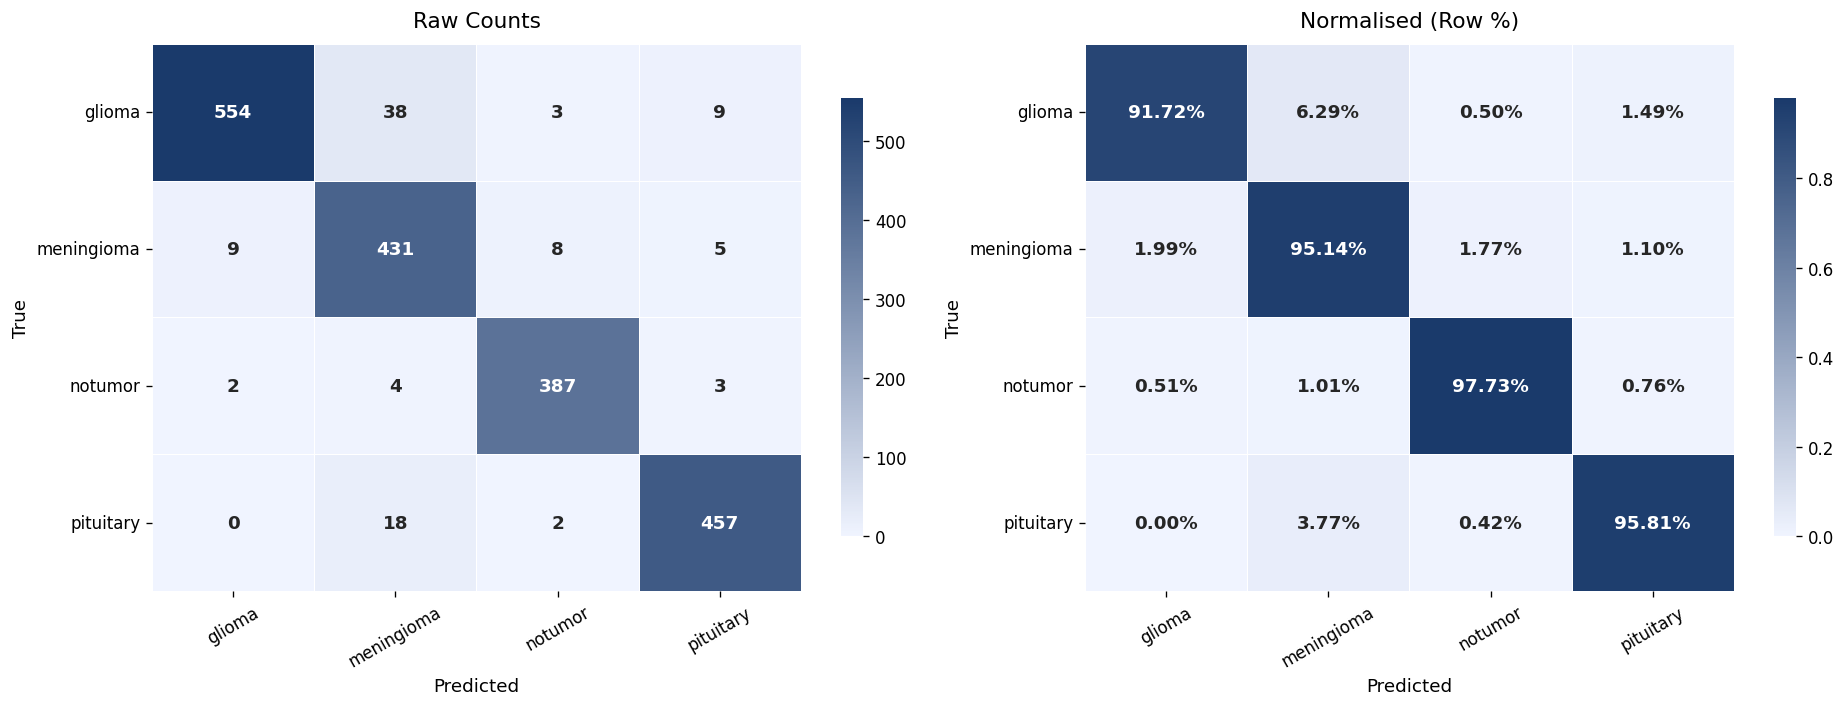

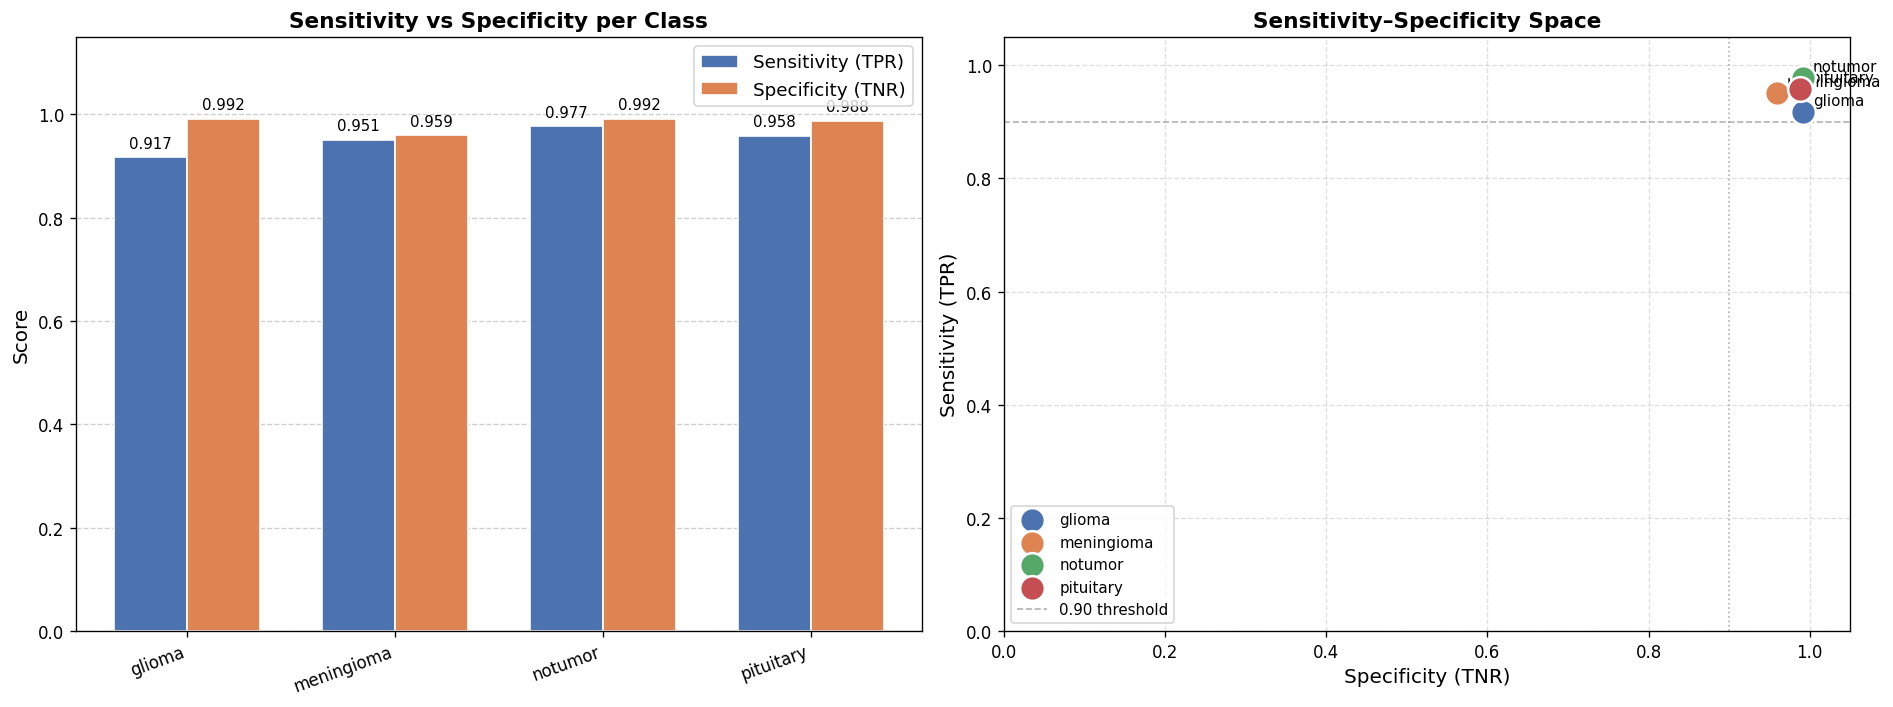


Class                   Sensitivity  Specificity
------------------------------------------------
  glioma                     0.9172       0.9917
  meningioma                 0.9514       0.9594
  notumor                    0.9773       0.9915
  pituitary                  0.9581       0.9883
------------------------------------------------
  Macro Average              0.9510       0.9827


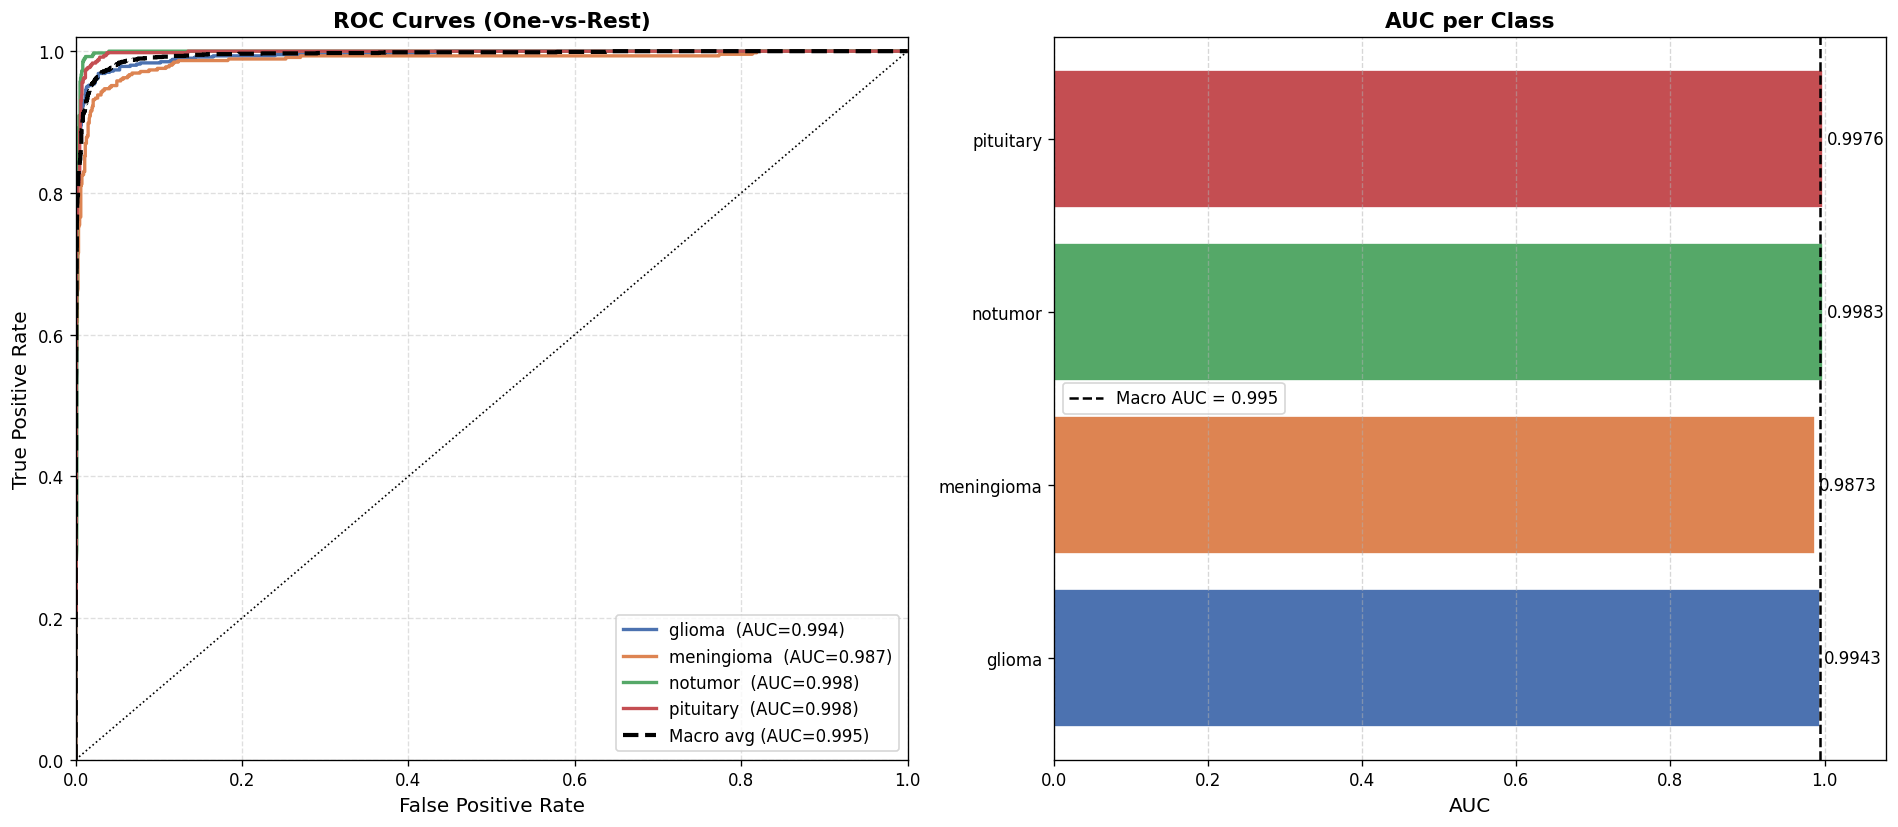

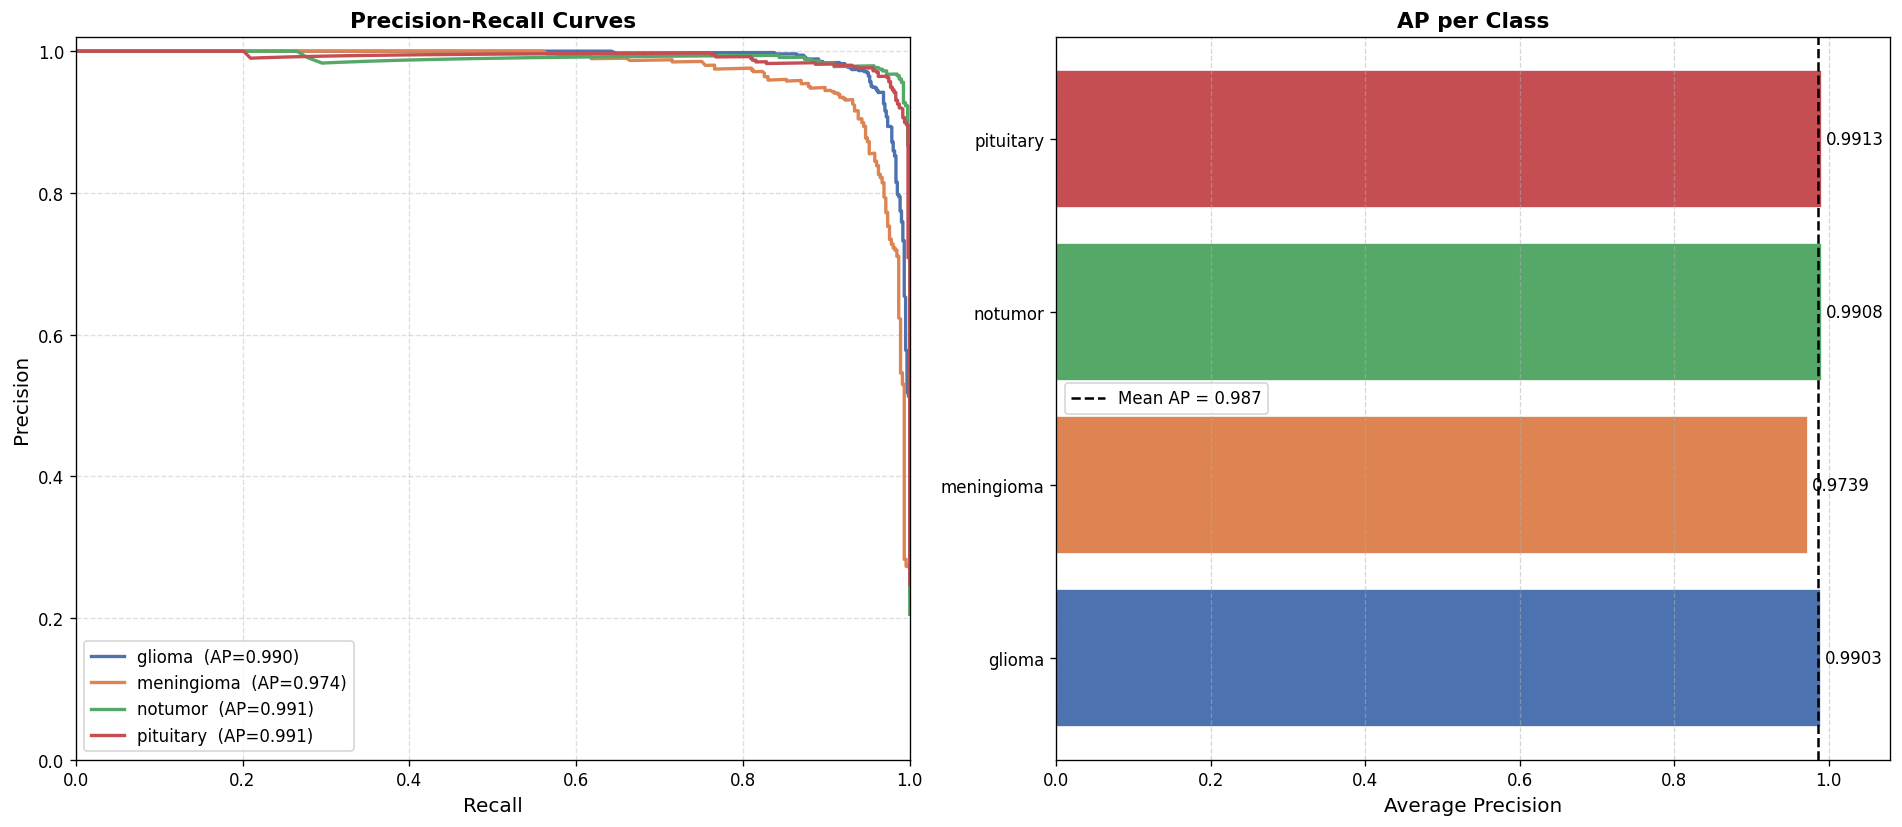

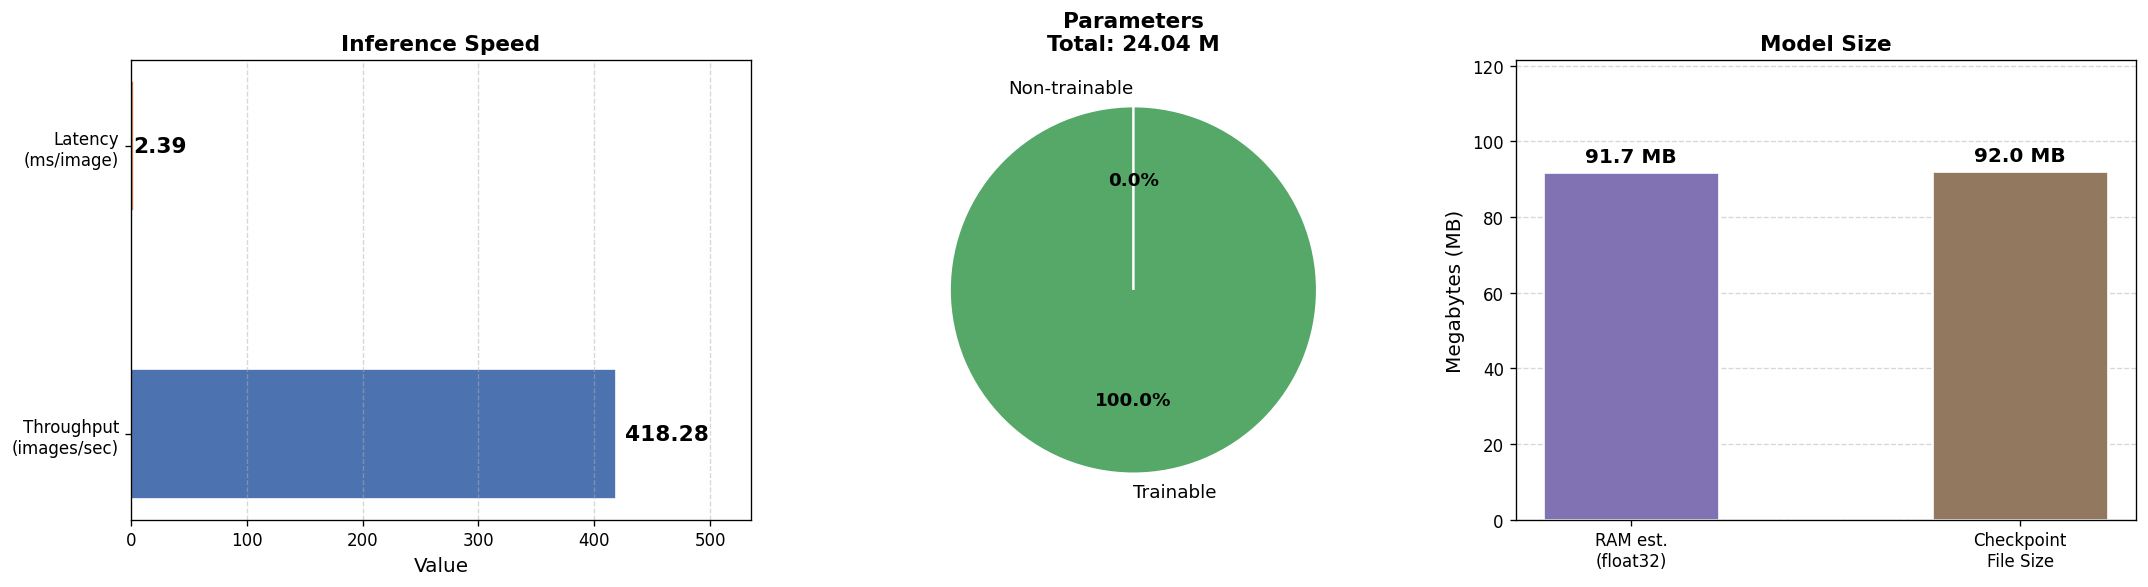


  Throughput        : 418.3 images / sec
  Latency per image : 2.39 ms
  Total parameters  : 24.038 M
  Trainable params  : 24.038 M
  Float32 RAM est.  : 91.7 MB
  Checkpoint file   : 92.0 MB


/tmp/ipykernel_55/3254098283.py:710: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


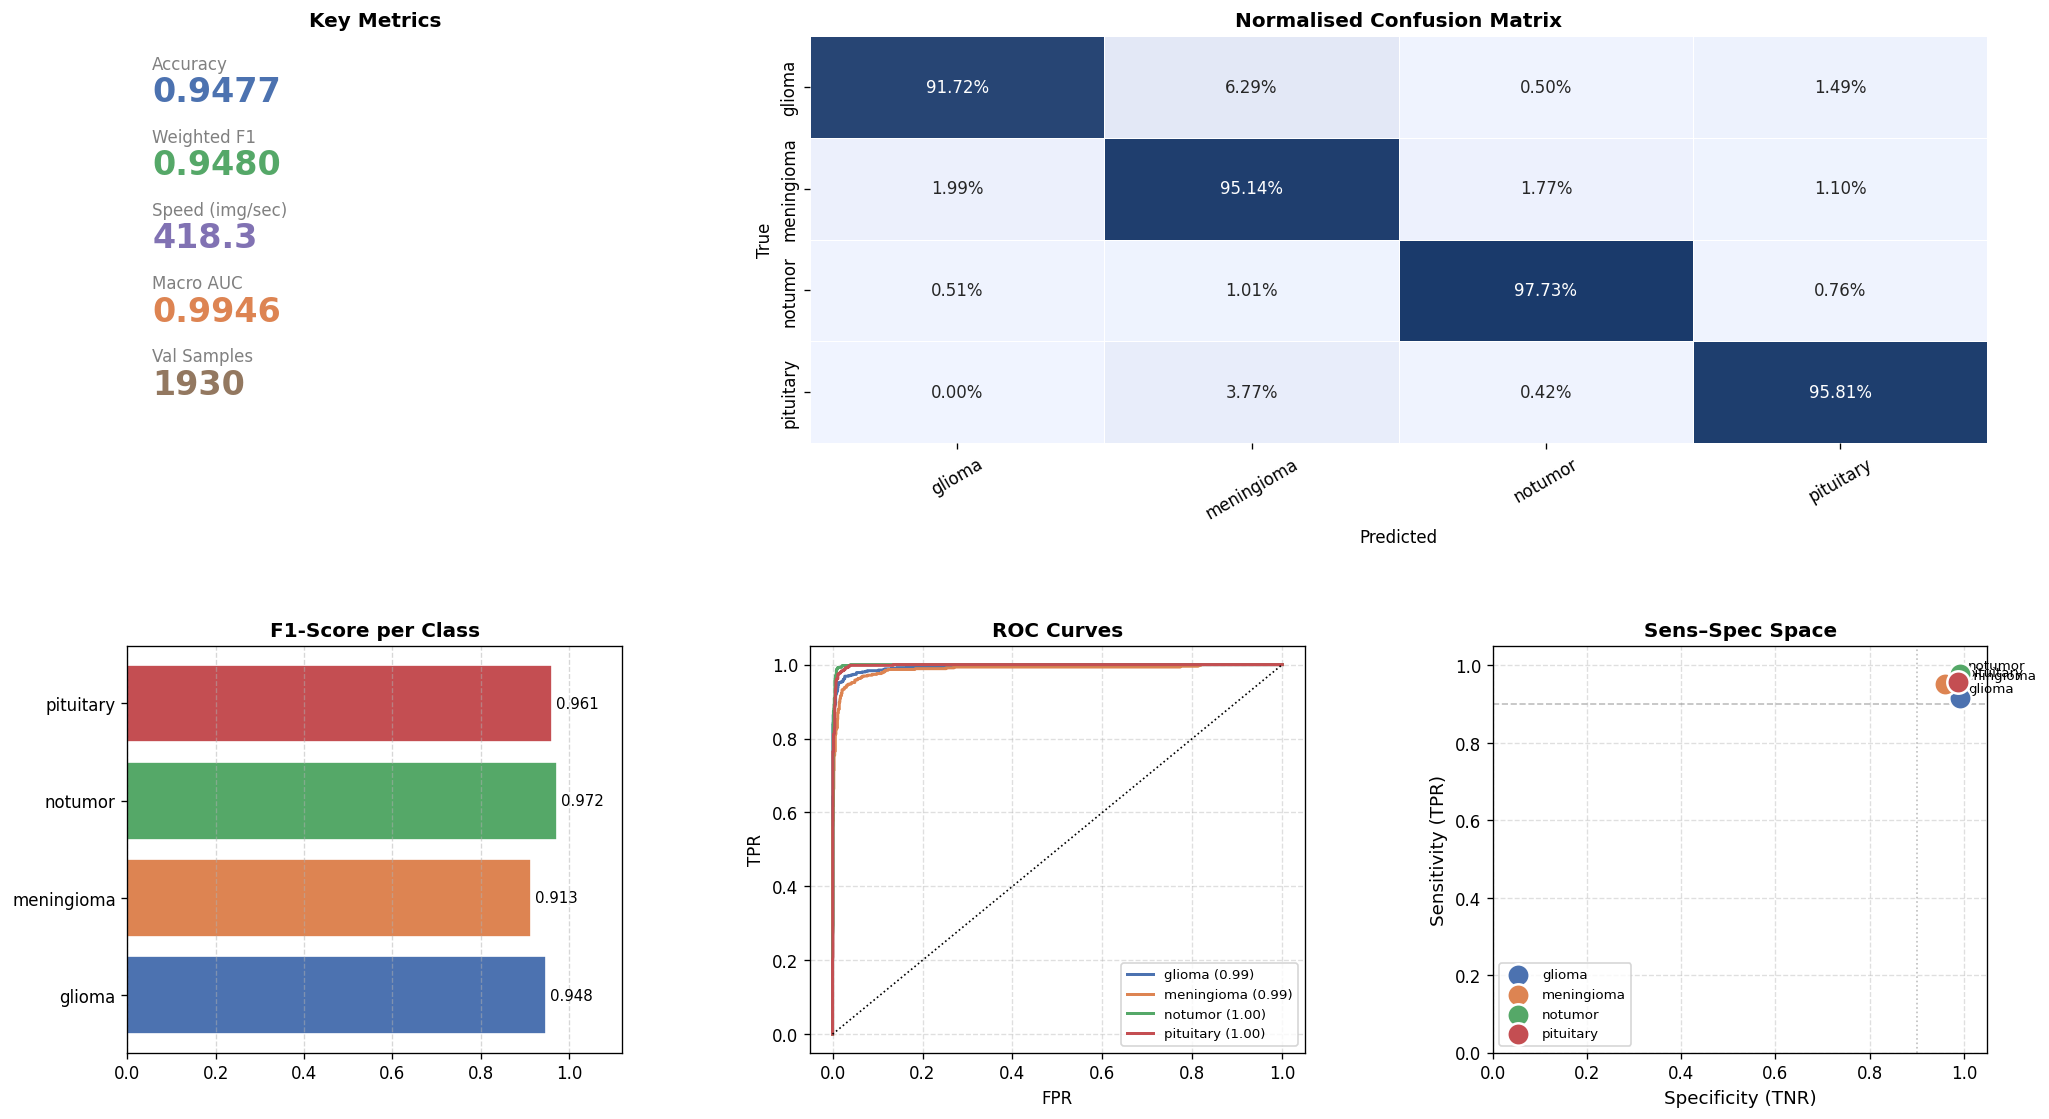

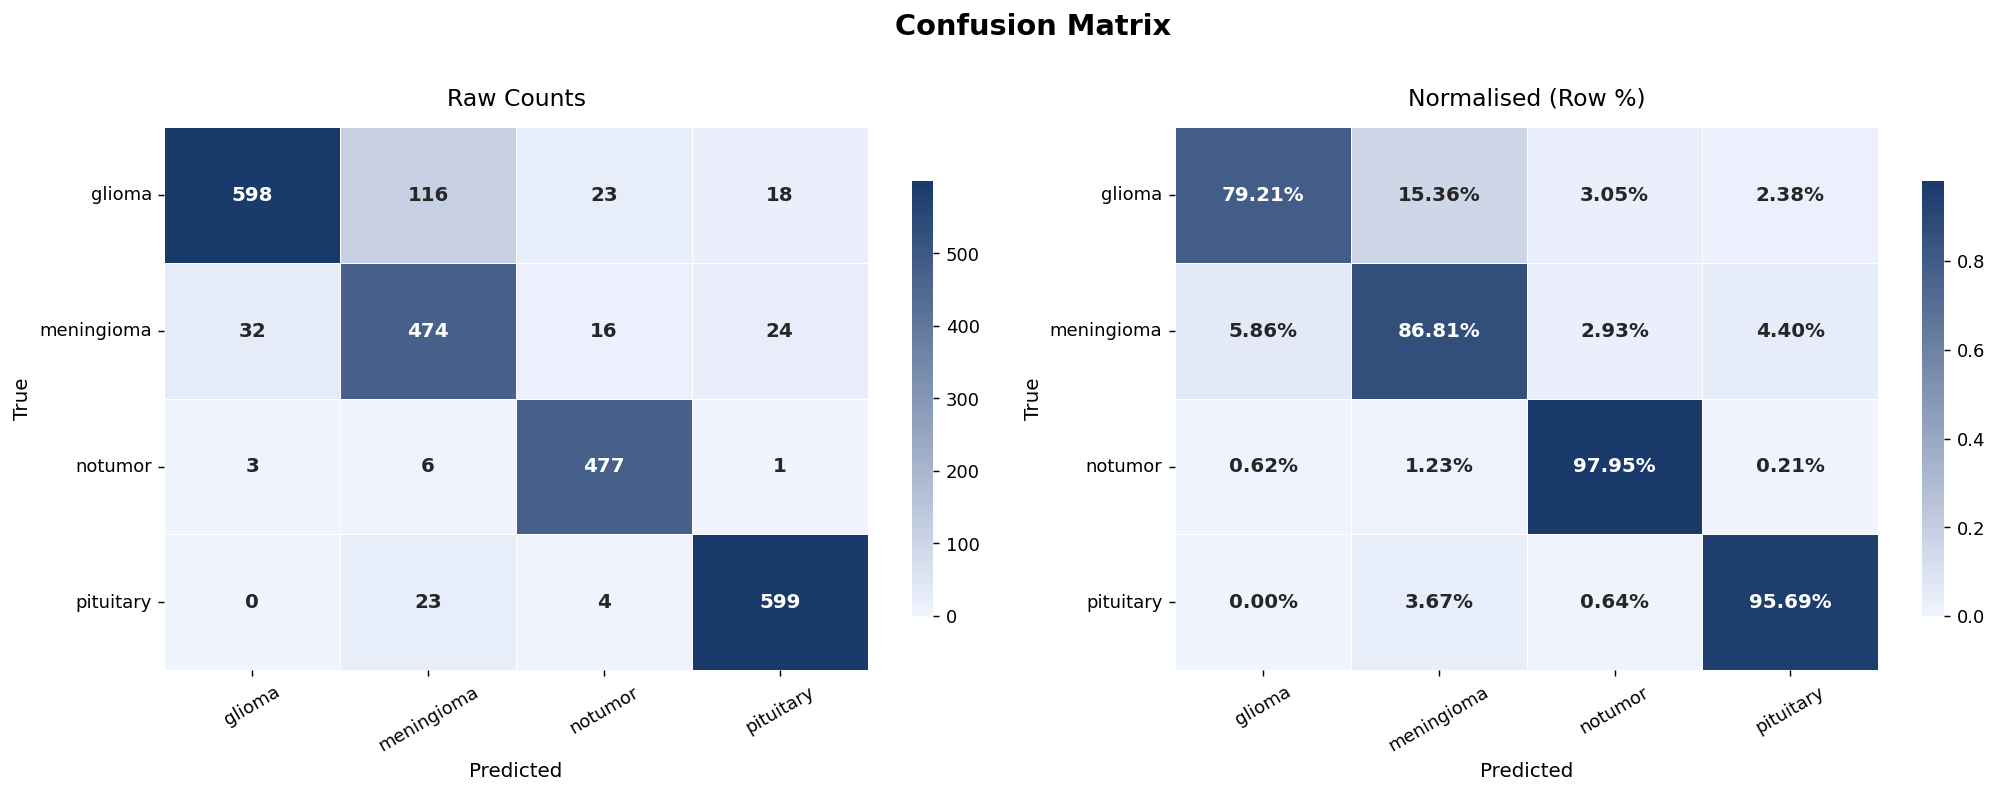

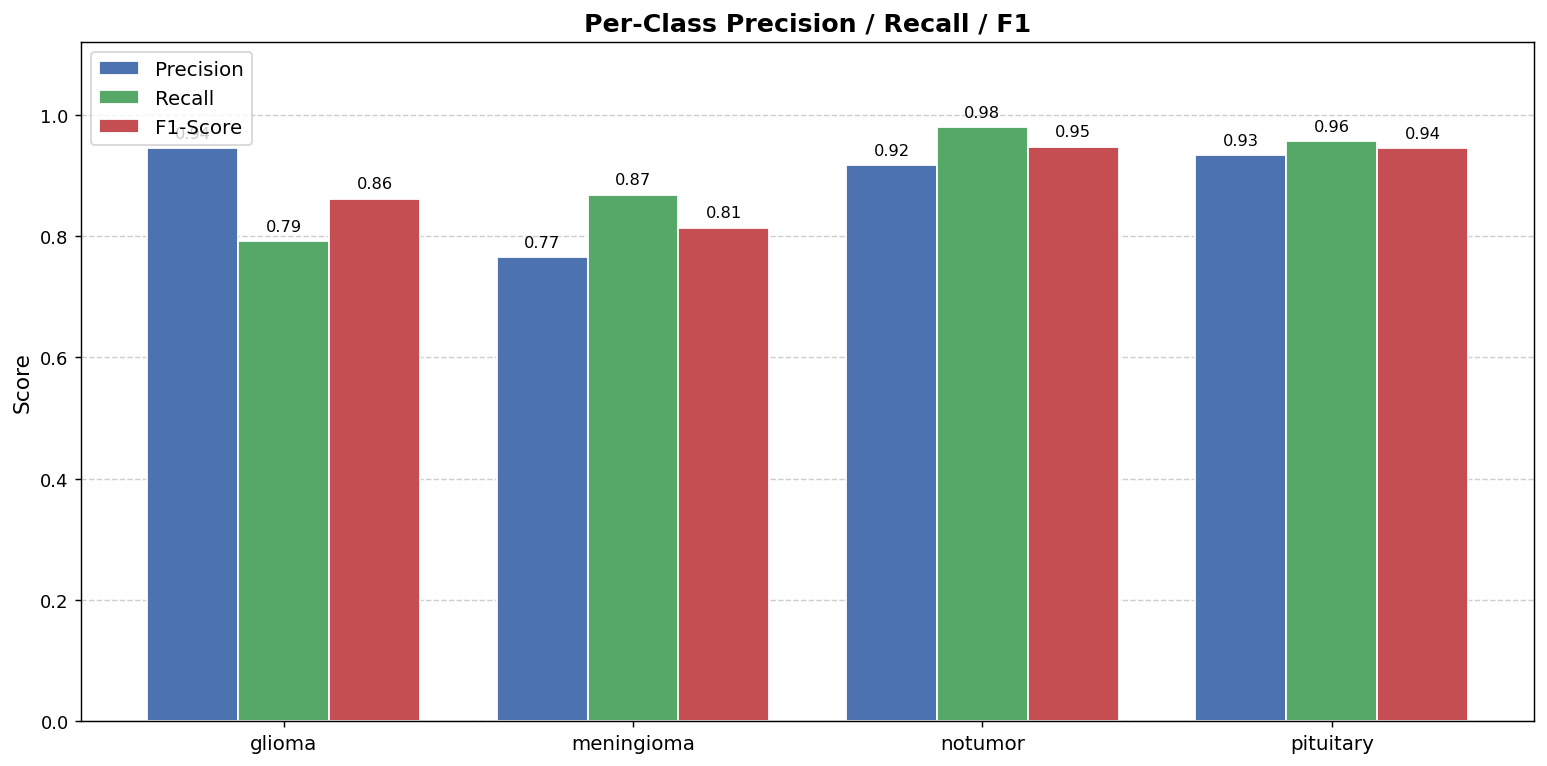

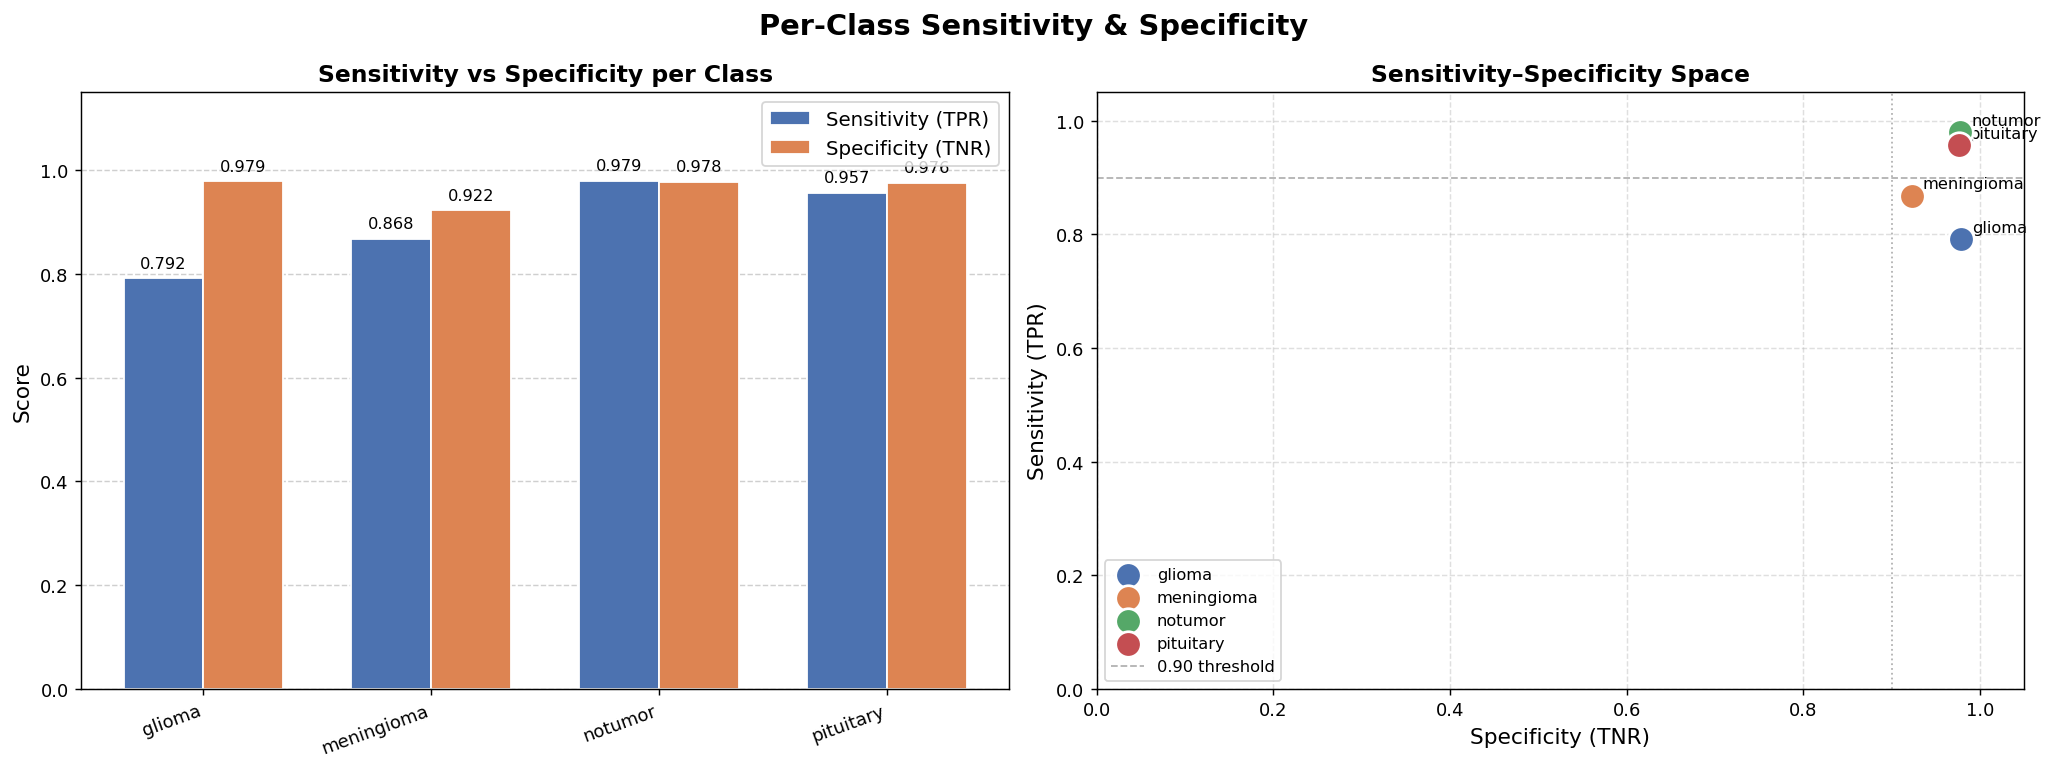

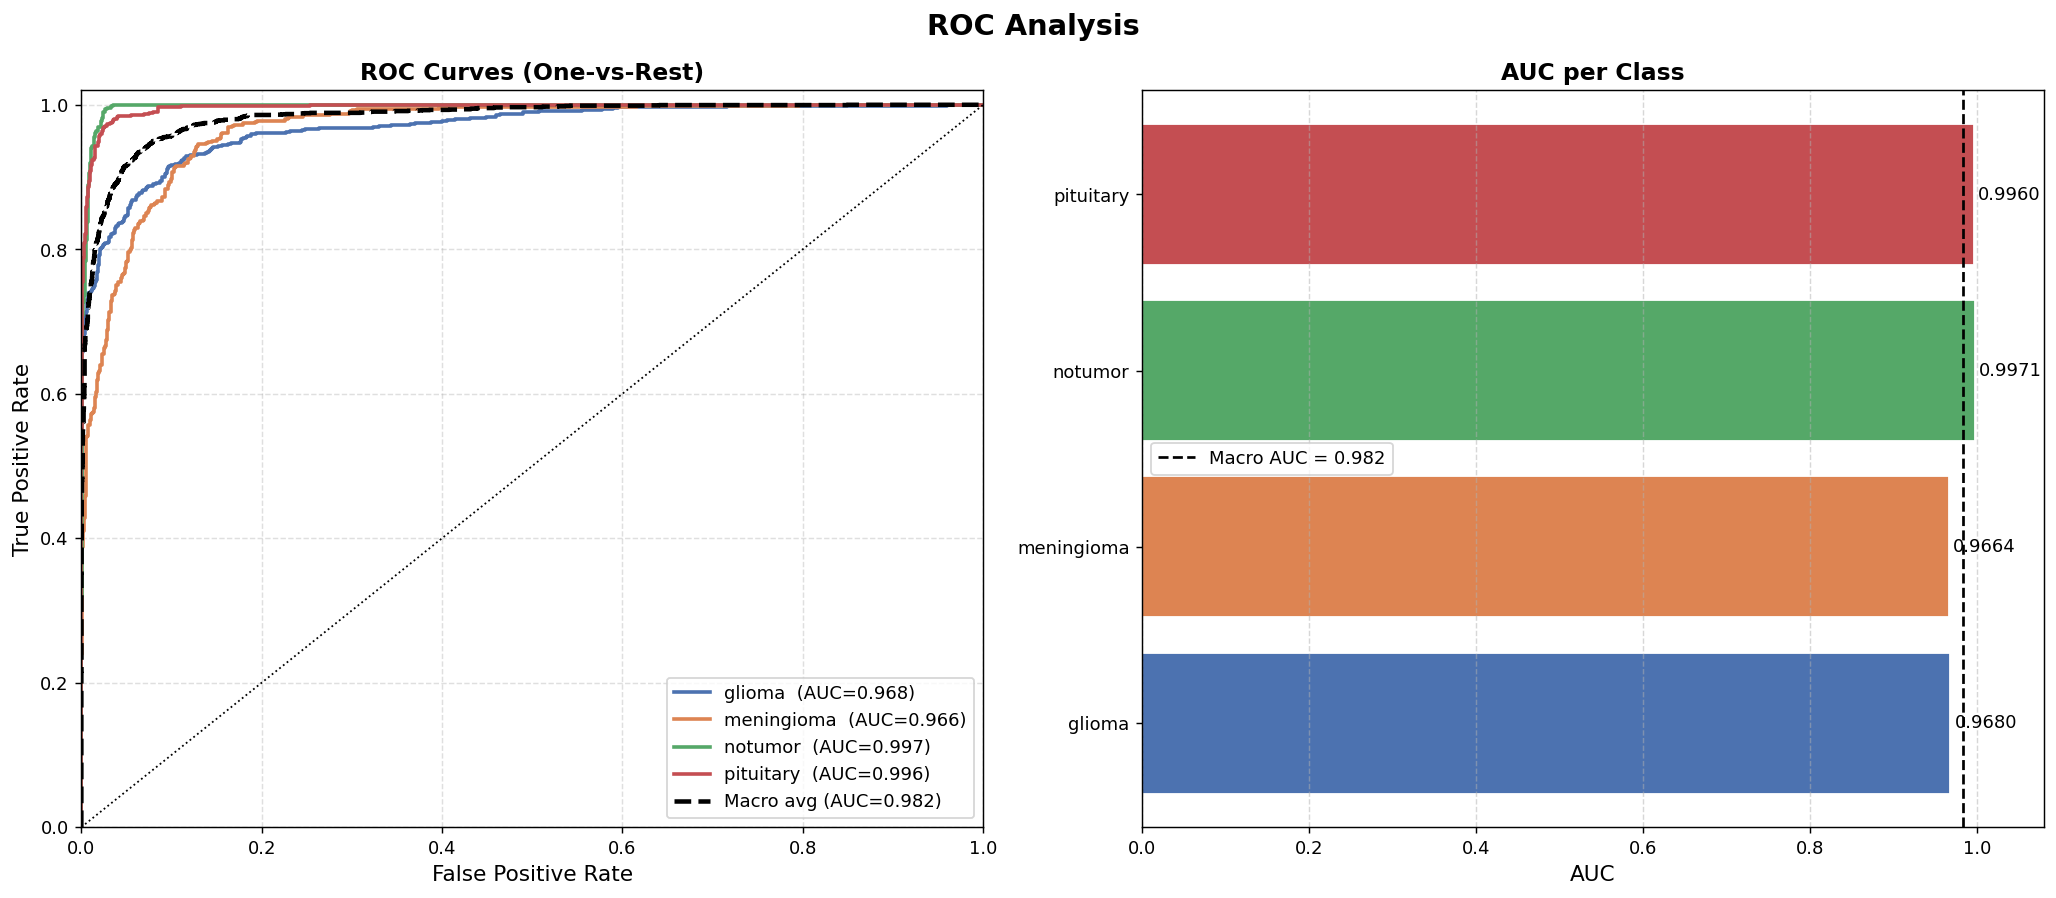

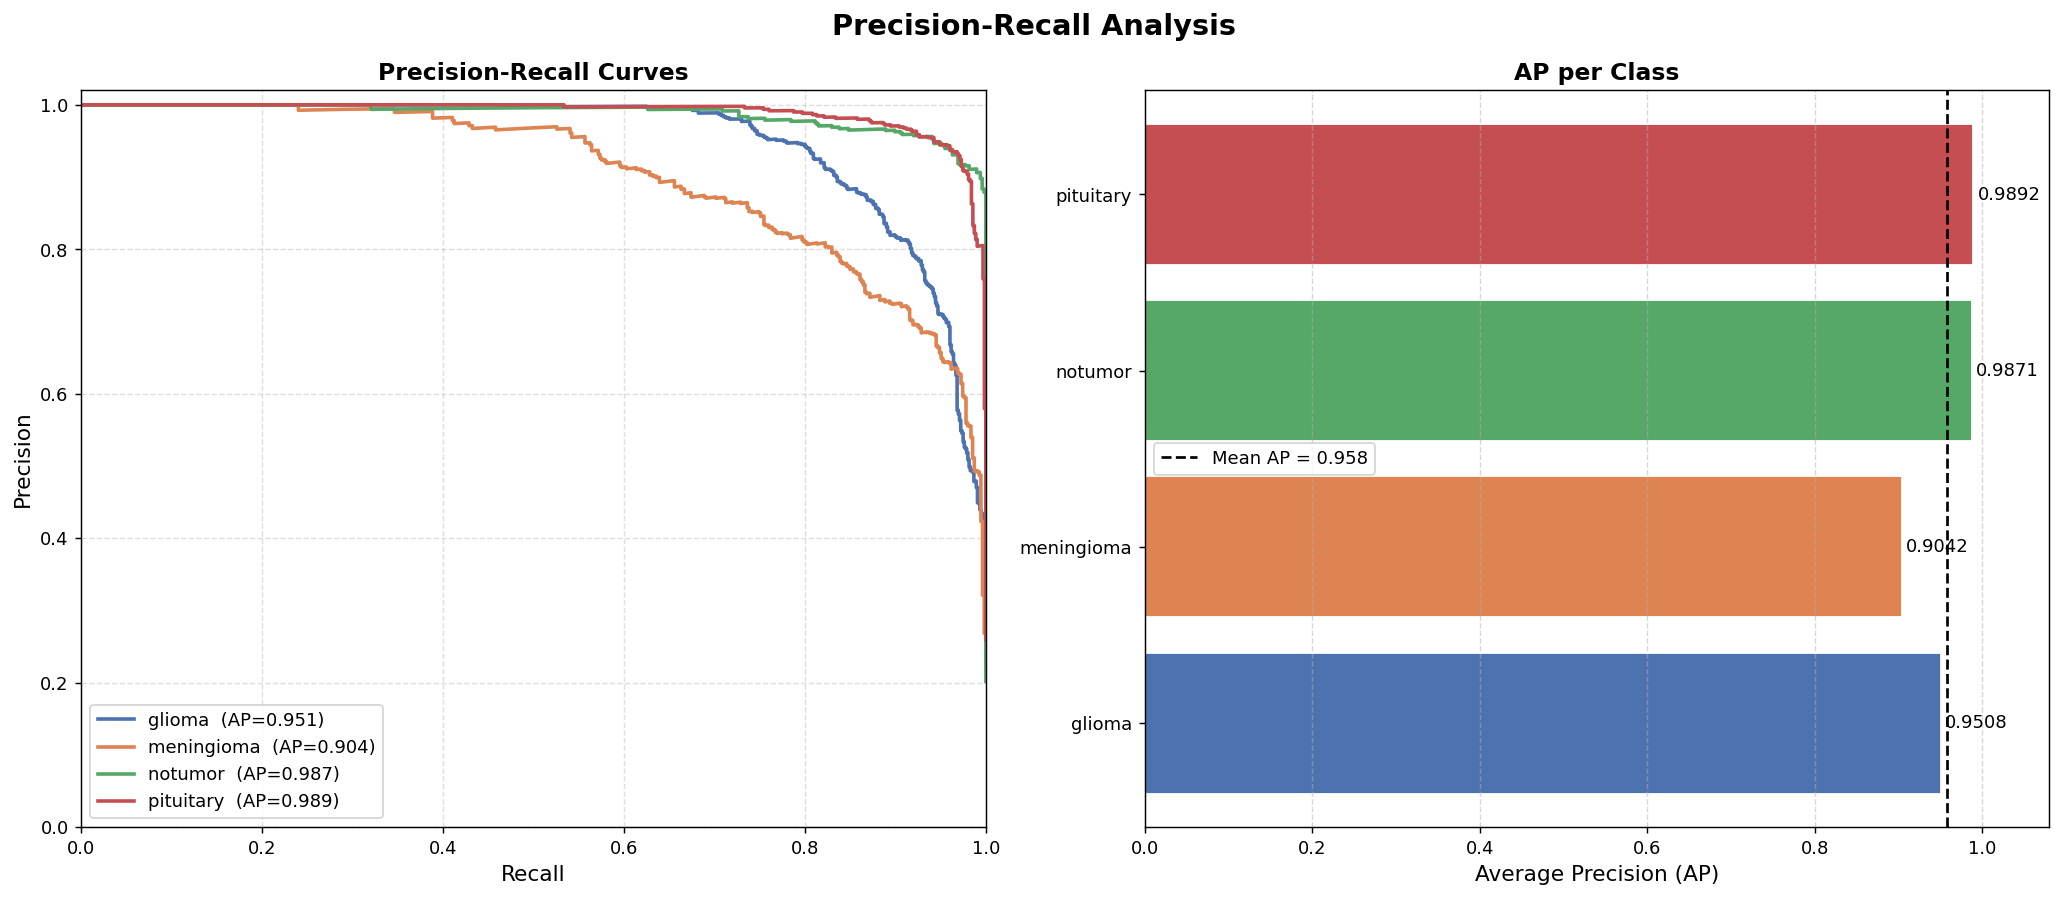

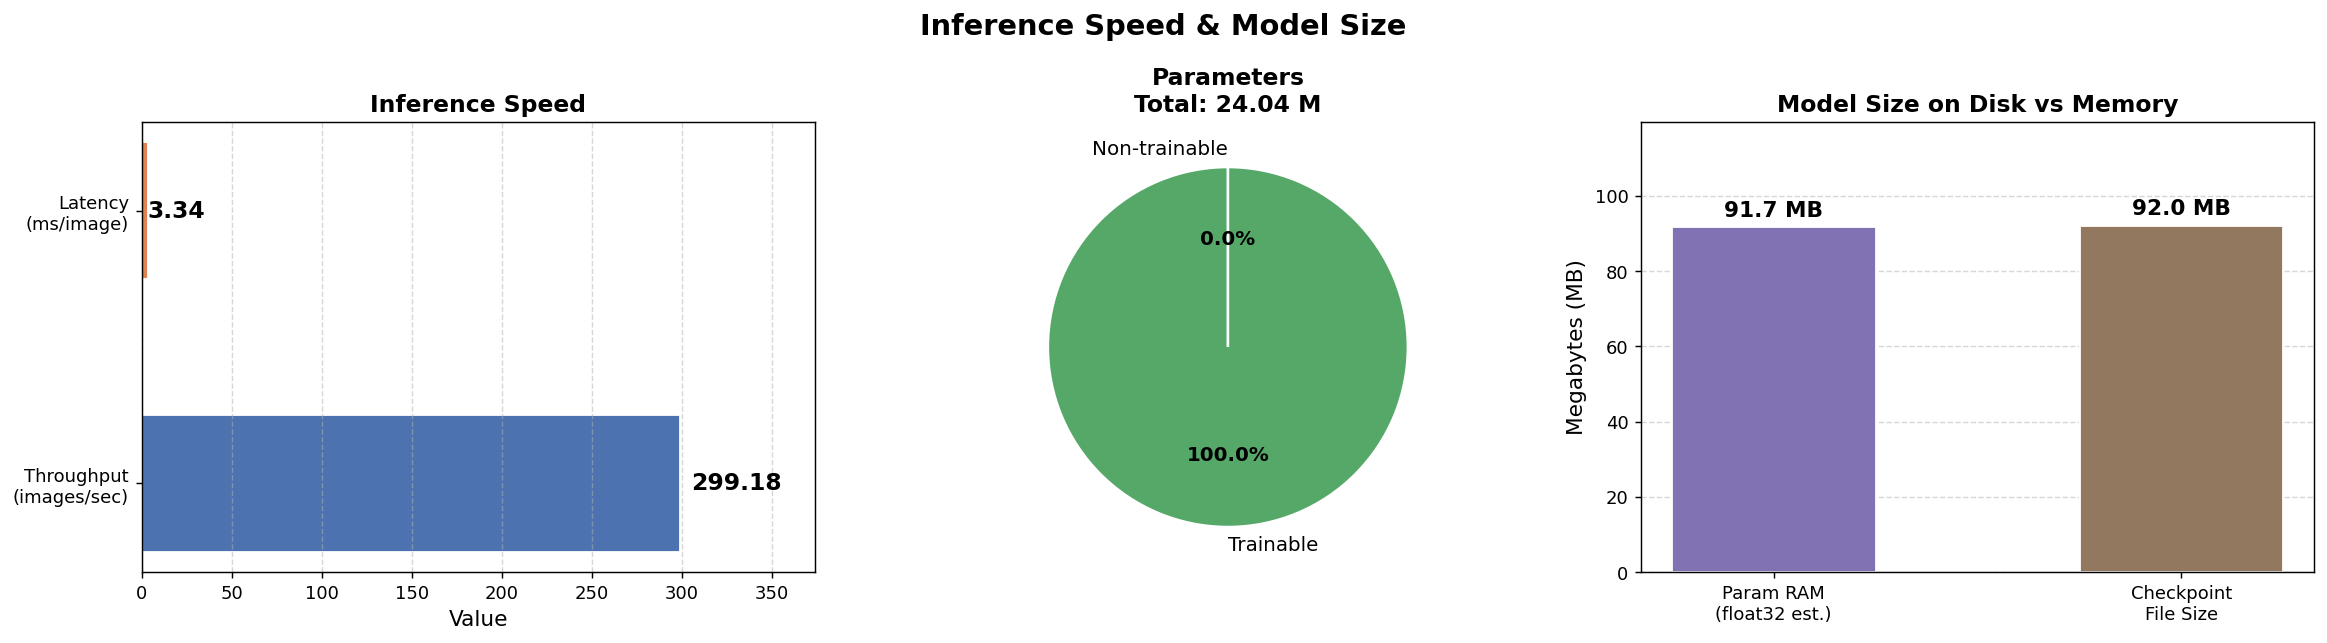

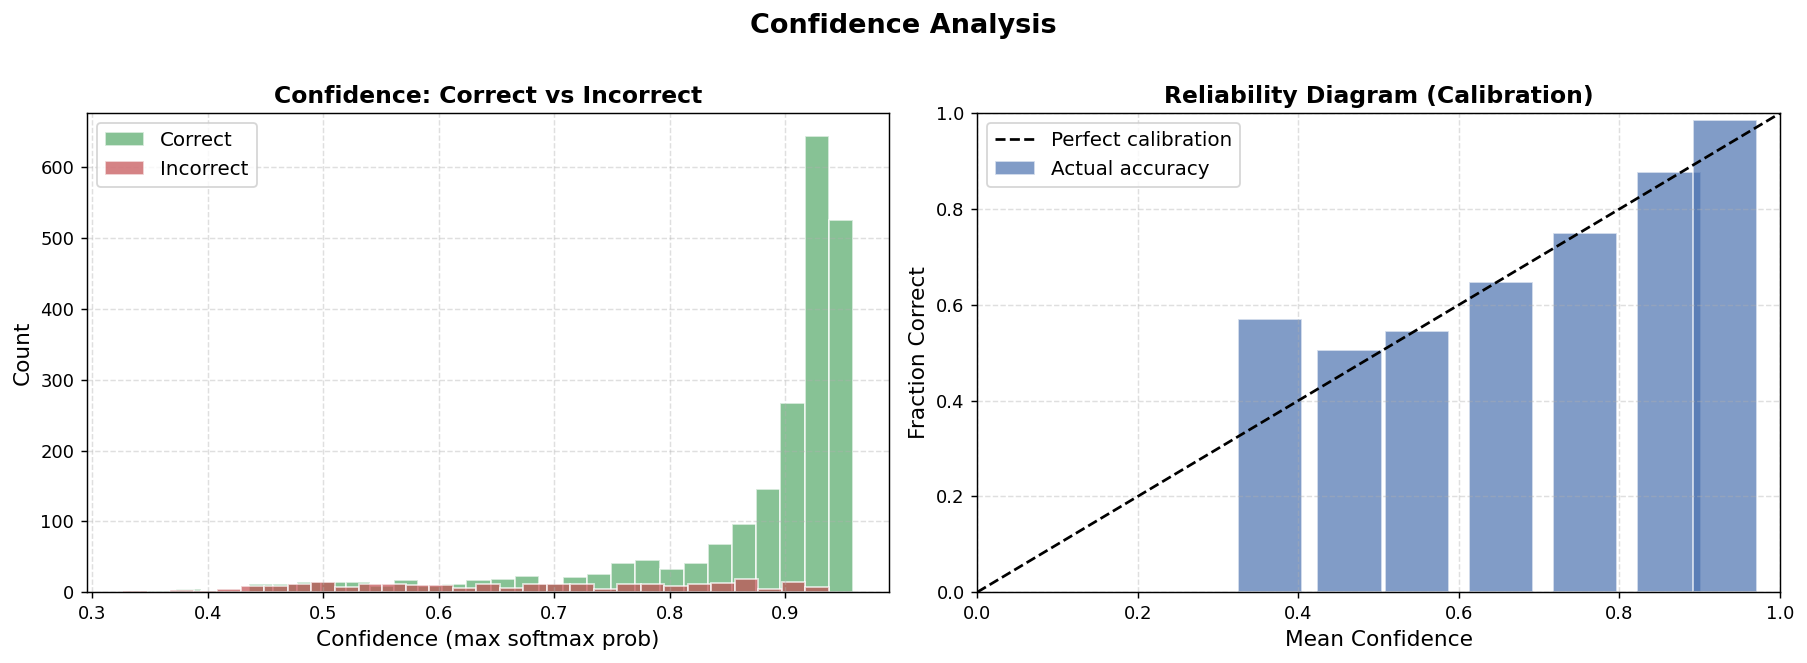

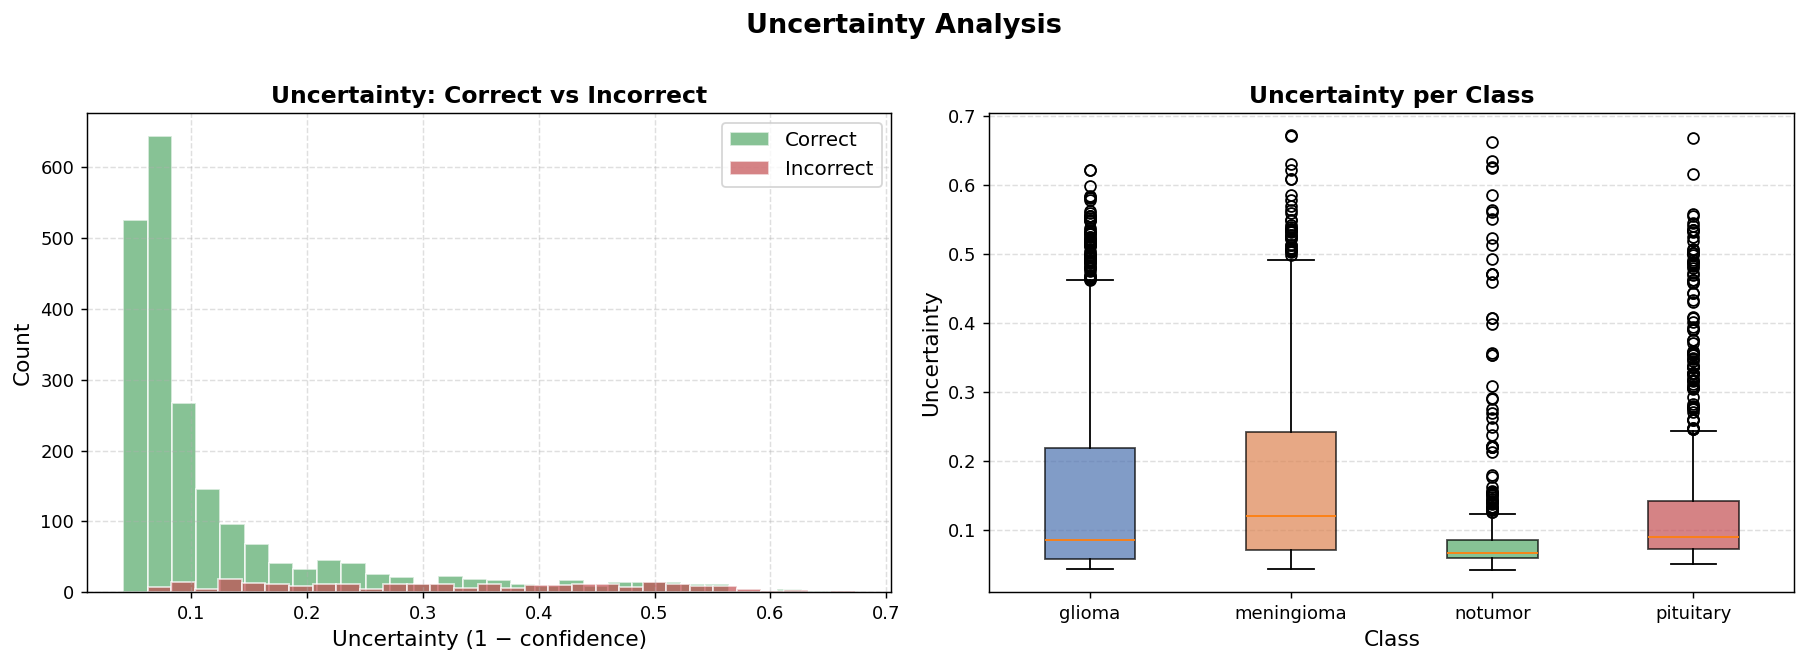

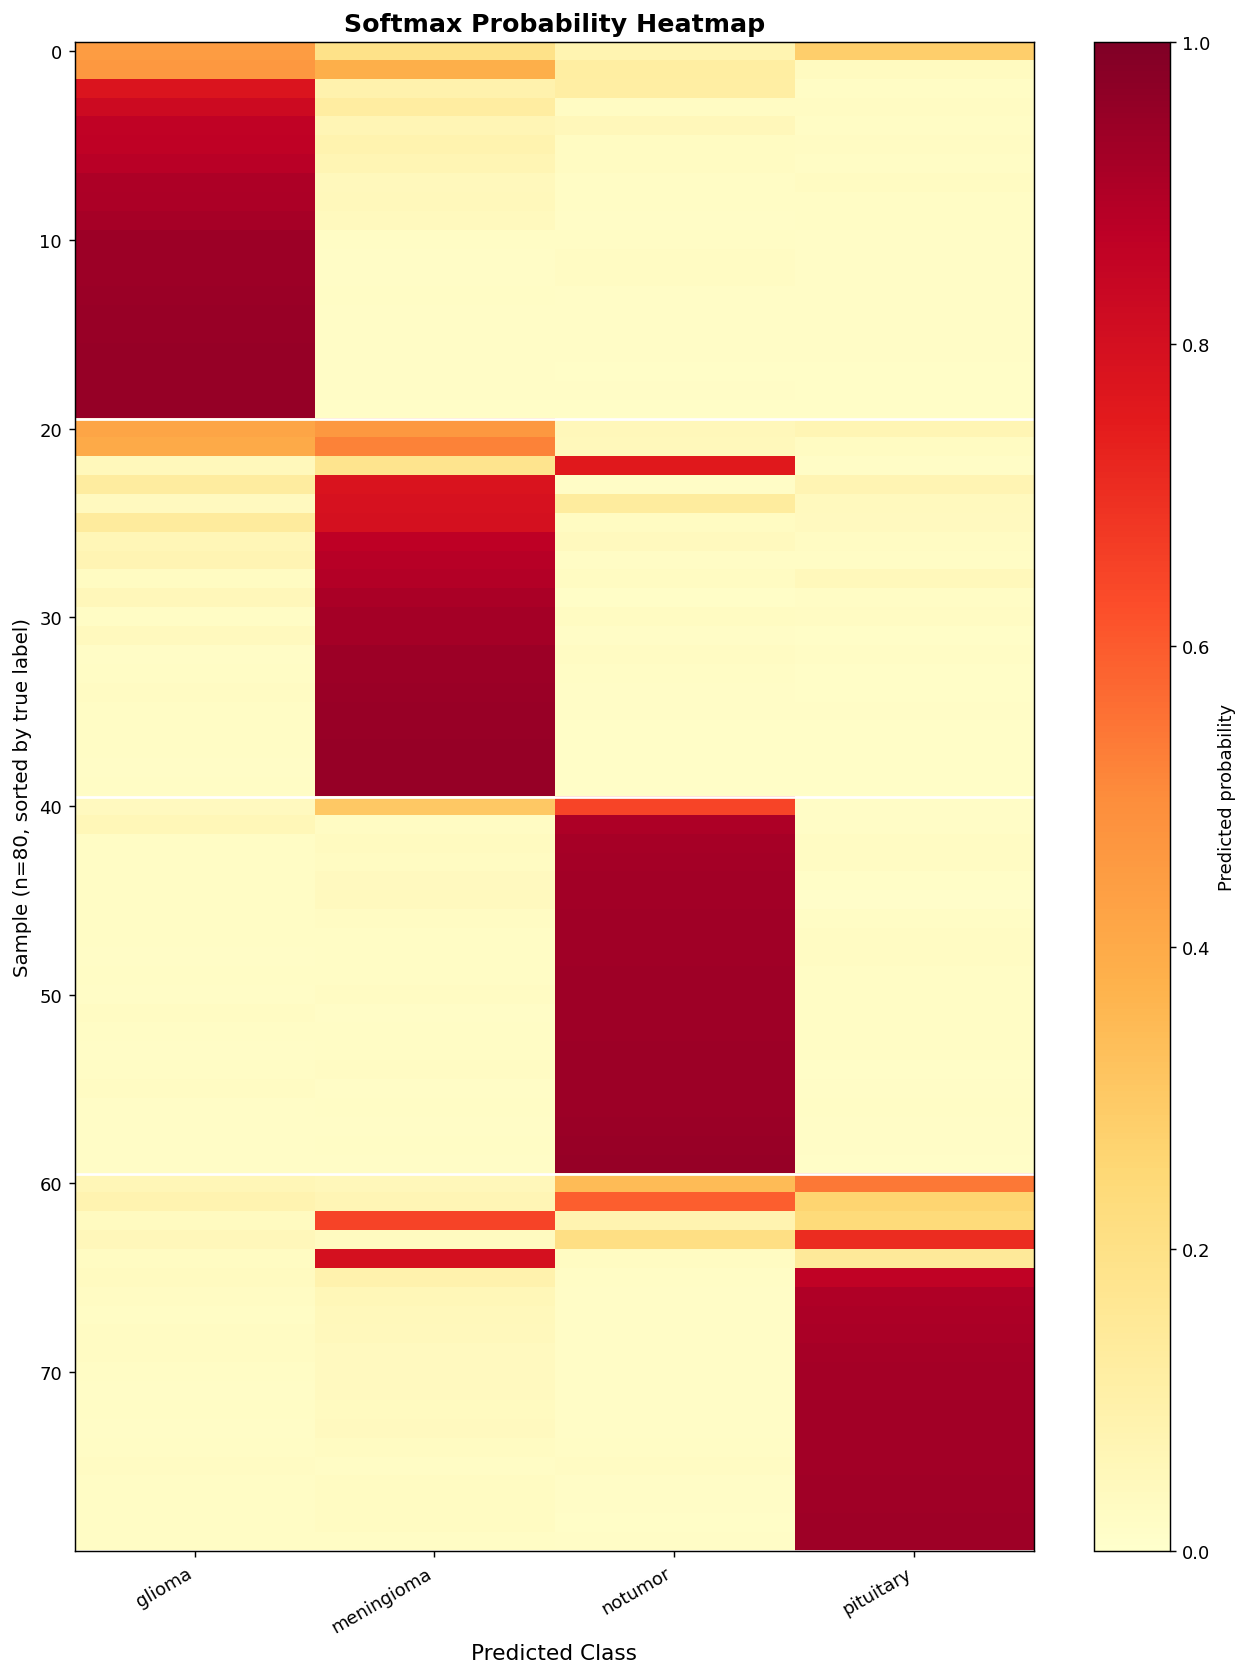

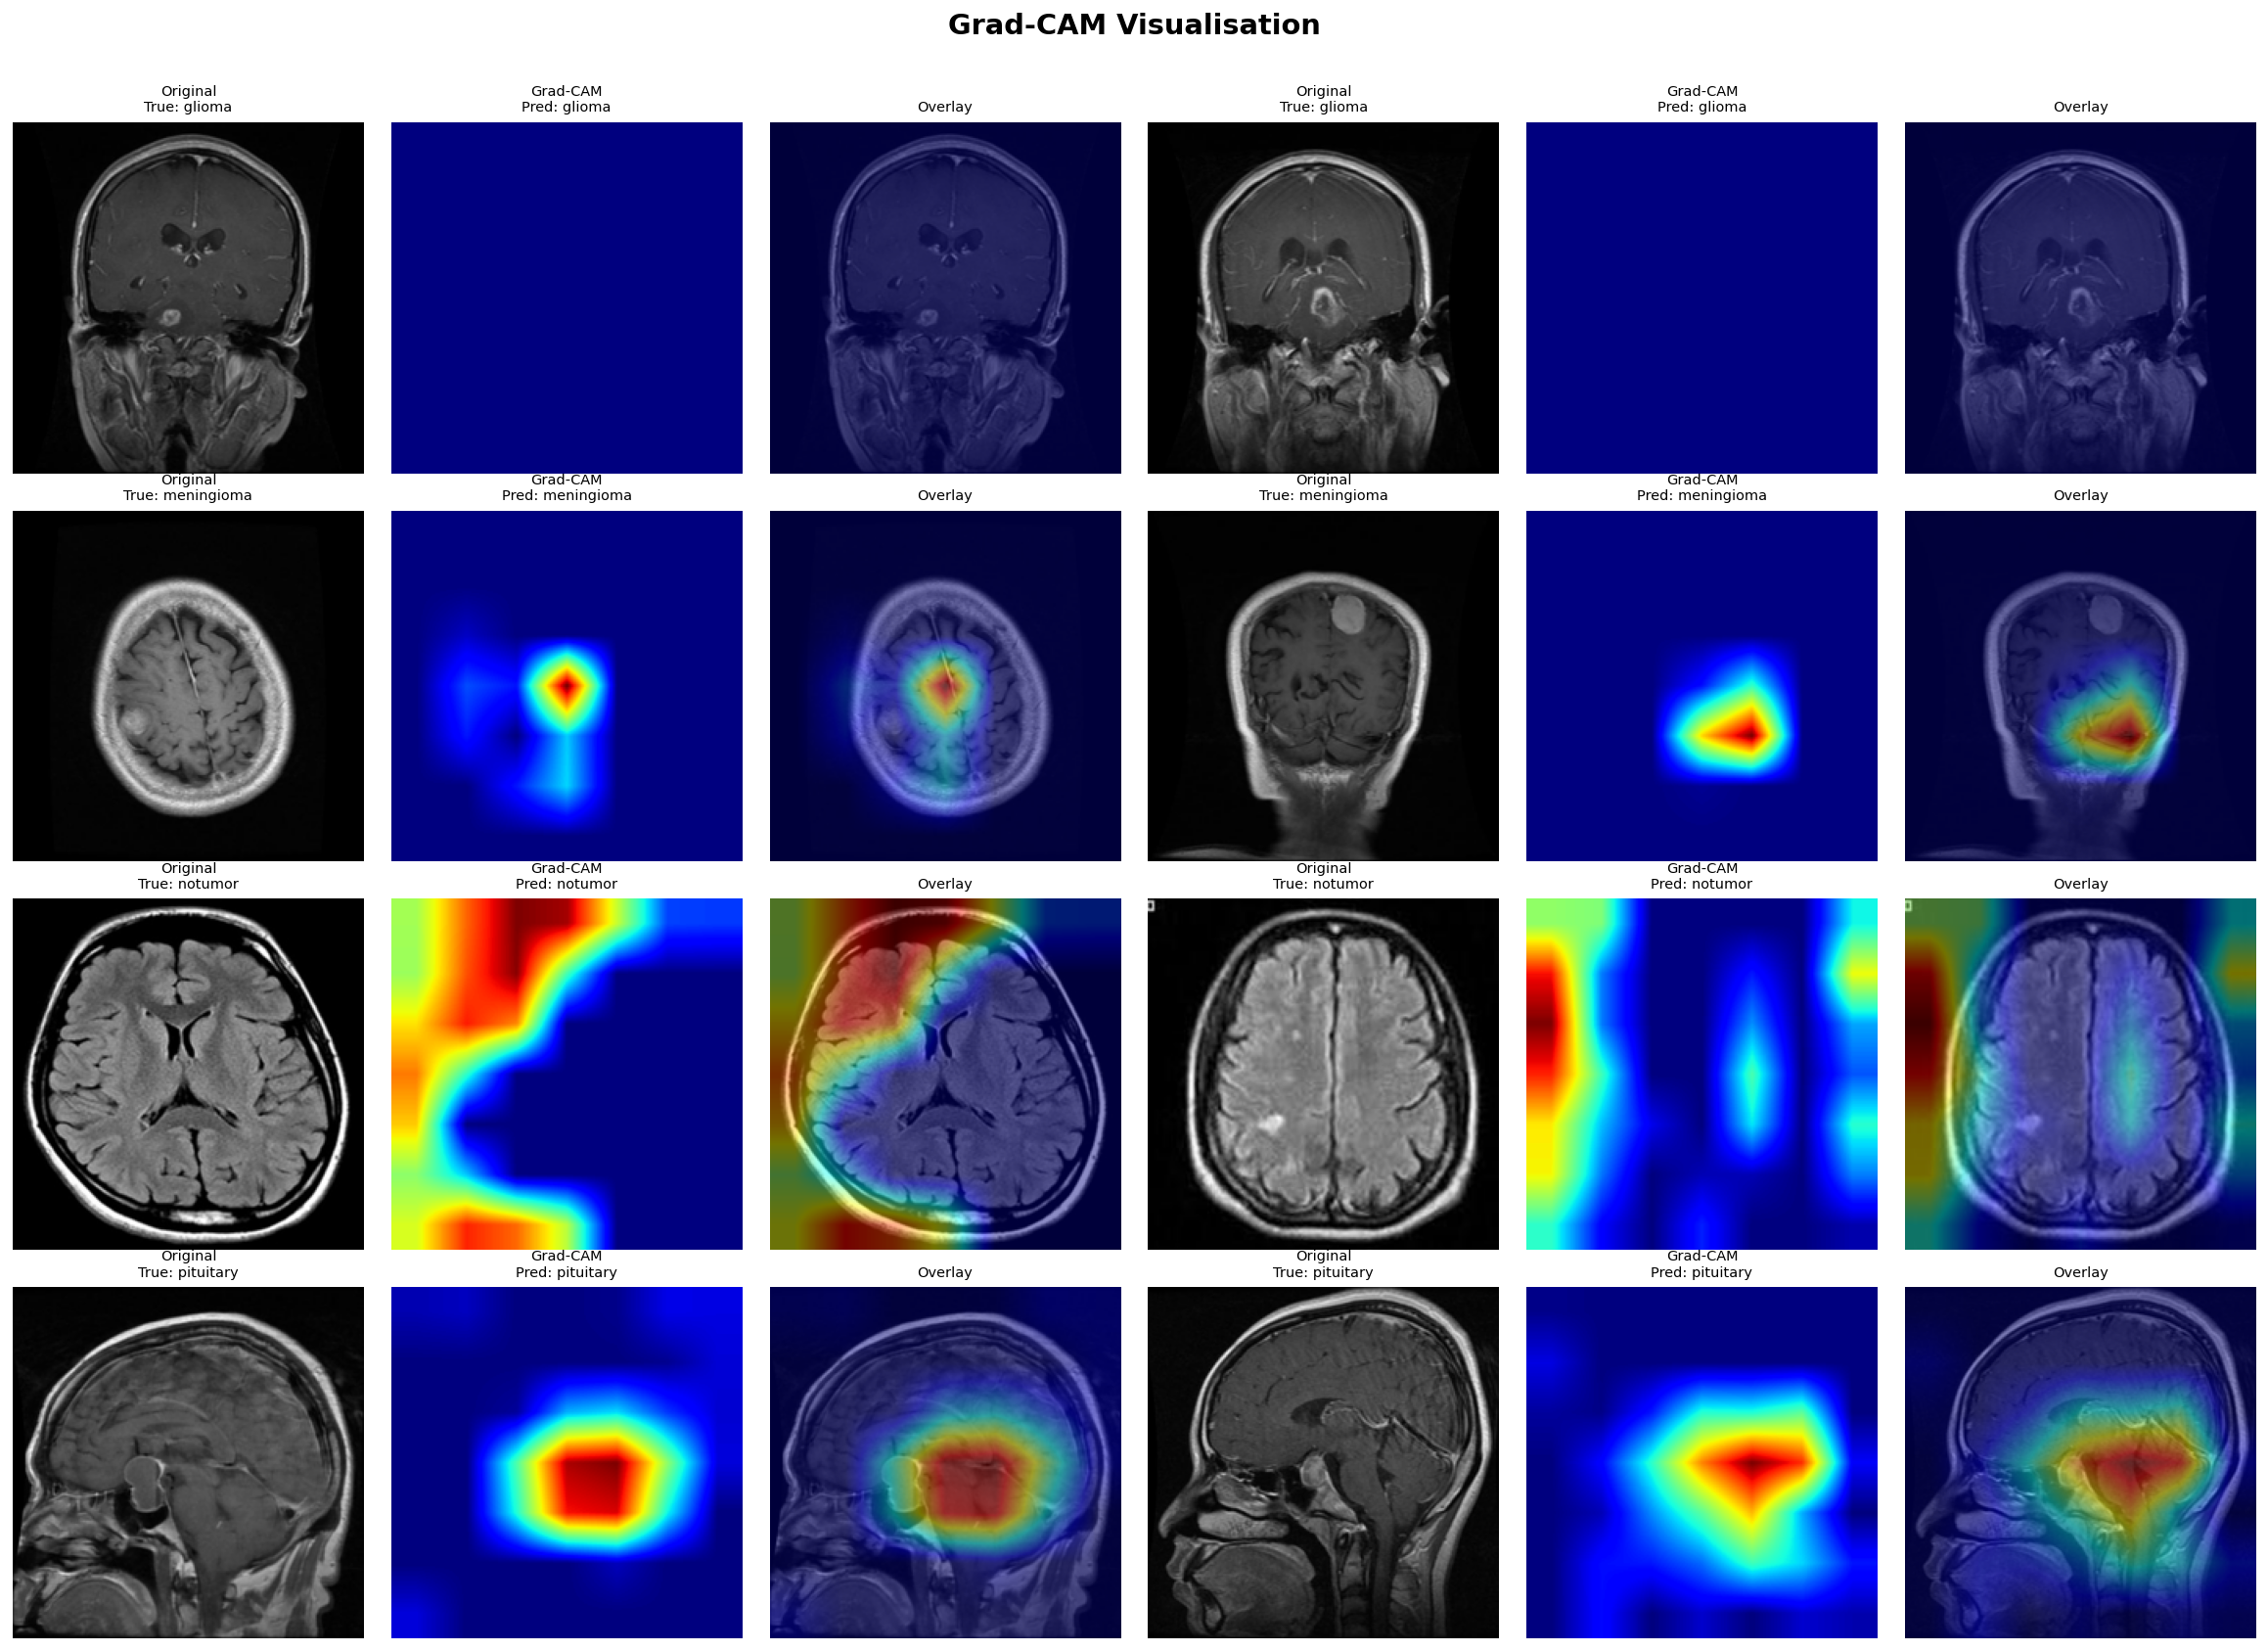

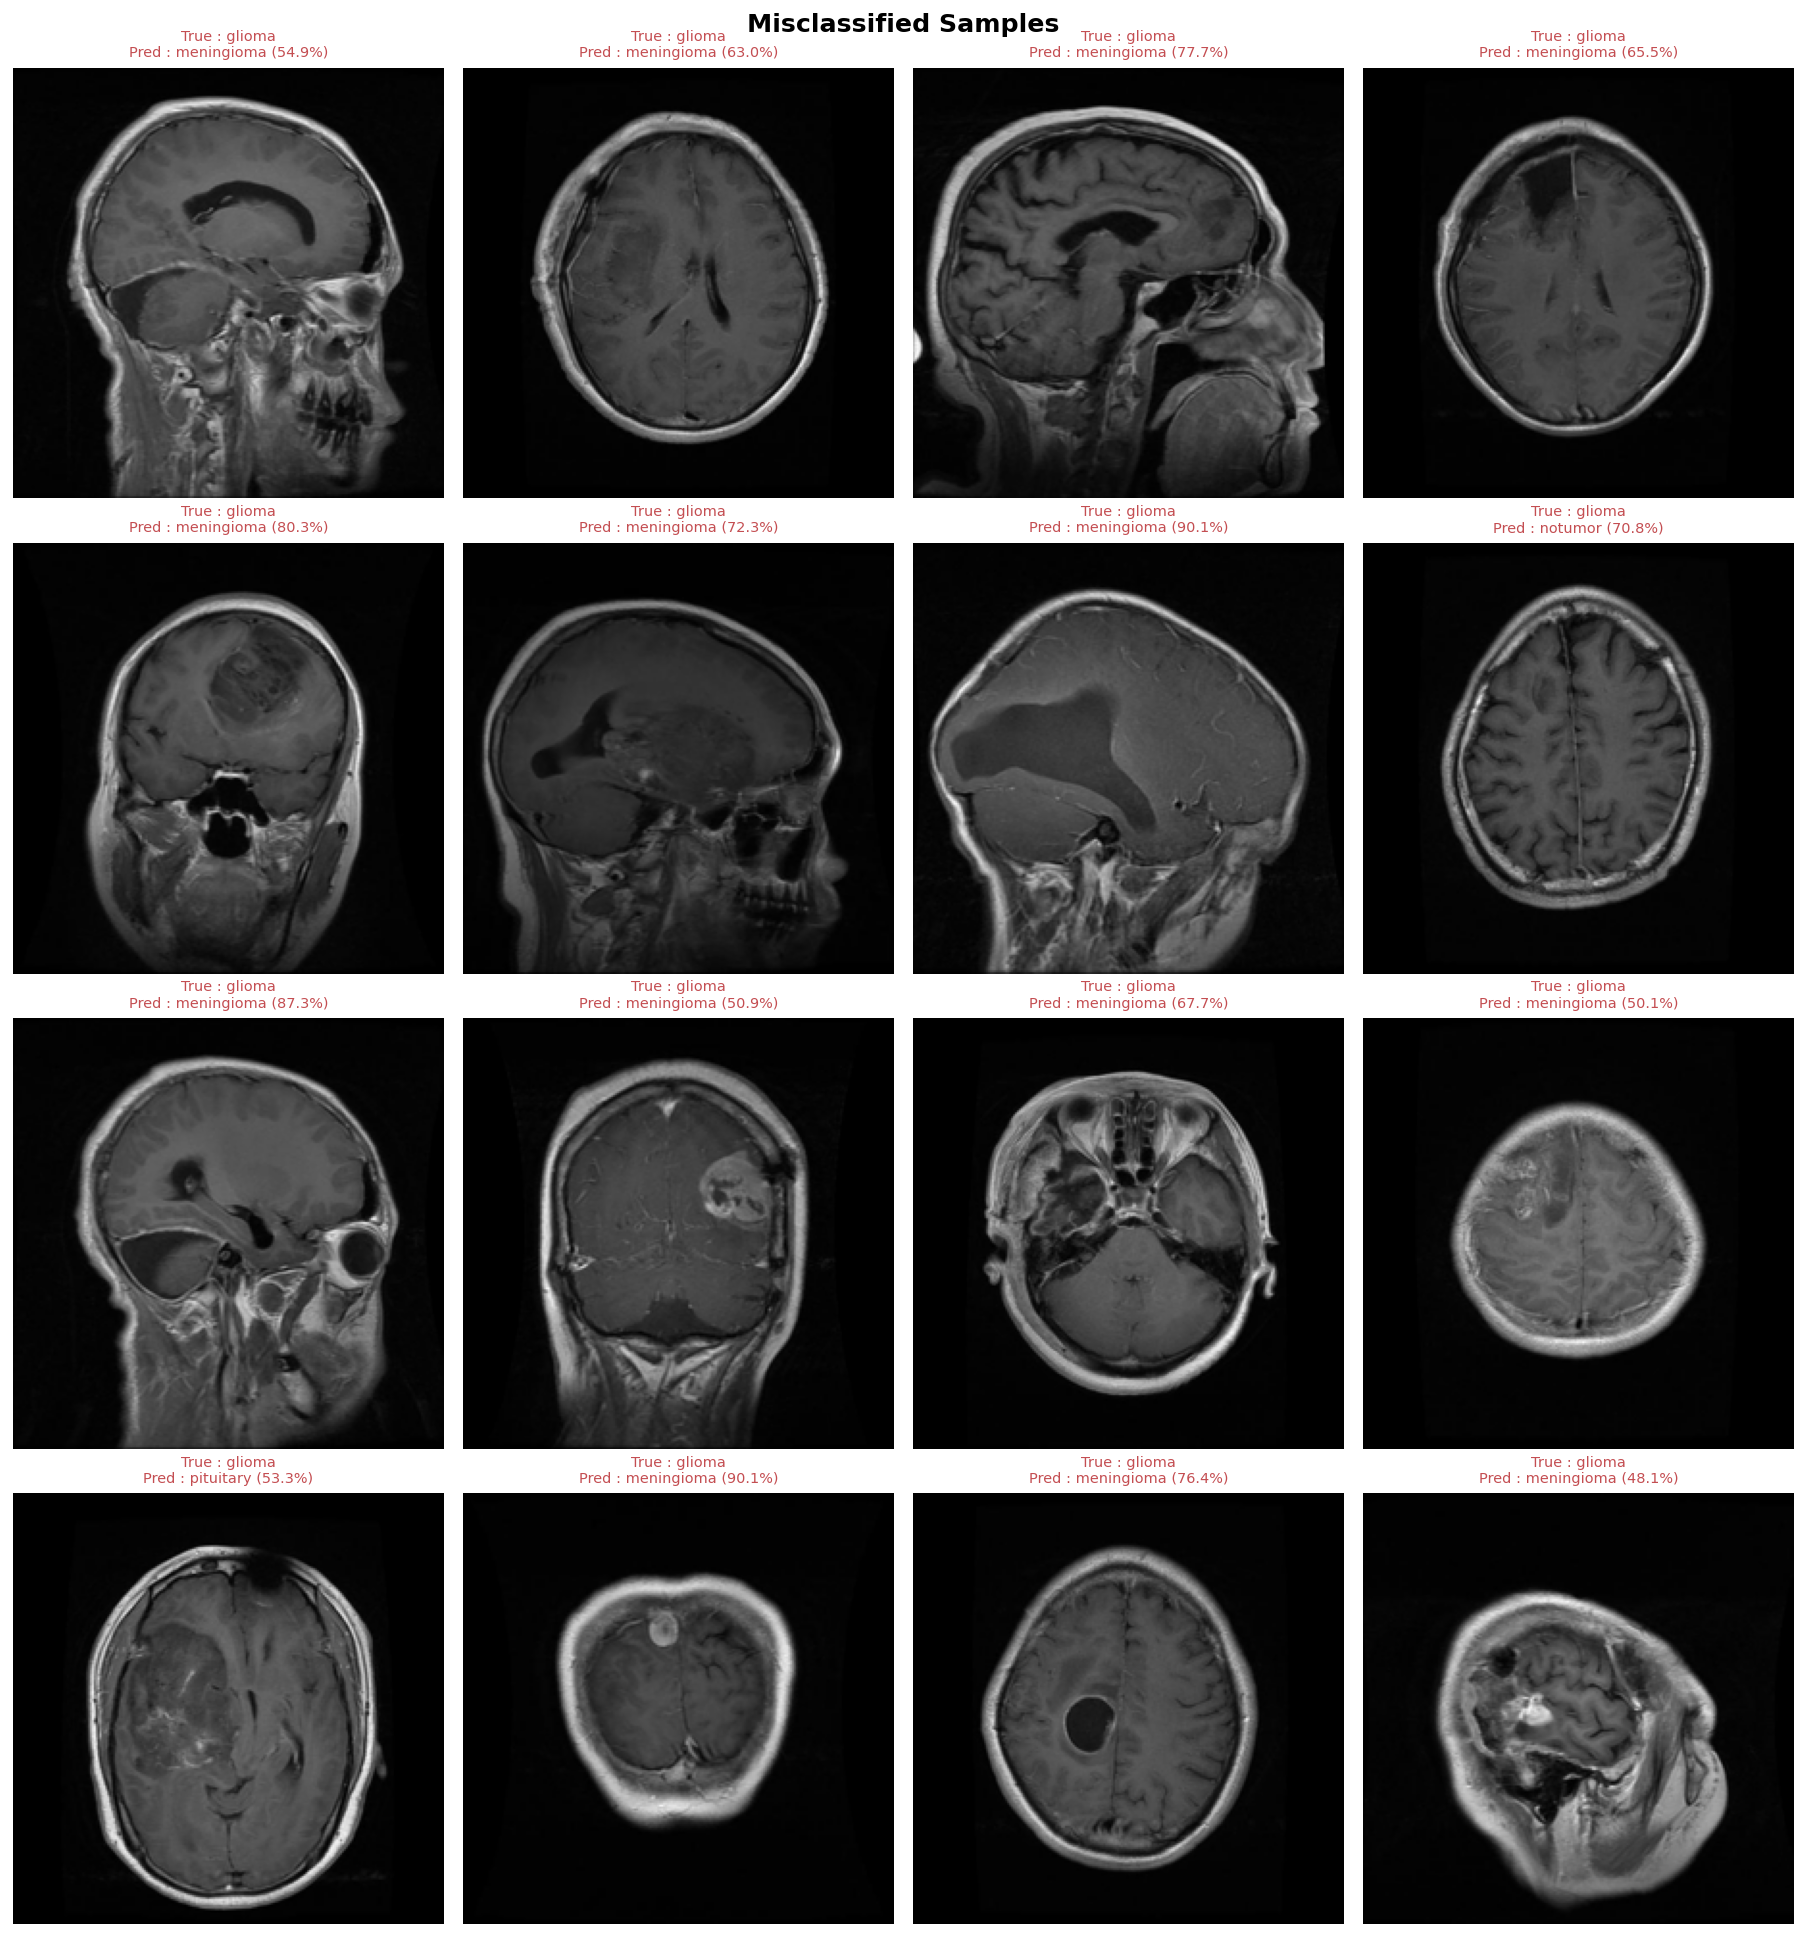

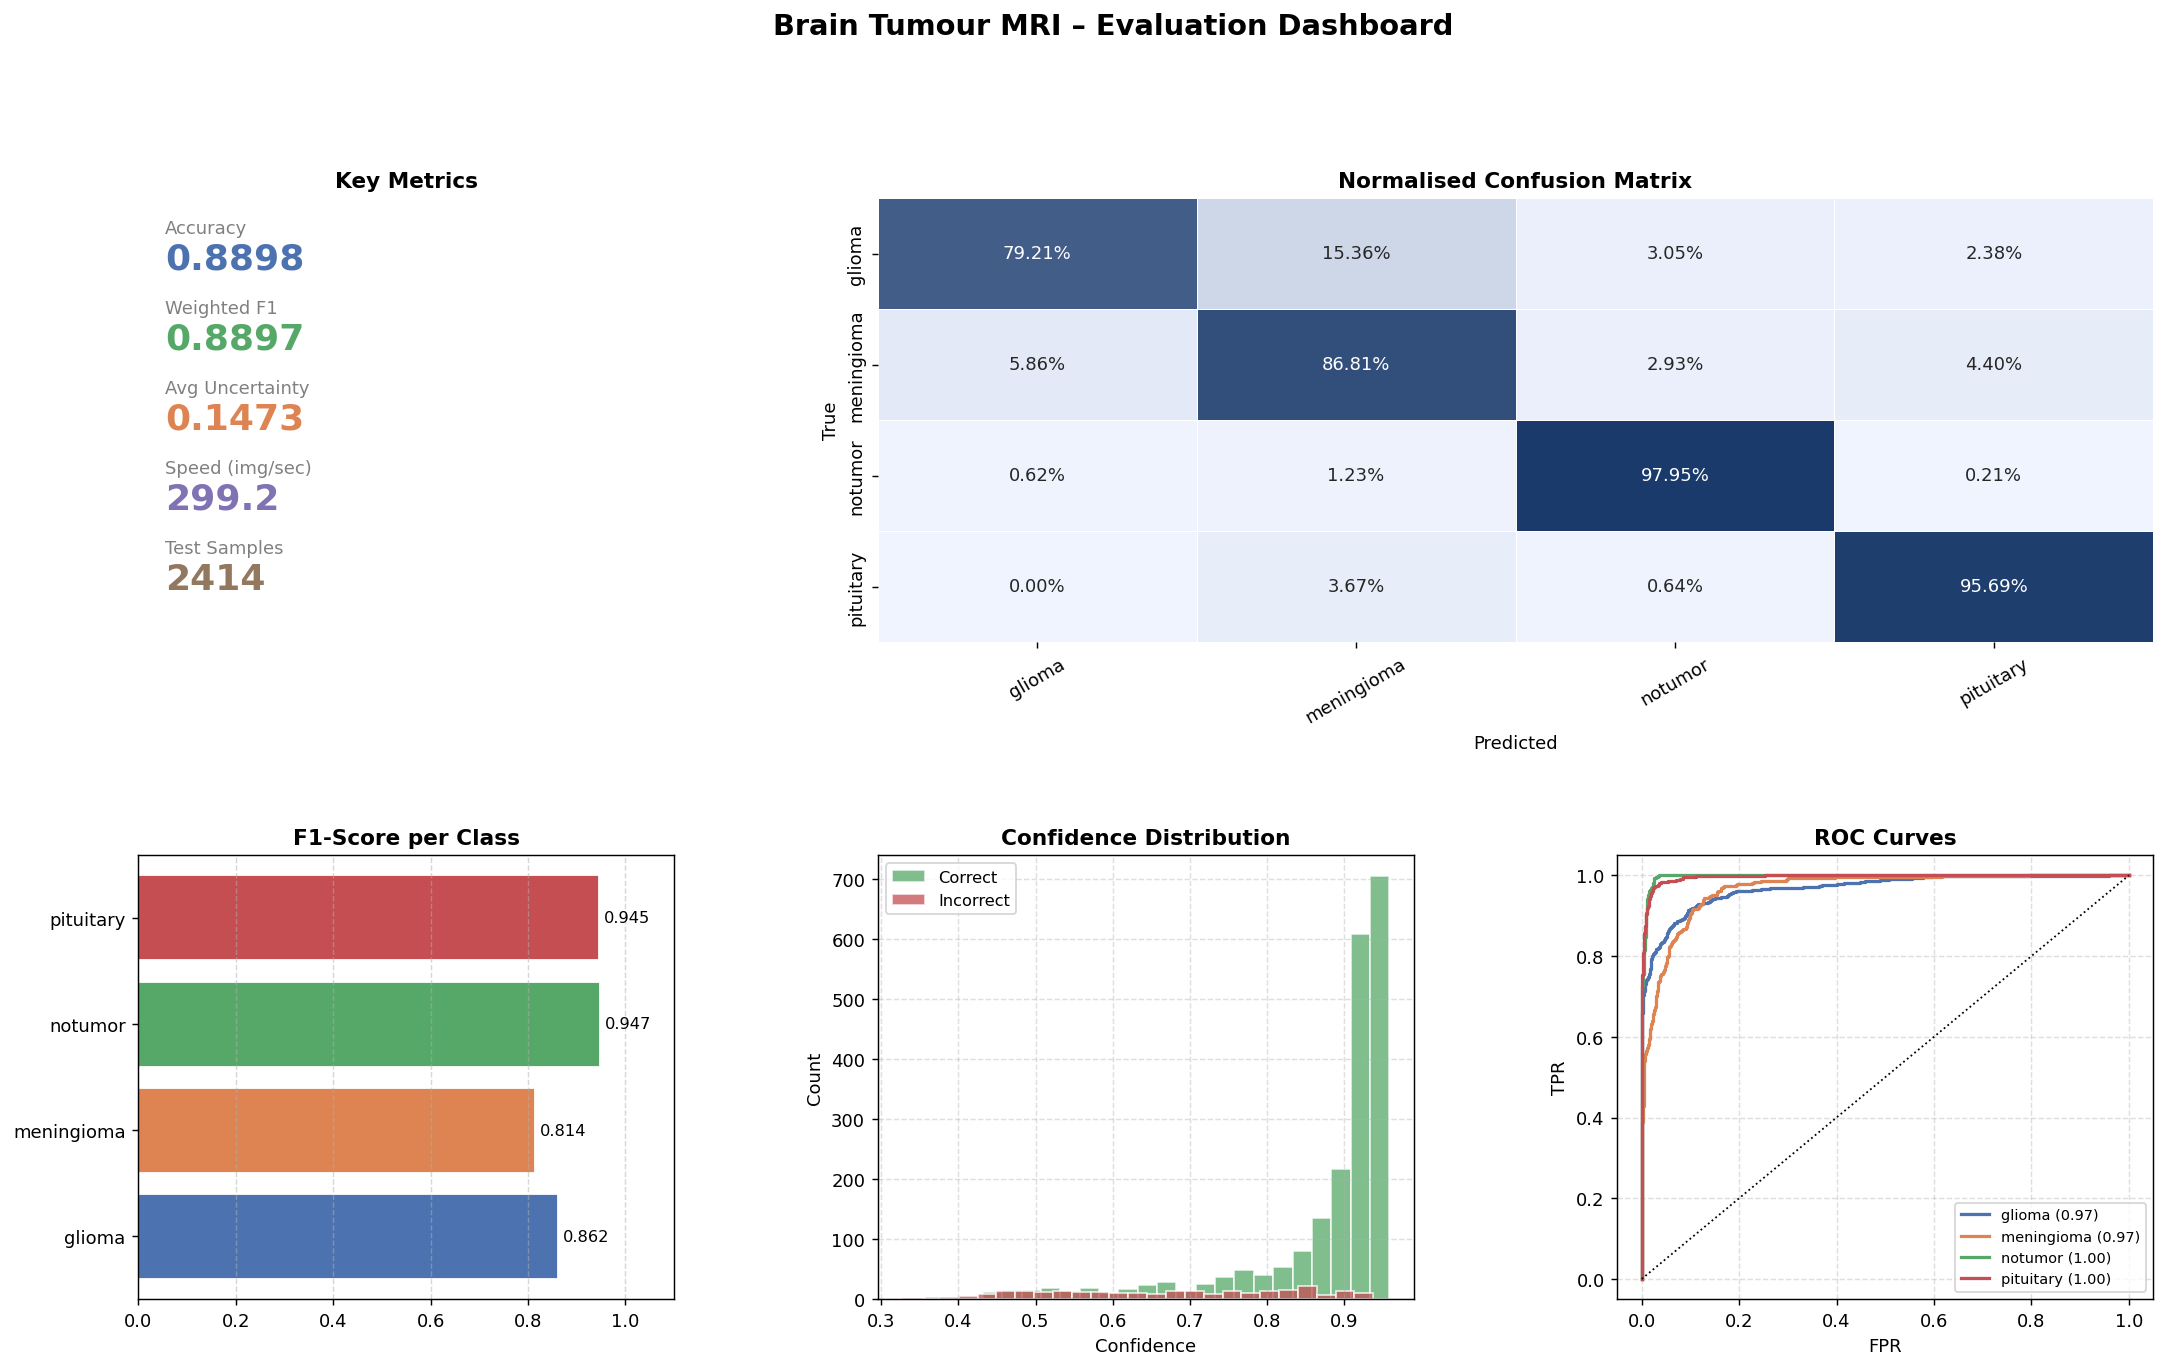

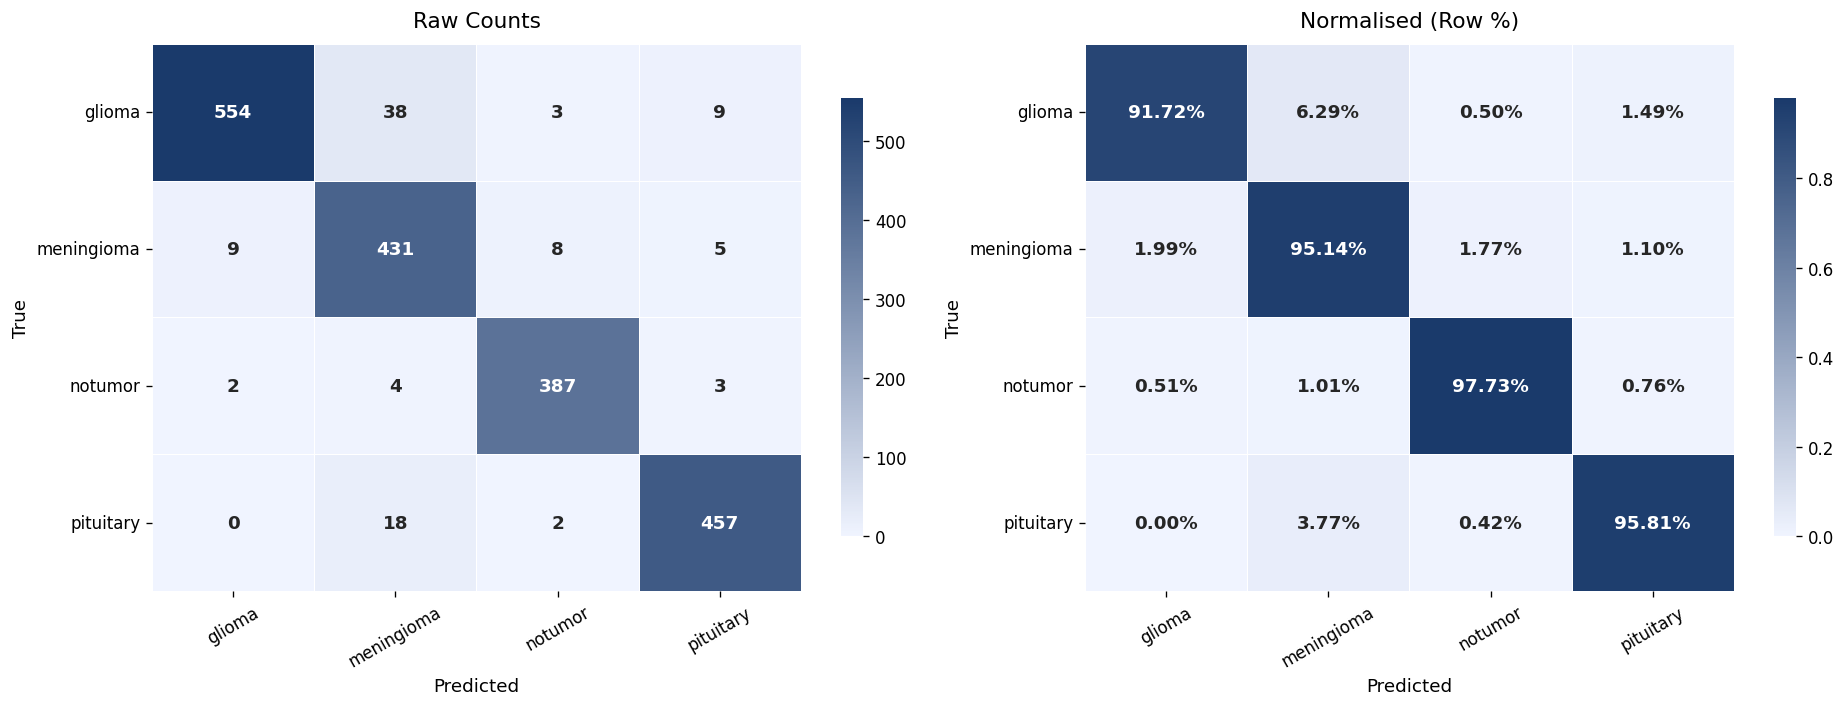

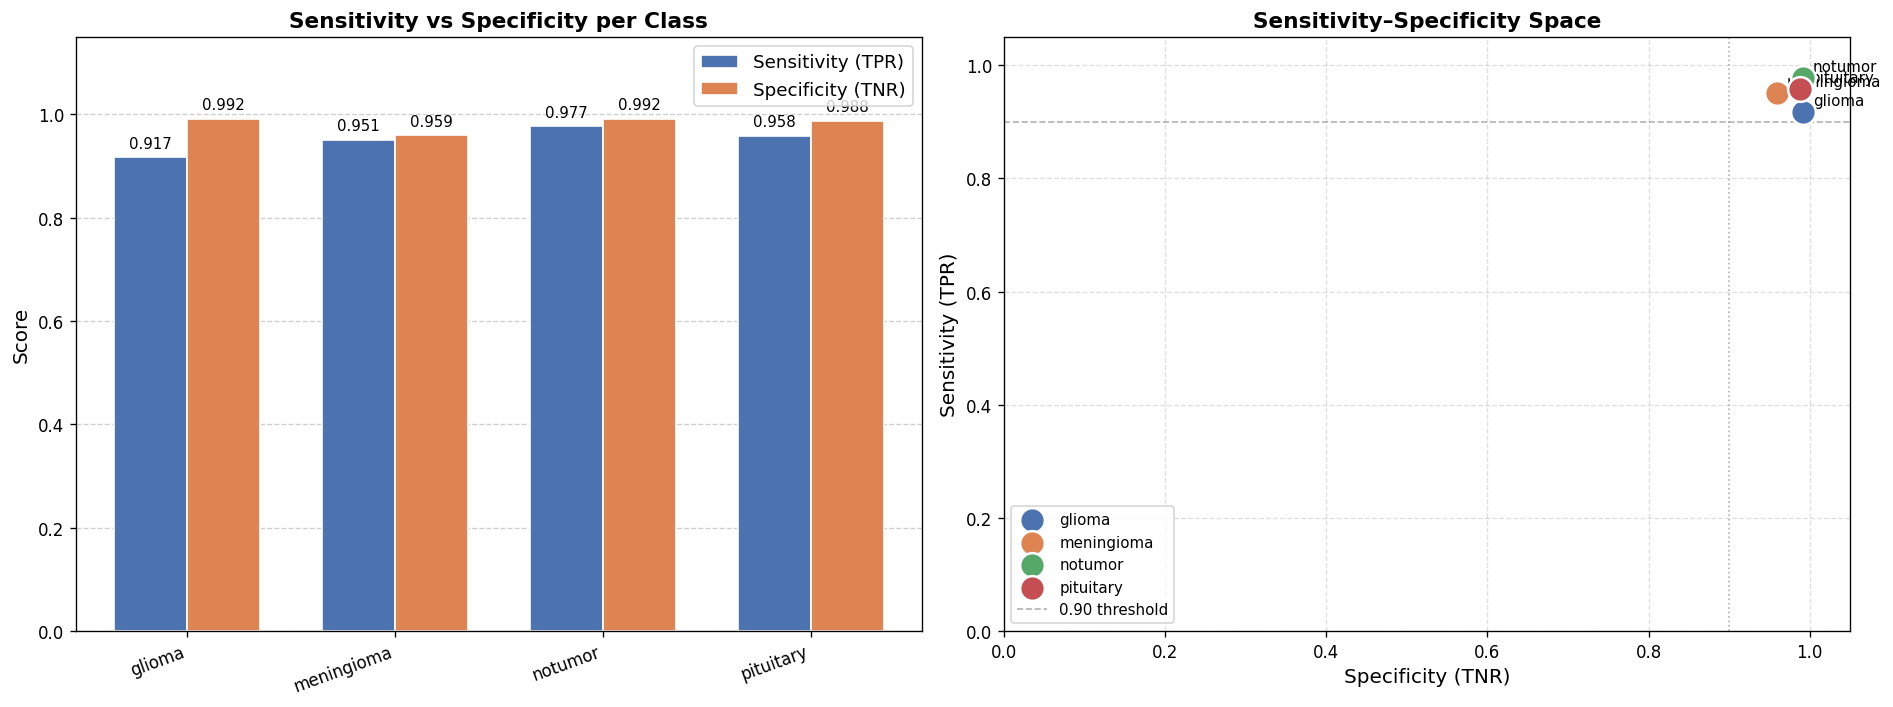

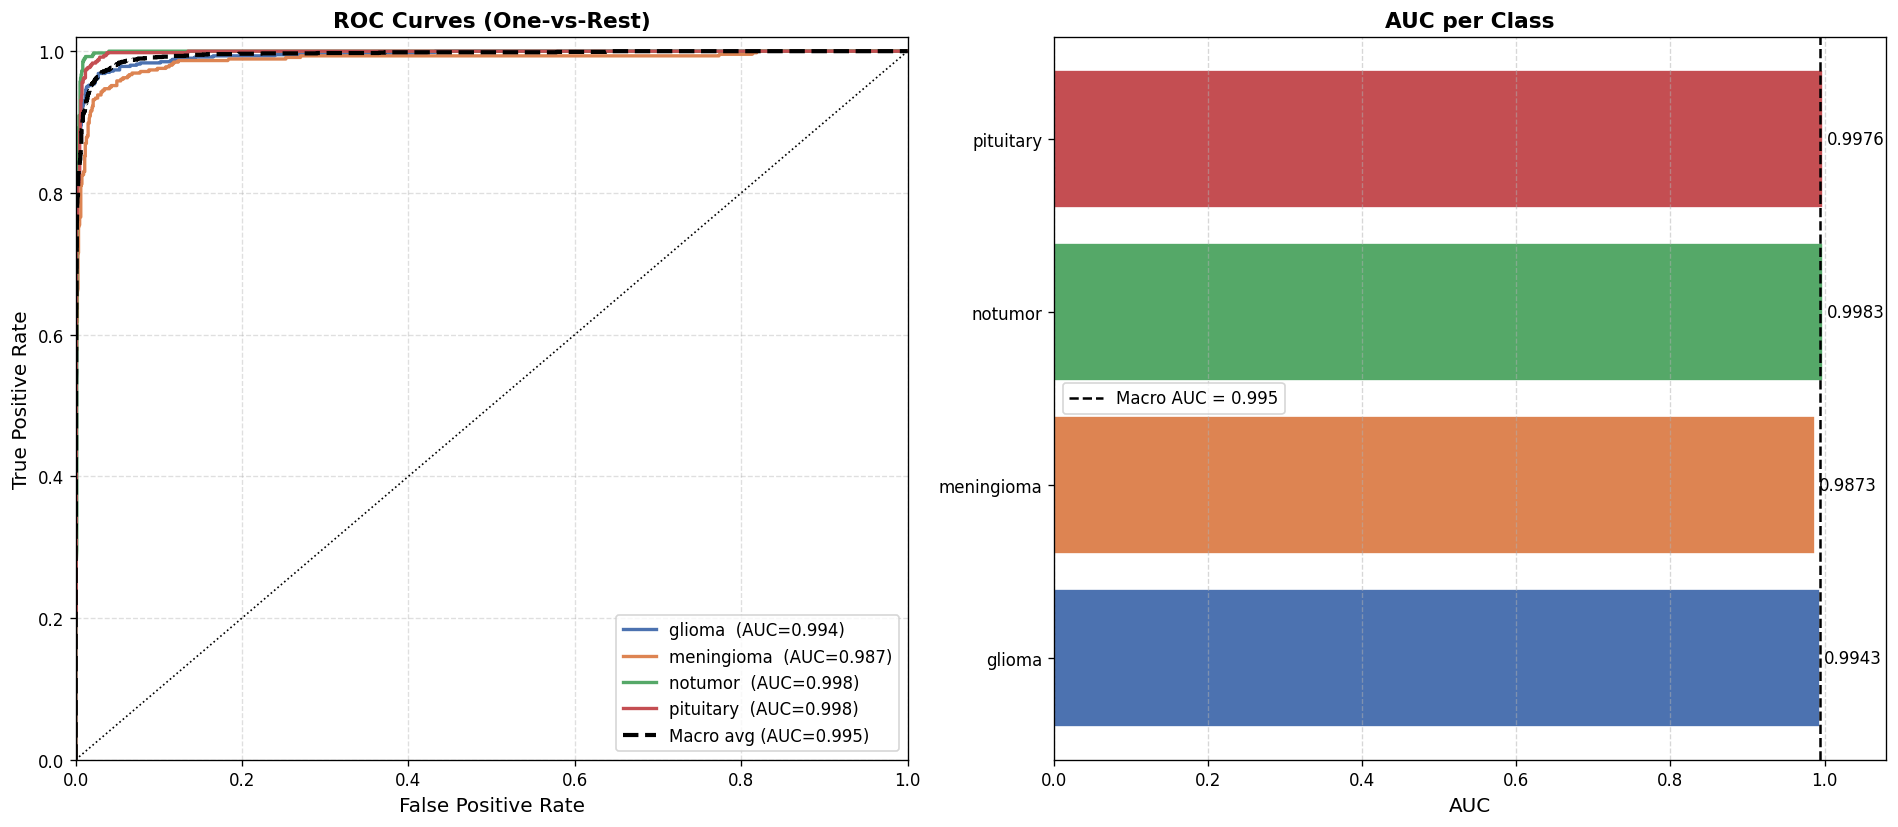

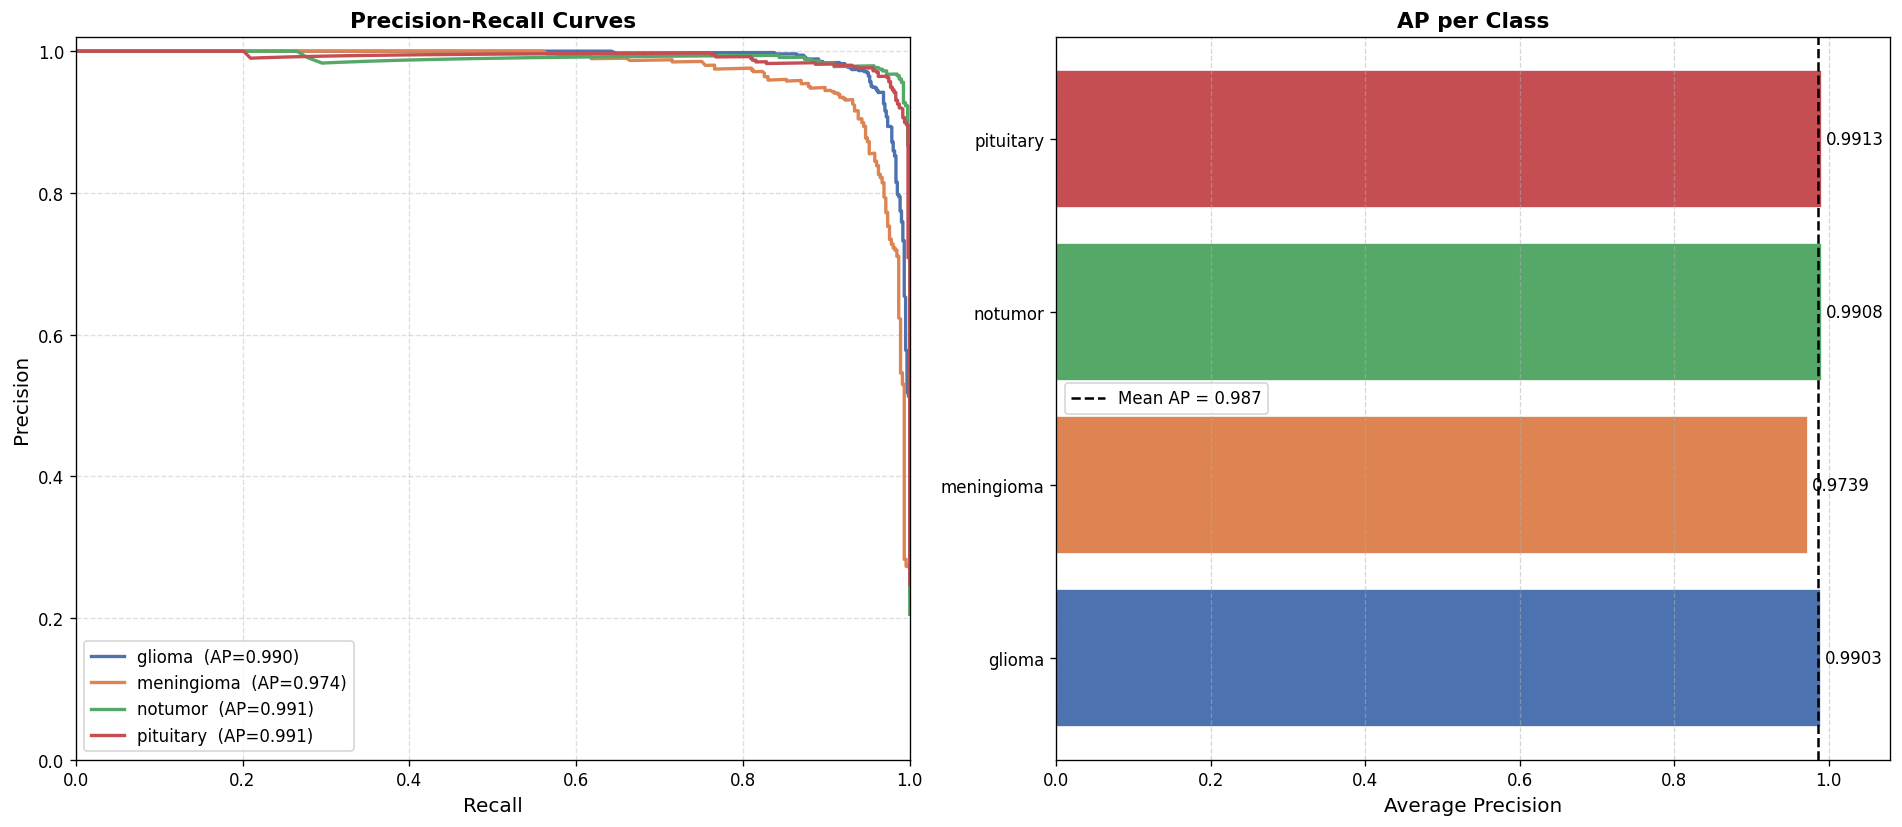

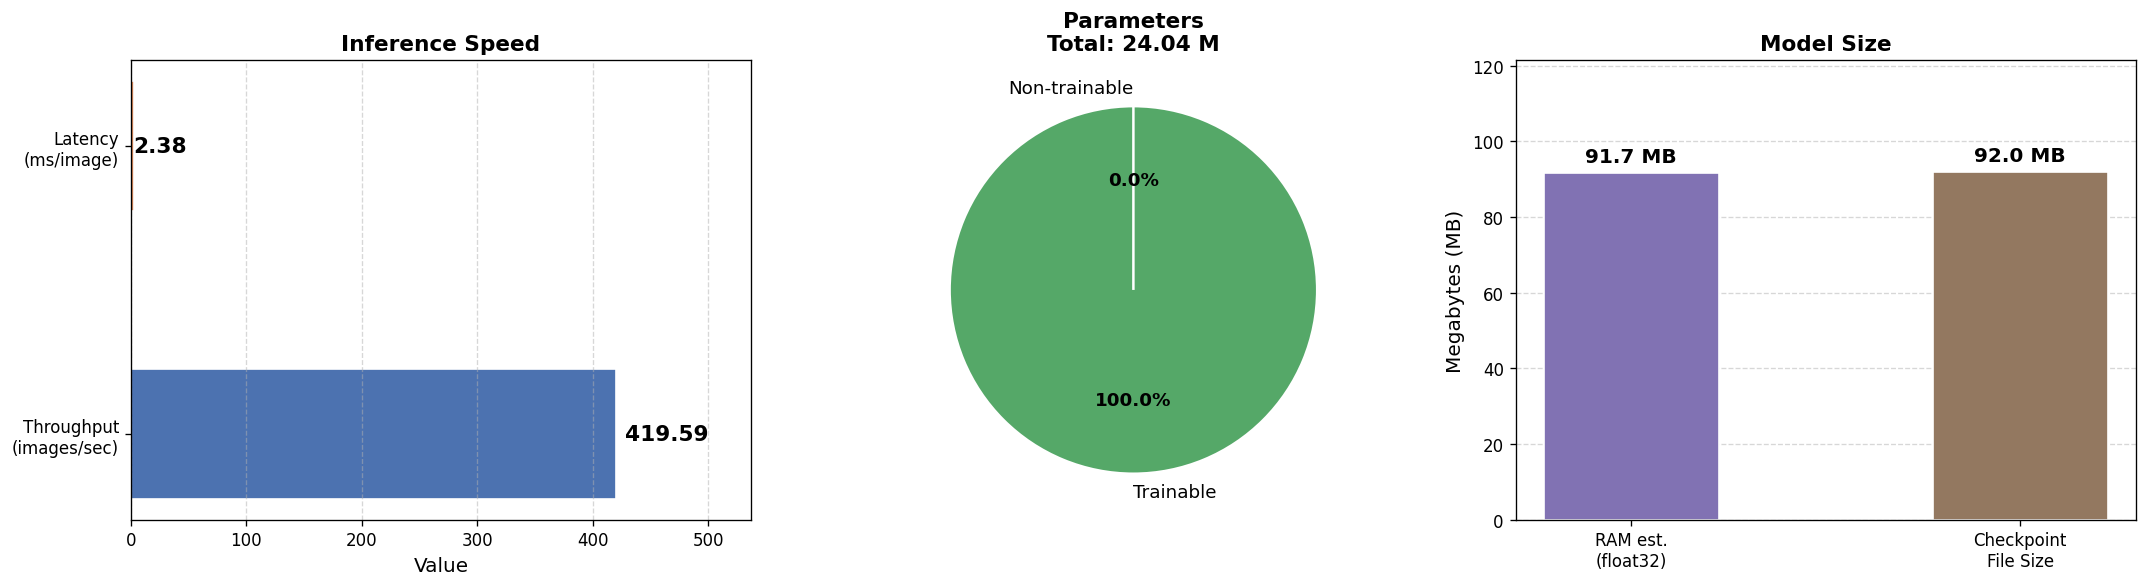

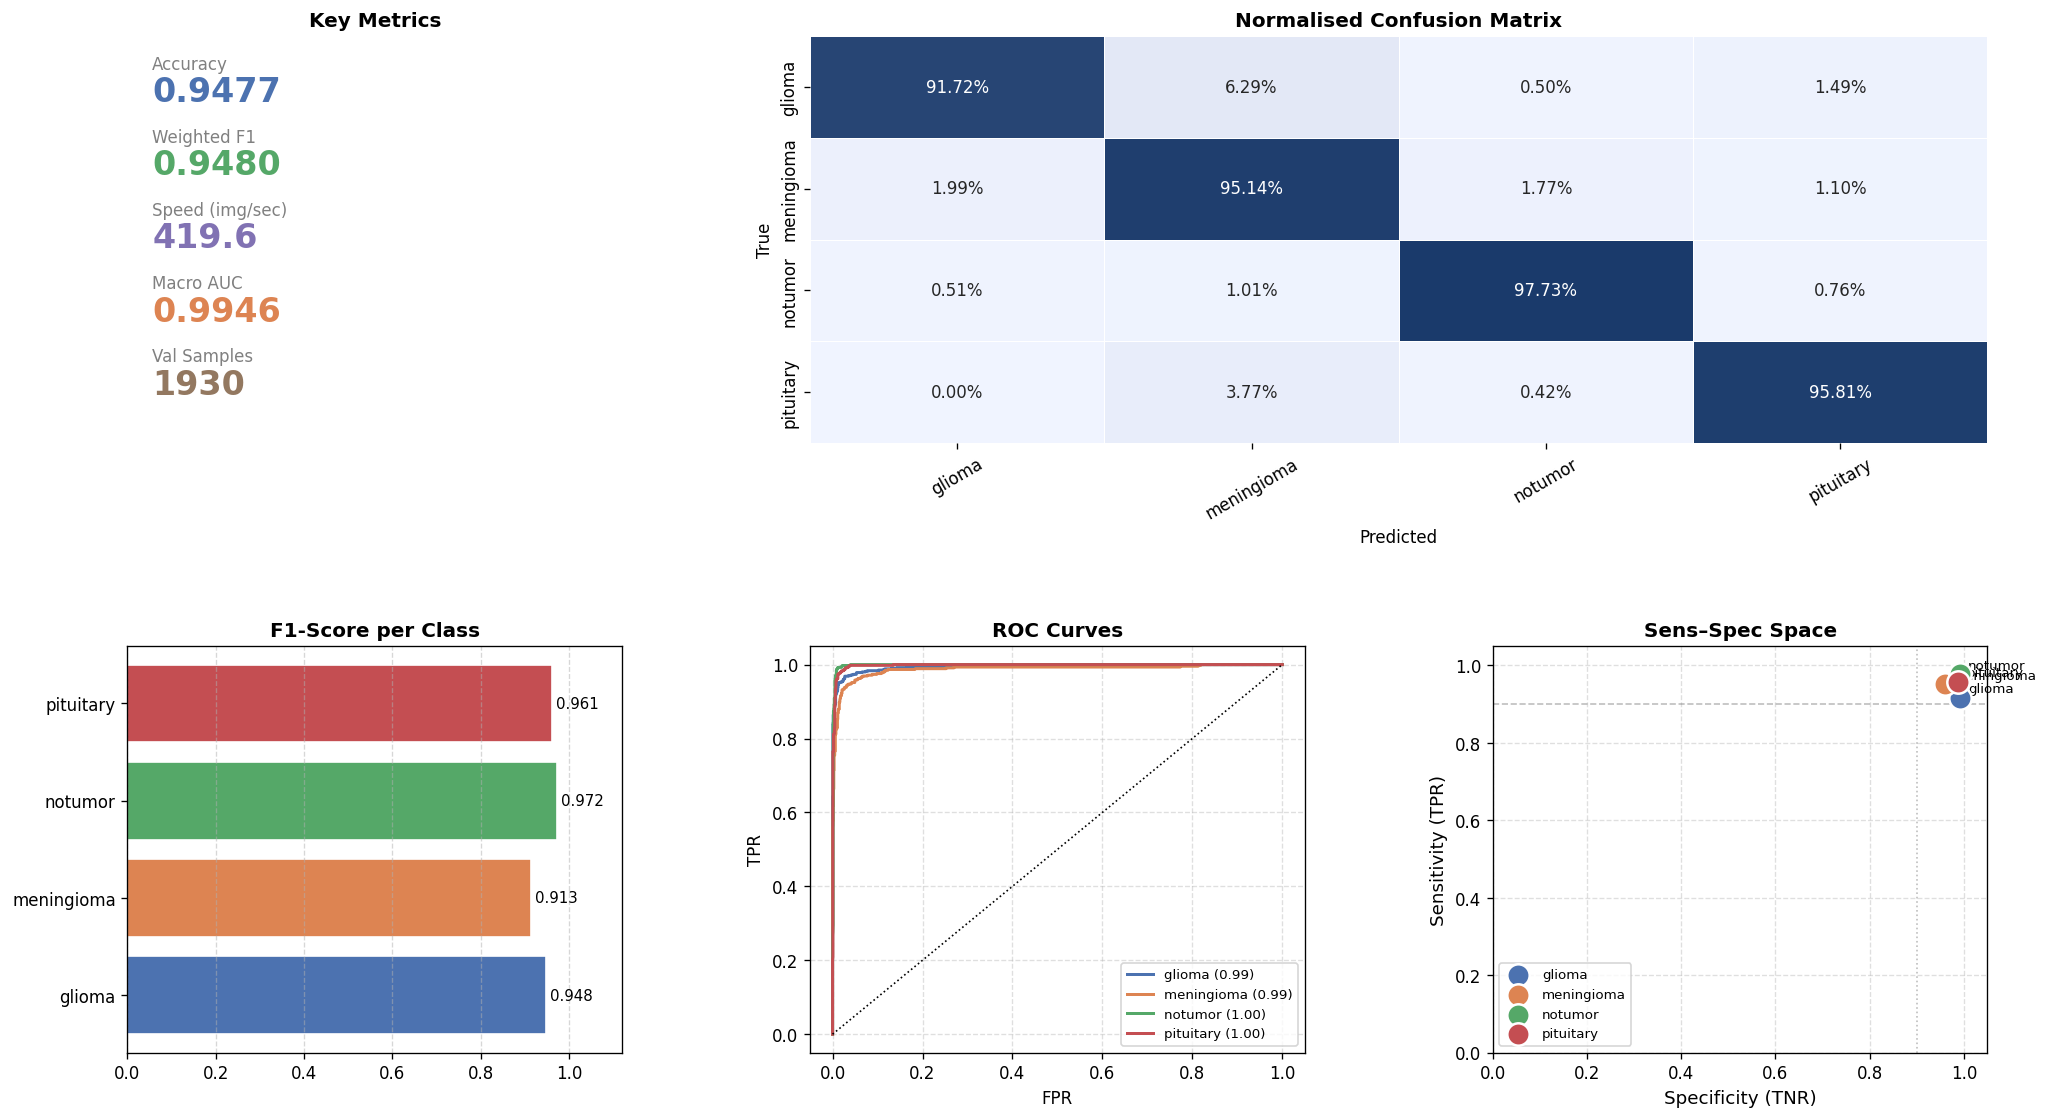

In [6]:
import os
import json
import copy
import time
import random
import numpy as np
from collections import Counter
import logging
from pathlib import Path

# ── Force inline rendering in Kaggle / Jupyter ──────────────────
try:
    from IPython import get_ipython
    _ipy = get_ipython()
    if _ipy is not None:
        _ipy.run_line_magic("matplotlib", "inline")
except Exception:
    pass

import matplotlib
matplotlib.rcParams.update({
    "figure.dpi":       120,
    "figure.facecolor": "white",
    "axes.facecolor":   "white",
})
from IPython.display import display as _ipy_display

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.cuda.amp import GradScaler, autocast
from torch.utils.data import DataLoader, Subset, WeightedRandomSampler
from torchvision import datasets, transforms, models
from sklearn.metrics import (
    classification_report, confusion_matrix,
    accuracy_score, f1_score, roc_curve, auc,
    precision_recall_curve, average_precision_score,
    precision_score, recall_score,
)
from sklearn.preprocessing import label_binarize
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.colors import LinearSegmentedColormap
import seaborn as sns
from tqdm.auto import tqdm


try:
    import timm
    TIMM_AVAILABLE = True
except ImportError:
    TIMM_AVAILABLE = False
    print("⚠️  timm not available. Will use torchvision models as fallback.")

logging.basicConfig(level=logging.INFO)
logger = logging.getLogger(__name__)


# =========================
# Config
# =========================
TRAIN_DIR   = "/kaggle/input/datasets/munibanoreen512/second-dataset/Epic and CSCR hospital Dataset/Train"
IMG_SIZE    = 224
BATCH_SIZE  = 64
EPOCHS      = 15
LR          = 1e-3
WEIGHT_DECAY = 1e-4
VAL_SPLIT   = 0.2
NUM_WORKERS = 4
SEED        = 42
PATIENCE    = 8

MODEL_PATH       = "best_brain_tumor_model.pth"
HISTORY_PATH     = "history_brain_tumor.json"
CLASS_NAMES_PATH = "class_names.json"

DEVICE  = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = torch.cuda.is_available()

MODEL_LOADING_STRATEGY = "torchvision"

PALETTE = ["#4C72B0", "#DD8452", "#55A868", "#C44E52",
           "#8172B3", "#937860", "#DA8BC3", "#8C8C8C"]


# =========================
# Seed
# =========================
def set_seed(seed: int = 42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = True

set_seed(SEED)


# =========================
# Transforms
# =========================
train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(p=0.2),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.1),
    transforms.RandomAffine(degrees=0, translate=(0.1, 0.1)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
    transforms.RandomErasing(p=0.2, scale=(0.02, 0.1)),
])

val_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])


# =========================
# Dataset
# =========================
full_dataset = datasets.ImageFolder(TRAIN_DIR)
class_names  = full_dataset.classes
num_classes  = len(class_names)

print(f"Classes      : {class_names}")
print(f"Total images : {len(full_dataset)}")
print(f"Device       : {DEVICE}  |  AMP: {USE_AMP}")

with open(CLASS_NAMES_PATH, "w") as f:
    json.dump(class_names, f)

indices       = np.arange(len(full_dataset))
np.random.shuffle(indices)
val_size      = int(len(indices) * VAL_SPLIT)
val_indices   = indices[:val_size]
train_indices = indices[val_size:]

train_dataset = copy.deepcopy(full_dataset)
val_dataset   = copy.deepcopy(full_dataset)
train_dataset.transform = train_transform
val_dataset.transform   = val_transform

train_subset = Subset(train_dataset, train_indices)
val_subset   = Subset(val_dataset,   val_indices)

train_targets  = [full_dataset.samples[i][1] for i in train_indices]
class_counts   = Counter(train_targets)
class_weights  = {cls: 1.0 / cnt for cls, cnt in class_counts.items()}
sample_weights = [class_weights[lbl] for lbl in train_targets]
sampler = WeightedRandomSampler(sample_weights, len(sample_weights), replacement=True)

PIN_MEMORY = torch.cuda.is_available()

train_loader = DataLoader(
    train_subset, batch_size=BATCH_SIZE, sampler=sampler,
    num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY,
    persistent_workers=(NUM_WORKERS > 0),
    prefetch_factor=2 if NUM_WORKERS > 0 else None,
)
val_loader = DataLoader(
    val_subset, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY,
    persistent_workers=(NUM_WORKERS > 0),
    prefetch_factor=2 if NUM_WORKERS > 0 else None,
)


# =========================
# Models
# =========================
class BrainTumorModel(nn.Module):
    def __init__(self, num_classes: int, backbone: str = "efficientnet_b3"):
        super().__init__()
        self.backbone = timm.create_model(
            backbone, pretrained=True, num_classes=0, global_pool="avg")
        feat_dim = self.backbone.num_features
        self.head = nn.Sequential(
            nn.LayerNorm(feat_dim), nn.Dropout(0.3),
            nn.Linear(feat_dim, 256), nn.GELU(),
            nn.Dropout(0.2), nn.Linear(256, num_classes),
        )

    def forward(self, x):
        return self.head(self.backbone(x))


class BrainTumorModelTorchvision(nn.Module):
    def __init__(self, num_classes: int, use_pretrained: bool = False):
        super().__init__()
        try:
            self.backbone = models.resnet50(
                weights=None if not use_pretrained else "DEFAULT")
        except Exception:
            self.backbone = models.resnet50(weights=None)
        feat_dim = self.backbone.fc.in_features
        self.backbone.fc = nn.Identity()
        self.head = nn.Sequential(
            nn.LayerNorm(feat_dim), nn.Dropout(0.3),
            nn.Linear(feat_dim, 256), nn.GELU(),
            nn.Dropout(0.2), nn.Linear(256, num_classes),
        )

    def forward(self, x):
        return self.head(self.backbone(x))


def create_model(num_classes: int, strategy: str = "timm") -> nn.Module:
    try:
        if strategy == "timm" and TIMM_AVAILABLE:
            logger.info("📦 Loading EfficientNet-B3 from timm...")
            model = BrainTumorModel(num_classes=num_classes)
            logger.info("✅ EfficientNet-B3 loaded successfully")
            return model
        elif strategy in ("torchvision", "local") or (strategy == "timm" and not TIMM_AVAILABLE):
            logger.warning("⚠️  Using ResNet50 (no pretrained weights)")
            model = BrainTumorModelTorchvision(num_classes=num_classes, use_pretrained=False)
            logger.info("✅ ResNet50 created")
            return model
    except Exception as e:
        logger.error(f"❌ Error: {e}")
        model = BrainTumorModelTorchvision(num_classes=num_classes, use_pretrained=False)
        return model


print(f"\n🔧 Model Loading Strategy: {MODEL_LOADING_STRATEGY}")
model = create_model(num_classes=num_classes, strategy=MODEL_LOADING_STRATEGY).to(DEVICE)

try:
    model = torch.compile(model)
    print("⚡ torch.compile() enabled ✓")
except Exception:
    print("ℹ️  torch.compile() not available, running eager mode.")

criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
optimizer = optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS, eta_min=1e-6)
scaler    = GradScaler(enabled=USE_AMP)


# =========================
# Train / Validate helpers
# =========================
def train_one_epoch(model, loader, criterion, optimizer, scaler, device, epoch, total_epochs):
    model.train()
    running_loss = 0.0
    all_labels, all_preds = [], []
    pbar = tqdm(loader, desc=f"Epoch {epoch}/{total_epochs} [Train]", leave=False)
    for images, labels in pbar:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        with autocast(enabled=USE_AMP):
            logits = model(images)
            loss   = criterion(logits, labels)
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        scaler.step(optimizer)
        scaler.update()
        running_loss += loss.item() * images.size(0)
        preds = logits.argmax(dim=1)
        all_labels.extend(labels.cpu().numpy())
        all_preds.extend(preds.cpu().numpy())
        pbar.set_postfix(loss=f"{loss.item():.4f}",
                         acc=f"{(preds == labels).float().mean().item():.4f}")
    epoch_loss = running_loss / len(loader.dataset)
    return epoch_loss, accuracy_score(all_labels, all_preds), f1_score(all_labels, all_preds, average="weighted")


@torch.no_grad()
def evaluate(model, loader, criterion, device, epoch, total_epochs, return_probs=False):
    model.eval()
    running_loss = 0.0
    all_labels, all_preds, all_probs = [], [], []
    pbar = tqdm(loader, desc=f"Epoch {epoch}/{total_epochs} [Val]  ", leave=False)
    for images, labels in pbar:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)
        with autocast(enabled=USE_AMP):
            logits = model(images)
            loss   = criterion(logits, labels)
        running_loss += loss.item() * images.size(0)
        probs = F.softmax(logits, dim=1)
        preds = logits.argmax(dim=1)
        all_labels.extend(labels.cpu().numpy())
        all_preds.extend(preds.cpu().numpy())
        all_probs.extend(probs.cpu().numpy())
        pbar.set_postfix(loss=f"{loss.item():.4f}",
                         acc=f"{(preds == labels).float().mean().item():.4f}")
    epoch_loss = running_loss / len(loader.dataset)
    all_labels = np.array(all_labels)
    all_preds  = np.array(all_preds)
    all_probs  = np.array(all_probs)
    if return_probs:
        return epoch_loss, accuracy_score(all_labels, all_preds), f1_score(all_labels, all_preds, average="weighted"), all_labels, all_preds, all_probs
    return epoch_loss, accuracy_score(all_labels, all_preds), f1_score(all_labels, all_preds, average="weighted"), all_labels, all_preds


# =========================
# Training loop
# =========================
best_acc       = 0.0
best_model_wts = copy.deepcopy(model.state_dict())
no_improve     = 0

history = {k: [] for k in ["train_loss", "train_acc", "train_f1",
                             "val_loss",   "val_acc",   "val_f1"]}

epoch_bar = tqdm(range(1, EPOCHS + 1), desc="Training Progress")

for epoch in epoch_bar:
    train_loss, train_acc, train_f1 = train_one_epoch(
        model, train_loader, criterion, optimizer, scaler, DEVICE, epoch, EPOCHS)
    val_loss, val_acc, val_f1, y_true, y_pred = evaluate(
        model, val_loader, criterion, DEVICE, epoch, EPOCHS)
    scheduler.step()

    history["train_loss"].append(train_loss)
    history["train_acc"].append(train_acc)
    history["train_f1"].append(train_f1)
    history["val_loss"].append(val_loss)
    history["val_acc"].append(val_acc)
    history["val_f1"].append(val_f1)

    if val_acc > best_acc:
        best_acc       = val_acc
        best_model_wts = copy.deepcopy(model.state_dict())
        torch.save({"model_state_dict": model.state_dict(),
                    "class_names": class_names,
                    "num_classes": num_classes}, MODEL_PATH)
        no_improve = 0
    else:
        no_improve += 1

    lr_now = optimizer.param_groups[0]["lr"]
    epoch_bar.set_postfix({
        "lr": f"{lr_now:.6f}", "train_acc": f"{train_acc:.4f}",
        "val_acc": f"{val_acc:.4f}", "val_f1": f"{val_f1:.4f}",
        "patience": f"{no_improve}/{PATIENCE}",
    })
    print(
        f"\nEpoch [{epoch}/{EPOCHS}] | LR: {lr_now:.6f} | "
        f"Train → loss:{train_loss:.4f}  acc:{train_acc:.4f}  f1:{train_f1:.4f} | "
        f"Val   → loss:{val_loss:.4f}  acc:{val_acc:.4f}  f1:{val_f1:.4f}"
    )
    if no_improve >= PATIENCE:
        print(f"\n⏹  Early stopping triggered after {PATIENCE} epochs without improvement.")
        break

with open(HISTORY_PATH, "w") as f:
    json.dump(history, f, indent=2)


# =========================
# Final evaluation (best weights, with probs for plots)
# =========================
model.load_state_dict(best_model_wts)

# ── Warm-up then timed inference ──
with torch.no_grad():
    warmup_imgs, _ = next(iter(val_loader))
    _ = model(warmup_imgs.to(DEVICE))
if DEVICE.type == "cuda":
    torch.cuda.synchronize()

t0 = time.perf_counter()
_, val_acc, val_f1, all_labels, all_preds, all_probs = evaluate(
    model, val_loader, criterion, DEVICE, EPOCHS, EPOCHS, return_probs=True)
if DEVICE.type == "cuda":
    torch.cuda.synchronize()
t1 = time.perf_counter()

n_val           = len(all_labels)
total_time      = t1 - t0
imgs_per_second = n_val / total_time
ms_per_image    = total_time / n_val * 1000

total_params     = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

print("\n" + "=" * 60)
print(f"✅  Best Validation Accuracy : {best_acc:.4f}")
print("=" * 60)
print("\nClassification Report:")
print(classification_report(all_labels, all_preds, target_names=class_names, digits=4))
print("Confusion Matrix:")
print(confusion_matrix(all_labels, all_preds))
print(f"\nBest model  → {MODEL_PATH}")
print(f"History     → {HISTORY_PATH}")


# ═══════════════════════════════════════════════════════════════
#  HELPER
# ═══════════════════════════════════════════════════════════════
def _sens_spec(y_true, y_pred, n):
    sens, spec = [], []
    for c in range(n):
        tp = int(((y_true == c) & (y_pred == c)).sum())
        fn = int(((y_true == c) & (y_pred != c)).sum())
        tn = int(((y_true != c) & (y_pred != c)).sum())
        fp = int(((y_true != c) & (y_pred == c)).sum())
        sens.append(tp / (tp + fn + 1e-8))
        spec.append(tn / (tn + fp + 1e-8))
    return np.array(sens), np.array(spec)


# ═══════════════════════════════════════════════════════════════
#  PLOT 1 – Confusion Matrix  (raw + normalised)
# ═══════════════════════════════════════════════════════════════
cmap_blue = LinearSegmentedColormap.from_list("cb", ["#f0f4ff", "#1a3a6b"])
cm      = confusion_matrix(all_labels, all_preds)
cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, data, title, fmt in zip(
    axes, [cm, cm_norm], ["Raw Counts", "Normalised (Row %)"], ["d", ".2%"]
):
    sns.heatmap(data, annot=True, fmt=fmt, cmap=cmap_blue,
                xticklabels=class_names, yticklabels=class_names,
                linewidths=0.5, linecolor="white",
                annot_kws={"size": 11, "weight": "bold"},
                ax=ax, cbar_kws={"shrink": 0.8})
    ax.set_title(title, fontsize=13, pad=10)
    ax.set_xlabel("Predicted", fontsize=11)
    ax.set_ylabel("True",      fontsize=11)
    ax.tick_params(axis="x", rotation=30)
    ax.tick_params(axis="y", rotation=0)
plt.tight_layout()
_ipy_display(fig)
plt.close(fig)


# ═══════════════════════════════════════════════════════════════
#  PLOT 2 – Per-class Sensitivity & Specificity
# ═══════════════════════════════════════════════════════════════
sens, spec = _sens_spec(all_labels, all_preds, num_classes)
x = np.arange(num_classes); w = 0.35

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

ax = axes[0]
b1 = ax.bar(x - w/2, sens, w, label="Sensitivity (TPR)", color="#4C72B0", edgecolor="white")
b2 = ax.bar(x + w/2, spec, w, label="Specificity (TNR)", color="#DD8452", edgecolor="white")
for bars in (b1, b2):
    for bar in bars:
        h = bar.get_height()
        ax.annotate(f"{h:.3f}", xy=(bar.get_x() + bar.get_width()/2, h),
                    xytext=(0, 4), textcoords="offset points",
                    ha="center", va="bottom", fontsize=9)
ax.set_xticks(x); ax.set_xticklabels(class_names, fontsize=10, rotation=20, ha="right")
ax.set_ylim(0, 1.15); ax.set_ylabel("Score", fontsize=12)
ax.set_title("Sensitivity vs Specificity per Class", fontsize=13, fontweight="bold")
ax.legend(fontsize=11); ax.yaxis.grid(True, linestyle="--", alpha=0.6); ax.set_axisbelow(True)

ax2 = axes[1]
for i, (cls, col) in enumerate(zip(class_names, PALETTE)):
    ax2.scatter(spec[i], sens[i], color=col, s=220, zorder=5,
                label=cls, edgecolors="white", lw=1.5)
    ax2.annotate(cls, (spec[i], sens[i]),
                 textcoords="offset points", xytext=(6, 4), fontsize=9)
ax2.axhline(0.9, color="gray", linestyle="--", lw=1, alpha=0.6, label="0.90 threshold")
ax2.axvline(0.9, color="gray", linestyle=":",  lw=1, alpha=0.6)
ax2.set_xlim(0, 1.05); ax2.set_ylim(0, 1.05)
ax2.set_xlabel("Specificity (TNR)", fontsize=12)
ax2.set_ylabel("Sensitivity (TPR)", fontsize=12)
ax2.set_title("Sensitivity–Specificity Space", fontsize=13, fontweight="bold")
ax2.legend(fontsize=9, loc="lower left"); ax2.grid(True, linestyle="--", alpha=0.4)

plt.tight_layout()
_ipy_display(fig)
plt.close(fig)

# Print table
print(f"\n{'Class':<22} {'Sensitivity':>12} {'Specificity':>12}")
print("-" * 48)
for cls, s, sp in zip(class_names, sens, spec):
    print(f"  {cls:<20} {s:>12.4f} {sp:>12.4f}")
print("-" * 48)
print(f"  {'Macro Average':<20} {sens.mean():>12.4f} {spec.mean():>12.4f}")


# ═══════════════════════════════════════════════════════════════
#  PLOT 3 – ROC Curves  (curves + AUC bar)
# ═══════════════════════════════════════════════════════════════
y_bin = label_binarize(all_labels, classes=list(range(num_classes)))
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

ax  = axes[0]
auc_scores = []
for i, (cls, col) in enumerate(zip(class_names, PALETTE)):
    fpr, tpr, _ = roc_curve(y_bin[:, i], all_probs[:, i])
    roc_auc = auc(fpr, tpr)
    auc_scores.append(roc_auc)
    ax.plot(fpr, tpr, lw=2, color=col, label=f"{cls}  (AUC={roc_auc:.3f})")
fpr_m, tpr_m, _ = roc_curve(y_bin.ravel(), all_probs.ravel())
macro_auc = auc(fpr_m, tpr_m)
ax.plot(fpr_m, tpr_m, lw=2.5, color="black", linestyle="--",
        label=f"Macro avg (AUC={macro_auc:.3f})")
ax.plot([0,1],[0,1],"k:",lw=1)
ax.set_xlim([0,1]); ax.set_ylim([0,1.02])
ax.set_xlabel("False Positive Rate", fontsize=12)
ax.set_ylabel("True Positive Rate",  fontsize=12)
ax.set_title("ROC Curves (One-vs-Rest)", fontsize=13, fontweight="bold")
ax.legend(loc="lower right", fontsize=10); ax.grid(True, linestyle="--", alpha=0.4)

ax2 = axes[1]
bars = ax2.barh(class_names, auc_scores, color=PALETTE[:num_classes], edgecolor="white")
ax2.axvline(macro_auc, color="black", lw=1.5, linestyle="--",
            label=f"Macro AUC = {macro_auc:.3f}")
for bar, val in zip(bars, auc_scores):
    ax2.text(val + 0.005, bar.get_y() + bar.get_height()/2,
             f"{val:.4f}", va="center", fontsize=10)
ax2.set_xlim(0, 1.08)
ax2.set_xlabel("AUC", fontsize=12)
ax2.set_title("AUC per Class", fontsize=13, fontweight="bold")
ax2.legend(fontsize=10); ax2.grid(axis="x", linestyle="--", alpha=0.5)

plt.tight_layout()
_ipy_display(fig)
plt.close(fig)


# ═══════════════════════════════════════════════════════════════
#  PLOT 4 – Precision-Recall Curves  (curves + AP bar)
# ═══════════════════════════════════════════════════════════════
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

ax  = axes[0]
ap_scores = []
for i, (cls, col) in enumerate(zip(class_names, PALETTE)):
    prec_c, rec_c, _ = precision_recall_curve(y_bin[:, i], all_probs[:, i])
    ap = average_precision_score(y_bin[:, i], all_probs[:, i])
    ap_scores.append(ap)
    ax.plot(rec_c, prec_c, lw=2, color=col, label=f"{cls}  (AP={ap:.3f})")
ax.set_xlabel("Recall", fontsize=12); ax.set_ylabel("Precision", fontsize=12)
ax.set_title("Precision-Recall Curves", fontsize=13, fontweight="bold")
ax.legend(loc="lower left", fontsize=10)
ax.set_xlim([0,1]); ax.set_ylim([0,1.02]); ax.grid(True, linestyle="--", alpha=0.4)

ax2 = axes[1]
macro_ap = np.mean(ap_scores)
bars = ax2.barh(class_names, ap_scores, color=PALETTE[:num_classes], edgecolor="white")
ax2.axvline(macro_ap, color="black", lw=1.5, linestyle="--",
            label=f"Mean AP = {macro_ap:.3f}")
for bar, val in zip(bars, ap_scores):
    ax2.text(val + 0.005, bar.get_y() + bar.get_height()/2,
             f"{val:.4f}", va="center", fontsize=10)
ax2.set_xlim(0, 1.08)
ax2.set_xlabel("Average Precision", fontsize=12)
ax2.set_title("AP per Class", fontsize=13, fontweight="bold")
ax2.legend(fontsize=10); ax2.grid(axis="x", linestyle="--", alpha=0.5)

plt.tight_layout()
_ipy_display(fig)
plt.close(fig)


# ═══════════════════════════════════════════════════════════════
#  PLOT 5 – Inference Speed & Model Size
# ═══════════════════════════════════════════════════════════════
param_mb = total_params * 4 / (1024 ** 2)
file_mb  = os.path.getsize(MODEL_PATH) / (1024 ** 2) if os.path.exists(MODEL_PATH) else None

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Speed bars
ax = axes[0]
cats   = ["Throughput\n(images/sec)", "Latency\n(ms/image)"]
vals   = [imgs_per_second, ms_per_image]
colors = ["#4C72B0", "#DD8452"]
bars   = ax.barh(cats, vals, color=colors, edgecolor="white", height=0.45)
for bar, val in zip(bars, vals):
    ax.text(val * 1.02, bar.get_y() + bar.get_height()/2,
            f"{val:.2f}", va="center", fontsize=13, fontweight="bold")
ax.set_xlabel("Value", fontsize=12)
ax.set_title("Inference Speed", fontsize=13, fontweight="bold")
ax.grid(axis="x", linestyle="--", alpha=0.5)
ax.set_xlim(0, max(vals) * 1.28)

# Parameter pie
ax2 = axes[1]
non_trainable = total_params - trainable_params
wedges, texts, autotexts = ax2.pie(
    [trainable_params, non_trainable],
    labels=["Trainable", "Non-trainable"],
    colors=["#55A868", "#C44E52"],
    autopct="%1.1f%%", startangle=90,
    textprops={"fontsize": 11},
    wedgeprops={"edgecolor": "white", "linewidth": 1.5})
for a in autotexts:
    a.set_fontweight("bold")
ax2.set_title(f"Parameters\nTotal: {total_params/1e6:.2f} M",
              fontsize=13, fontweight="bold")

# Disk vs RAM
ax3 = axes[2]
size_labels = ["RAM est.\n(float32)"]
size_vals   = [param_mb]
size_colors = ["#8172B3"]
if file_mb is not None:
    size_labels.append("Checkpoint\nFile Size")
    size_vals.append(file_mb)
    size_colors.append("#937860")
bars3 = ax3.bar(size_labels, size_vals, color=size_colors, edgecolor="white", width=0.45)
for bar, val in zip(bars3, size_vals):
    ax3.text(bar.get_x() + bar.get_width()/2, val + max(size_vals)*0.02,
             f"{val:.1f} MB", ha="center", va="bottom",
             fontsize=12, fontweight="bold")
ax3.set_ylabel("Megabytes (MB)", fontsize=12)
ax3.set_title("Model Size", fontsize=13, fontweight="bold")
ax3.yaxis.grid(True, linestyle="--", alpha=0.5); ax3.set_axisbelow(True)
ax3.set_ylim(0, max(size_vals) * 1.32)

plt.tight_layout()
_ipy_display(fig)
plt.close(fig)

# Speed + size summary
print(f"\n{'='*52}")
print(f"  Throughput        : {imgs_per_second:.1f} images / sec")
print(f"  Latency per image : {ms_per_image:.2f} ms")
print(f"  Total parameters  : {total_params/1e6:.3f} M")
print(f"  Trainable params  : {trainable_params/1e6:.3f} M")
print(f"  Float32 RAM est.  : {param_mb:.1f} MB")
if file_mb:
    print(f"  Checkpoint file   : {file_mb:.1f} MB")
print(f"{'='*52}")


# ═══════════════════════════════════════════════════════════════
#  PLOT 6 – Summary Dashboard
# ═══════════════════════════════════════════════════════════════
f1_per_class = f1_score(all_labels, all_preds, average=None, zero_division=0)
acc_final    = accuracy_score(all_labels, all_preds)
wf1_final    = f1_score(all_labels, all_preds, average="weighted")

fig = plt.figure(figsize=(20, 11))
gs  = gridspec.GridSpec(2, 3, figure=fig, hspace=0.5, wspace=0.38)

# KPIs
ax_kpi = fig.add_subplot(gs[0, 0]); ax_kpi.axis("off")
kpis   = [
    ("Accuracy",         f"{acc_final:.4f}",       "#4C72B0"),
    ("Weighted F1",      f"{wf1_final:.4f}",        "#55A868"),
    ("Speed (img/sec)",  f"{imgs_per_second:.1f}",  "#8172B3"),
    ("Macro AUC",        f"{macro_auc:.4f}",        "#DD8452"),
    ("Val Samples",      str(n_val),                "#937860"),
]
y_pos = 0.92
for label, value, color in kpis:
    ax_kpi.text(0.05, y_pos,        label, transform=ax_kpi.transAxes, fontsize=10, color="grey")
    ax_kpi.text(0.05, y_pos - 0.08, value, transform=ax_kpi.transAxes,
                fontsize=20, fontweight="bold", color=color)
    y_pos -= 0.18
ax_kpi.set_title("Key Metrics", fontsize=12, fontweight="bold")

# Normalised confusion matrix
ax_cm   = fig.add_subplot(gs[0, 1:])
cm_norm = confusion_matrix(all_labels, all_preds).astype(float)
cm_norm /= cm_norm.sum(axis=1, keepdims=True)
sns.heatmap(cm_norm, annot=True, fmt=".2%", cmap=cmap_blue,
            xticklabels=class_names, yticklabels=class_names,
            linewidths=0.5, linecolor="white", annot_kws={"size": 10},
            ax=ax_cm, cbar=False)
ax_cm.set_title("Normalised Confusion Matrix", fontsize=12, fontweight="bold")
ax_cm.set_xlabel("Predicted"); ax_cm.set_ylabel("True")
ax_cm.tick_params(axis="x", rotation=30)

# F1 per class
ax_f1 = fig.add_subplot(gs[1, 0])
bars  = ax_f1.barh(class_names, f1_per_class,
                   color=PALETTE[:num_classes], edgecolor="white")
ax_f1.set_xlim(0, 1.12)
for bar, val in zip(bars, f1_per_class):
    ax_f1.text(val + 0.01, bar.get_y() + bar.get_height()/2,
               f"{val:.3f}", va="center", fontsize=9)
ax_f1.set_title("F1-Score per Class", fontsize=12, fontweight="bold")
ax_f1.grid(axis="x", linestyle="--", alpha=0.5)

# ROC mini
ax_roc = fig.add_subplot(gs[1, 1])
for i, (cls, col) in enumerate(zip(class_names, PALETTE)):
    fpr, tpr, _ = roc_curve(y_bin[:, i], all_probs[:, i])
    ax_roc.plot(fpr, tpr, lw=1.8, color=col,
                label=f"{cls} ({auc(fpr,tpr):.2f})")
ax_roc.plot([0,1],[0,1],"k:",lw=1)
ax_roc.set_xlabel("FPR"); ax_roc.set_ylabel("TPR")
ax_roc.set_title("ROC Curves", fontsize=12, fontweight="bold")
ax_roc.legend(fontsize=8, loc="lower right"); ax_roc.grid(linestyle="--", alpha=0.4)

# Sens / Spec scatter
ax_ss = fig.add_subplot(gs[1, 2])
for i, (cls, col) in enumerate(zip(class_names, PALETTE)):
    ax_ss.scatter(spec[i], sens[i], color=col, s=180, zorder=5,
                  label=cls, edgecolors="white", lw=1.5)
    ax_ss.annotate(cls, (spec[i], sens[i]),
                   textcoords="offset points", xytext=(5, 3), fontsize=8)
ax_ss.axhline(0.9, color="gray", linestyle="--", lw=1, alpha=0.5)
ax_ss.axvline(0.9, color="gray", linestyle=":",  lw=1, alpha=0.5)
ax_ss.set_xlim(0, 1.05); ax_ss.set_ylim(0, 1.05)
ax_ss.set_xlabel("Specificity (TNR)", fontsize=11)
ax_ss.set_ylabel("Sensitivity (TPR)", fontsize=11)
ax_ss.set_title("Sens–Spec Space", fontsize=12, fontweight="bold")
ax_ss.legend(fontsize=8, loc="lower left"); ax_ss.grid(linestyle="--", alpha=0.4)

plt.tight_layout()
_ipy_display(fig)
plt.close(fig)

# first dataset results

In [ ]:
import os
import json
import copy
import random
import numpy as np
from collections import Counter

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Subset, WeightedRandomSampler
from torchvision import datasets, transforms
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score
from tqdm.auto import tqdm

from model import HybridCBAMViT


# =========================
# Config
# =========================
TRAIN_DIR = "/kaggle/input/datasets/masoudnickparvar/brain-tumor-mri-dataset/Training"
IMG_SIZE = 224
BATCH_SIZE = 16
EPOCHS = 20
LR = 1e-4
WEIGHT_DECAY = 1e-4
VAL_SPLIT = 0.2
NUM_WORKERS = 2
SEED = 42

MODEL_PATH = "best_hybrid_cbam_vit_brain_tumor.pth"
HISTORY_PATH = "history_hybrid_cbam_vit.json"
CLASS_NAMES_PATH = "class_names.json"

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")


# =========================
# Seed
# =========================
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed(SEED)


# =========================
# Transforms
# =========================
train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.1, contrast=0.1),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406],
                         [0.229, 0.224, 0.225])
])

val_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406],
                         [0.229, 0.224, 0.225])
])


# =========================
# Dataset
# =========================
full_dataset = datasets.ImageFolder(TRAIN_DIR)
class_names = full_dataset.classes
num_classes = len(class_names)

print("Classes:", class_names)
print("Total training images:", len(full_dataset))
print("Using device:", DEVICE)

with open(CLASS_NAMES_PATH, "w") as f:
    json.dump(class_names, f)

indices = np.arange(len(full_dataset))
np.random.shuffle(indices)

val_size = int(len(indices) * VAL_SPLIT)
val_indices = indices[:val_size]
train_indices = indices[val_size:]

train_dataset = copy.deepcopy(full_dataset)
val_dataset = copy.deepcopy(full_dataset)
train_dataset.transform = train_transform
val_dataset.transform = val_transform

train_subset = Subset(train_dataset, train_indices)
val_subset = Subset(val_dataset, val_indices)

train_targets = [full_dataset.samples[i][1] for i in train_indices]
class_counts = Counter(train_targets)
class_weights = {cls: 1.0 / count for cls, count in class_counts.items()}
sample_weights = [class_weights[label] for label in train_targets]
sampler = WeightedRandomSampler(sample_weights, len(sample_weights), replacement=True)

PIN_MEMORY = torch.cuda.is_available()

train_loader = DataLoader(
    train_subset,
    batch_size=BATCH_SIZE,
    sampler=sampler,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY
)

val_loader = DataLoader(
    val_subset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY
)


# =========================
# Model
# =========================
model = HybridCBAMViT(num_classes=num_classes).to(DEVICE)

criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode="max", factor=0.5, patience=2
)


# =========================
# Train / Eval
# =========================
def train_one_epoch(model, loader, criterion, optimizer, device, epoch, total_epochs):
    model.train()
    running_loss = 0.0
    all_labels = []
    all_preds = []

    pbar = tqdm(loader, desc=f"Epoch {epoch}/{total_epochs} [Train]", leave=False)

    for images, labels in pbar:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad()

        outputs = model(images)
        logits = outputs["logits"]
        uncertainty = outputs["uncertainty"]

        cls_loss = criterion(logits, labels)
        unc_reg = torch.mean(torch.nn.functional.softplus(uncertainty))
        loss = cls_loss + 0.05 * unc_reg

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)
        preds = logits.argmax(dim=1)

        all_labels.extend(labels.cpu().numpy())
        all_preds.extend(preds.cpu().numpy())

        batch_acc = (preds == labels).float().mean().item()
        pbar.set_postfix(loss=f"{loss.item():.4f}", acc=f"{batch_acc:.4f}")

    epoch_loss = running_loss / len(loader.dataset)
    epoch_acc = accuracy_score(all_labels, all_preds)
    epoch_f1 = f1_score(all_labels, all_preds, average="weighted")
    return epoch_loss, epoch_acc, epoch_f1


@torch.no_grad()
def evaluate(model, loader, criterion, device, epoch, total_epochs):
    model.eval()
    running_loss = 0.0
    all_labels = []
    all_preds = []

    pbar = tqdm(loader, desc=f"Epoch {epoch}/{total_epochs} [Val]", leave=False)

    for images, labels in pbar:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        outputs = model(images)
        logits = outputs["logits"]
        uncertainty = outputs["uncertainty"]

        cls_loss = criterion(logits, labels)
        unc_reg = torch.mean(torch.nn.functional.softplus(uncertainty))
        loss = cls_loss + 0.05 * unc_reg

        running_loss += loss.item() * images.size(0)
        preds = logits.argmax(dim=1)

        all_labels.extend(labels.cpu().numpy())
        all_preds.extend(preds.cpu().numpy())

        batch_acc = (preds == labels).float().mean().item()
        pbar.set_postfix(loss=f"{loss.item():.4f}", acc=f"{batch_acc:.4f}")

    epoch_loss = running_loss / len(loader.dataset)
    epoch_acc = accuracy_score(all_labels, all_preds)
    epoch_f1 = f1_score(all_labels, all_preds, average="weighted")
    return epoch_loss, epoch_acc, epoch_f1, all_labels, all_preds


# =========================
# Training loop
# =========================
best_acc = 0.0
best_model_wts = copy.deepcopy(model.state_dict())

history = {
    "train_loss": [],
    "train_acc": [],
    "train_f1": [],
    "val_loss": [],
    "val_acc": [],
    "val_f1": []
}

epoch_bar = tqdm(range(1, EPOCHS + 1), desc="Training Progress")

for epoch in epoch_bar:
    train_loss, train_acc, train_f1 = train_one_epoch(
        model, train_loader, criterion, optimizer, DEVICE, epoch, EPOCHS
    )
    val_loss, val_acc, val_f1, y_true, y_pred = evaluate(
        model, val_loader, criterion, DEVICE, epoch, EPOCHS
    )

    scheduler.step(val_acc)

    history["train_loss"].append(train_loss)
    history["train_acc"].append(train_acc)
    history["train_f1"].append(train_f1)
    history["val_loss"].append(val_loss)
    history["val_acc"].append(val_acc)
    history["val_f1"].append(val_f1)

    if val_acc > best_acc:
        best_acc = val_acc
        best_model_wts = copy.deepcopy(model.state_dict())
        torch.save({
            "model_state_dict": model.state_dict(),
            "class_names": class_names,
            "num_classes": num_classes
        }, MODEL_PATH)

    lr_now = optimizer.param_groups[0]["lr"]

    epoch_bar.set_postfix({
        "lr": f"{lr_now:.6f}",
        "train_acc": f"{train_acc:.4f}",
        "val_acc": f"{val_acc:.4f}",
        "val_f1": f"{val_f1:.4f}"
    })

    print(
        f"\nEpoch [{epoch}/{EPOCHS}] | "
        f"LR: {lr_now:.6f} | "
        f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.4f} | Train F1: {train_f1:.4f} | "
        f"Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.4f} | Val F1: {val_f1:.4f}"
    )

model.load_state_dict(best_model_wts)

with open(HISTORY_PATH, "w") as f:
    json.dump(history, f, indent=2)

val_loss, val_acc, val_f1, y_true, y_pred = evaluate(
    model, val_loader, criterion, DEVICE, EPOCHS, EPOCHS
)

print("\nBest Validation Accuracy:", round(best_acc, 4))
print("\nValidation Classification Report:")
print(classification_report(y_true, y_pred, target_names=class_names, digits=4))

print("Validation Confusion Matrix:")
print(confusion_matrix(y_true, y_pred))

print(f"\nBest model saved to: {MODEL_PATH}")
print(f"History saved to: {HISTORY_PATH}")

In [ ]:
import os
import json
import copy
import random
import numpy as np
from collections import Counter

import torch
import torch.nn as nn
import torch.optim as optim
from torch.cuda.amp import GradScaler, autocast
from torch.utils.data import DataLoader, Subset, WeightedRandomSampler
from torchvision import datasets, transforms
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score
from tqdm.auto import tqdm

# timm gives fast pretrained backbones (pip install timm)
import timm


# =========================
# Config
# =========================
TRAIN_DIR = "/kaggle/input/datasets/masoudnickparvar/brain-tumor-mri-dataset/Training"
IMG_SIZE    = 224
BATCH_SIZE  = 64          # larger batch → better GPU utilisation
EPOCHS      = 20
LR          = 3e-4        # higher initial LR works well with cosine schedule
WEIGHT_DECAY = 1e-4
VAL_SPLIT   = 0.2
NUM_WORKERS = 4
SEED        = 42
PATIENCE    = 6           # early‑stopping patience (epochs)

MODEL_PATH       = "best_brain_tumor_model.pth"
HISTORY_PATH     = "history_brain_tumor.json"
CLASS_NAMES_PATH = "class_names.json"

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = torch.cuda.is_available()   # automatic mixed precision


# =========================
# Seed
# =========================
def set_seed(seed: int = 42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = True   # speeds up conv ops

set_seed(SEED)


# =========================
# Transforms  (stronger augmentation → better generalisation)
# =========================
train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(p=0.2),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.1),
    transforms.RandomAffine(degrees=0, translate=(0.1, 0.1)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406],
                         [0.229, 0.224, 0.225]),
    transforms.RandomErasing(p=0.2, scale=(0.02, 0.1)),   # CutOut‑style
])

val_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406],
                         [0.229, 0.224, 0.225]),
])


# =========================
# Dataset
# =========================
full_dataset = datasets.ImageFolder(TRAIN_DIR)
class_names  = full_dataset.classes
num_classes  = len(class_names)

print(f"Classes      : {class_names}")
print(f"Total images : {len(full_dataset)}")
print(f"Device       : {DEVICE}  |  AMP: {USE_AMP}")

with open(CLASS_NAMES_PATH, "w") as f:
    json.dump(class_names, f)

# Train / val split
indices = np.arange(len(full_dataset))
np.random.shuffle(indices)
val_size     = int(len(indices) * VAL_SPLIT)
val_indices  = indices[:val_size]
train_indices = indices[val_size:]

train_dataset = copy.deepcopy(full_dataset)
val_dataset   = copy.deepcopy(full_dataset)
train_dataset.transform = train_transform
val_dataset.transform   = val_transform

train_subset = Subset(train_dataset, train_indices)
val_subset   = Subset(val_dataset,   val_indices)

# Weighted sampler to handle class imbalance
train_targets  = [full_dataset.samples[i][1] for i in train_indices]
class_counts   = Counter(train_targets)
class_weights  = {cls: 1.0 / cnt for cls, cnt in class_counts.items()}
sample_weights = [class_weights[lbl] for lbl in train_targets]
sampler = WeightedRandomSampler(sample_weights, len(sample_weights), replacement=True)

PIN_MEMORY = torch.cuda.is_available()

train_loader = DataLoader(
    train_subset,
    batch_size=BATCH_SIZE,
    sampler=sampler,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY,
    persistent_workers=(NUM_WORKERS > 0),  # keeps workers alive between epochs
    prefetch_factor=2 if NUM_WORKERS > 0 else None,
)

val_loader = DataLoader(
    val_subset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY,
    persistent_workers=(NUM_WORKERS > 0),
    prefetch_factor=2 if NUM_WORKERS > 0 else None,
)


# =========================
# Model  – EfficientNet‑B3 pretrained
# ‑ ~12 M params, very fast, consistently beats custom ViTs on small medical datasets
# ‑ swap to "efficientnet_b4" or "tf_efficientnetv2_m" for a small accuracy boost
# =========================
class BrainTumorModel(nn.Module):
    def __init__(self, num_classes: int, backbone: str = "efficientnet_b3"):
        super().__init__()
        self.backbone = timm.create_model(
            backbone,
            pretrained=True,
            num_classes=0,          # remove classifier head
            global_pool="avg",
        )
        feat_dim = self.backbone.num_features

        self.head = nn.Sequential(
            nn.LayerNorm(feat_dim),
            nn.Dropout(0.3),
            nn.Linear(feat_dim, 256),
            nn.GELU(),
            nn.Dropout(0.2),
            nn.Linear(256, num_classes),
        )

    def forward(self, x):
        feats  = self.backbone(x)
        logits = self.head(feats)
        return logits


model = BrainTumorModel(num_classes=num_classes).to(DEVICE)

# torch.compile() gives ~10‑30 % extra speed on PyTorch ≥ 2.0
try:
    model = torch.compile(model)
    print("torch.compile() enabled ✓")
except Exception:
    print("torch.compile() not available, running eager mode.")

# Label smoothing reduces overconfidence → better generalisation
criterion = nn.CrossEntropyLoss(label_smoothing=0.1)

optimizer = optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)

# Cosine annealing: smooth, proven LR schedule
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS, eta_min=1e-6)

scaler = GradScaler(enabled=USE_AMP)


# =========================
# Train one epoch
# =========================
def train_one_epoch(model, loader, criterion, optimizer, scaler, device, epoch, total_epochs):
    model.train()
    running_loss = 0.0
    all_labels, all_preds = [], []

    pbar = tqdm(loader, desc=f"Epoch {epoch}/{total_epochs} [Train]", leave=False)

    for images, labels in pbar:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)   # slightly faster than zero_grad()

        with autocast(enabled=USE_AMP):
            logits = model(images)
            loss   = criterion(logits, labels)

        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)  # stability
        scaler.step(optimizer)
        scaler.update()

        running_loss += loss.item() * images.size(0)
        preds = logits.argmax(dim=1)
        all_labels.extend(labels.cpu().numpy())
        all_preds.extend(preds.cpu().numpy())

        pbar.set_postfix(loss=f"{loss.item():.4f}",
                         acc=f"{(preds == labels).float().mean().item():.4f}")

    epoch_loss = running_loss / len(loader.dataset)
    epoch_acc  = accuracy_score(all_labels, all_preds)
    epoch_f1   = f1_score(all_labels, all_preds, average="weighted")
    return epoch_loss, epoch_acc, epoch_f1


# =========================
# Validation
# =========================
@torch.no_grad()
def evaluate(model, loader, criterion, device, epoch, total_epochs):
    model.eval()
    running_loss = 0.0
    all_labels, all_preds = [], []

    pbar = tqdm(loader, desc=f"Epoch {epoch}/{total_epochs} [Val]  ", leave=False)

    for images, labels in pbar:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        with autocast(enabled=USE_AMP):
            logits = model(images)
            loss   = criterion(logits, labels)

        running_loss += loss.item() * images.size(0)
        preds = logits.argmax(dim=1)
        all_labels.extend(labels.cpu().numpy())
        all_preds.extend(preds.cpu().numpy())

        pbar.set_postfix(loss=f"{loss.item():.4f}",
                         acc=f"{(preds == labels).float().mean().item():.4f}")

    epoch_loss = running_loss / len(loader.dataset)
    epoch_acc  = accuracy_score(all_labels, all_preds)
    epoch_f1   = f1_score(all_labels, all_preds, average="weighted")
    return epoch_loss, epoch_acc, epoch_f1, all_labels, all_preds


# =========================
# Training loop  (with early stopping)
# =========================
best_acc        = 0.0
best_model_wts  = copy.deepcopy(model.state_dict())
no_improve      = 0   # counter for early stopping

history = {k: [] for k in
           ["train_loss", "train_acc", "train_f1",
            "val_loss",   "val_acc",   "val_f1"]}

epoch_bar = tqdm(range(1, EPOCHS + 1), desc="Training Progress")

for epoch in epoch_bar:
    train_loss, train_acc, train_f1 = train_one_epoch(
        model, train_loader, criterion, optimizer, scaler, DEVICE, epoch, EPOCHS)

    val_loss, val_acc, val_f1, y_true, y_pred = evaluate(
        model, val_loader, criterion, DEVICE, epoch, EPOCHS)

    scheduler.step()   # cosine step (per epoch)

    history["train_loss"].append(train_loss)
    history["train_acc"].append(train_acc)
    history["train_f1"].append(train_f1)
    history["val_loss"].append(val_loss)
    history["val_acc"].append(val_acc)
    history["val_f1"].append(val_f1)

    if val_acc > best_acc:
        best_acc       = val_acc
        best_model_wts = copy.deepcopy(model.state_dict())
        torch.save({
            "model_state_dict": model.state_dict(),
            "class_names":      class_names,
            "num_classes":      num_classes,
        }, MODEL_PATH)
        no_improve = 0
    else:
        no_improve += 1

    lr_now = optimizer.param_groups[0]["lr"]

    epoch_bar.set_postfix({
        "lr":        f"{lr_now:.6f}",
        "train_acc": f"{train_acc:.4f}",
        "val_acc":   f"{val_acc:.4f}",
        "val_f1":    f"{val_f1:.4f}",
        "patience":  f"{no_improve}/{PATIENCE}",
    })

    print(
        f"\nEpoch [{epoch}/{EPOCHS}] | LR: {lr_now:.6f} | "
        f"Train → loss:{train_loss:.4f}  acc:{train_acc:.4f}  f1:{train_f1:.4f} | "
        f"Val   → loss:{val_loss:.4f}  acc:{val_acc:.4f}  f1:{val_f1:.4f}"
    )

    if no_improve >= PATIENCE:
        print(f"\n⏹  Early stopping triggered after {PATIENCE} epochs without improvement.")
        break


# =========================
# Final evaluation
# =========================
model.load_state_dict(best_model_wts)

with open(HISTORY_PATH, "w") as f:
    json.dump(history, f, indent=2)

val_loss, val_acc, val_f1, y_true, y_pred = evaluate(
    model, val_loader, criterion, DEVICE, EPOCHS, EPOCHS)

print("\n" + "=" * 60)
print(f"✅  Best Validation Accuracy : {best_acc:.4f}")
print("=" * 60)
print("\nClassification Report:")
print(classification_report(y_true, y_pred, target_names=class_names, digits=4))
print("Confusion Matrix:")
print(confusion_matrix(y_true, y_pred))
print(f"\nBest model  → {MODEL_PATH}")
print(f"History     → {HISTORY_PATH}")

In [ ]:
import os
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from sklearn.metrics import (
    classification_report, confusion_matrix,
    accuracy_score, f1_score, roc_curve, auc,
    precision_recall_curve, average_precision_score,
    precision_score, recall_score,
)
from sklearn.preprocessing import label_binarize
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.colors import LinearSegmentedColormap
import seaborn as sns
import cv2
from PIL import Image
import timm


# ═══════════════════════════════════════════════
#  Model – must match train_optimized.py exactly
# ═══════════════════════════════════════════════
class BrainTumorModel(nn.Module):
    def __init__(self, num_classes: int, backbone: str = "efficientnet_b3"):
        super().__init__()
        self.backbone = timm.create_model(
            backbone, pretrained=False, num_classes=0, global_pool="avg")
        feat_dim = self.backbone.num_features
        self.head = nn.Sequential(
            nn.LayerNorm(feat_dim),
            nn.Dropout(0.3),
            nn.Linear(feat_dim, 256),
            nn.GELU(),
            nn.Dropout(0.2),
            nn.Linear(256, num_classes),
        )

    def forward(self, x):
        return self.head(self.backbone(x))


# =========================
# Config
# =========================
TEST_DIR   = "/kaggle/input/datasets/masoudnickparvar/brain-tumor-mri-dataset/Testing"
IMG_SIZE   = 224
BATCH_SIZE = 32
NUM_WORKERS = 2
MODEL_PATH  = "/kaggle/working/best_brain_tumor_model.pth"
OUTPUT_DIR  = "eval_outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
PALETTE = ["#4C72B0", "#DD8452", "#55A868", "#C44E52",
           "#8172B3", "#937860", "#DA8BC3", "#8C8C8C"]

print(f"Device : {DEVICE}")


# =========================
# Transform
# =========================
test_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406],
                         [0.229, 0.224, 0.225]),
])


# =========================
# Dataset
# =========================
test_dataset = datasets.ImageFolder(TEST_DIR, transform=test_transform)
test_loader  = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=(DEVICE.type == "cuda"),
)
print(f"Total test images : {len(test_dataset)}")


# =========================
# Load checkpoint
# ── torch.compile() saves keys with "_orig_mod." prefix.
# ── We strip it so the plain model can load the weights.
# =========================
checkpoint  = torch.load(MODEL_PATH, map_location=DEVICE, weights_only=False)
class_names = checkpoint["class_names"]
num_classes = checkpoint["num_classes"]
print(f"Classes : {class_names}")

raw_sd = checkpoint["model_state_dict"]

# Strip "_orig_mod." prefix produced by torch.compile()
clean_sd = {}
for k, v in raw_sd.items():
    new_key = k.replace("_orig_mod.", "", 1)
    clean_sd[new_key] = v

model = BrainTumorModel(num_classes=num_classes).to(DEVICE)
missing, unexpected = model.load_state_dict(clean_sd, strict=True)
print(f"Missing keys   : {missing}")
print(f"Unexpected keys: {unexpected}")
model.eval()
print("Model loaded successfully ✓")


# =========================
# Inference
# =========================
all_labels, all_preds, all_probs = [], [], []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)

        logits = model(images)
        probs  = F.softmax(logits, dim=1)
        preds  = logits.argmax(dim=1)

        all_labels.extend(labels.cpu().numpy())
        all_preds.extend(preds.cpu().numpy())
        all_probs.extend(probs.cpu().numpy())

all_labels = np.array(all_labels)
all_preds  = np.array(all_preds)
all_probs  = np.array(all_probs)

# Confidence = max softmax probability (used as proxy for uncertainty)
all_confidence  = all_probs.max(axis=1)
all_uncertainty = 1.0 - all_confidence   # higher = more uncertain

acc     = accuracy_score(all_labels, all_preds)
wf1     = f1_score(all_labels, all_preds, average="weighted")
avg_unc = float(all_uncertainty.mean())

print(f"\nTest Accuracy        : {acc:.4f}")
print(f"Weighted F1-score    : {wf1:.4f}")
print(f"Avg Uncertainty Score: {avg_unc:.4f}")
print("\nClassification Report:")
print(classification_report(all_labels, all_preds, target_names=class_names, digits=4))
print("Confusion Matrix:")
print(confusion_matrix(all_labels, all_preds))


# ═══════════════════════════════════════════════
#  PLOT 1 – Confusion Matrix (raw + normalised)
# ═══════════════════════════════════════════════
def plot_confusion_matrix(y_true, y_pred, class_names, save_path):
    cm      = confusion_matrix(y_true, y_pred)
    cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)
    cmap    = LinearSegmentedColormap.from_list("cb", ["#f0f4ff", "#1a3a6b"])

    fig, axes = plt.subplots(1, 2, figsize=(16, 6))
    fig.suptitle("Confusion Matrix", fontsize=16, fontweight="bold", y=1.01)

    for ax, data, title, fmt in zip(
        axes, [cm, cm_norm], ["Raw Counts", "Normalised (Row %)"], ["d", ".2%"]
    ):
        sns.heatmap(data, annot=True, fmt=fmt, cmap=cmap,
                    xticklabels=class_names, yticklabels=class_names,
                    linewidths=0.5, linecolor="white",
                    annot_kws={"size": 11, "weight": "bold"},
                    ax=ax, cbar_kws={"shrink": 0.8})
        ax.set_title(title, fontsize=13, pad=12)
        ax.set_xlabel("Predicted", fontsize=11)
        ax.set_ylabel("True",      fontsize=11)
        ax.tick_params(axis="x", rotation=30)
        ax.tick_params(axis="y", rotation=0)

    plt.tight_layout()
    plt.savefig(save_path, dpi=150, bbox_inches="tight")
    plt.close()
    print(f"Saved → {save_path}")

plot_confusion_matrix(all_labels, all_preds, class_names,
                      os.path.join(OUTPUT_DIR, "confusion_matrix.png"))


# ═══════════════════════════════════════════════
#  PLOT 2 – Per-class metrics bar chart
# ═══════════════════════════════════════════════
def plot_per_class_metrics(y_true, y_pred, class_names, save_path):
    prec = precision_score(y_true, y_pred, average=None, zero_division=0)
    rec  = recall_score   (y_true, y_pred, average=None, zero_division=0)
    f1   = f1_score       (y_true, y_pred, average=None, zero_division=0)
    x    = np.arange(len(class_names)); w = 0.26

    fig, ax = plt.subplots(figsize=(12, 6))
    for offset, vals, label, color in [
        (-w, prec, "Precision", "#4C72B0"),
        ( 0, rec,  "Recall",    "#55A868"),
        ( w, f1,   "F1-Score",  "#C44E52"),
    ]:
        bars = ax.bar(x + offset, vals, w, label=label, color=color, edgecolor="white")
        for bar in bars:
            h = bar.get_height()
            ax.annotate(f"{h:.2f}", xy=(bar.get_x() + bar.get_width()/2, h),
                        xytext=(0, 4), textcoords="offset points",
                        ha="center", va="bottom", fontsize=9)

    ax.set_xticks(x); ax.set_xticklabels(class_names, fontsize=11)
    ax.set_ylim(0, 1.12); ax.set_ylabel("Score", fontsize=12)
    ax.set_title("Per-Class Precision / Recall / F1", fontsize=14, fontweight="bold")
    ax.legend(fontsize=11); ax.yaxis.grid(True, linestyle="--", alpha=0.6); ax.set_axisbelow(True)
    plt.tight_layout(); plt.savefig(save_path, dpi=150, bbox_inches="tight"); plt.close()
    print(f"Saved → {save_path}")

plot_per_class_metrics(all_labels, all_preds, class_names,
                       os.path.join(OUTPUT_DIR, "per_class_metrics.png"))


# ═══════════════════════════════════════════════
#  PLOT 3 – ROC curves
# ═══════════════════════════════════════════════
def plot_roc_curves(y_true, y_probs, class_names, save_path):
    y_bin = label_binarize(y_true, classes=list(range(len(class_names))))
    fig, ax = plt.subplots(figsize=(9, 7))

    for i, (cls, col) in enumerate(zip(class_names, PALETTE)):
        fpr, tpr, _ = roc_curve(y_bin[:, i], y_probs[:, i])
        ax.plot(fpr, tpr, lw=2, color=col, label=f"{cls}  (AUC={auc(fpr,tpr):.3f})")

    fpr_m, tpr_m, _ = roc_curve(y_bin.ravel(), y_probs.ravel())
    ax.plot(fpr_m, tpr_m, lw=2.5, color="black", linestyle="--",
            label=f"Macro avg (AUC={auc(fpr_m,tpr_m):.3f})")
    ax.plot([0,1],[0,1],"k:",lw=1)
    ax.set_xlim([0,1]); ax.set_ylim([0,1.02])
    ax.set_xlabel("False Positive Rate", fontsize=12)
    ax.set_ylabel("True Positive Rate",  fontsize=12)
    ax.set_title("ROC Curves (One-vs-Rest)", fontsize=14, fontweight="bold")
    ax.legend(loc="lower right", fontsize=10); ax.grid(True, linestyle="--", alpha=0.4)
    plt.tight_layout(); plt.savefig(save_path, dpi=150, bbox_inches="tight"); plt.close()
    print(f"Saved → {save_path}")

plot_roc_curves(all_labels, all_probs, class_names,
                os.path.join(OUTPUT_DIR, "roc_curves.png"))


# ═══════════════════════════════════════════════
#  PLOT 4 – Precision-Recall curves
# ═══════════════════════════════════════════════
def plot_pr_curves(y_true, y_probs, class_names, save_path):
    y_bin = label_binarize(y_true, classes=list(range(len(class_names))))
    fig, ax = plt.subplots(figsize=(9, 7))

    for i, (cls, col) in enumerate(zip(class_names, PALETTE)):
        prec, rec, _ = precision_recall_curve(y_bin[:, i], y_probs[:, i])
        ap = average_precision_score(y_bin[:, i], y_probs[:, i])
        ax.plot(rec, prec, lw=2, color=col, label=f"{cls}  (AP={ap:.3f})")

    ax.set_xlabel("Recall", fontsize=12); ax.set_ylabel("Precision", fontsize=12)
    ax.set_title("Precision-Recall Curves", fontsize=14, fontweight="bold")
    ax.legend(loc="lower left", fontsize=10)
    ax.set_xlim([0,1]); ax.set_ylim([0,1.02]); ax.grid(True, linestyle="--", alpha=0.4)
    plt.tight_layout(); plt.savefig(save_path, dpi=150, bbox_inches="tight"); plt.close()
    print(f"Saved → {save_path}")

plot_pr_curves(all_labels, all_probs, class_names,
               os.path.join(OUTPUT_DIR, "pr_curves.png"))


# ═══════════════════════════════════════════════
#  PLOT 5 – Confidence distribution + calibration
# ═══════════════════════════════════════════════
def plot_confidence_distribution(y_true, y_probs, y_preds, save_path):
    confidence = y_probs.max(axis=1)
    correct    = (y_true == y_preds)

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    ax = axes[0]
    ax.hist(confidence[correct],  bins=30, alpha=0.7, color="#55A868", label="Correct",   edgecolor="white")
    ax.hist(confidence[~correct], bins=30, alpha=0.7, color="#C44E52", label="Incorrect", edgecolor="white")
    ax.set_xlabel("Confidence (max softmax prob)", fontsize=12)
    ax.set_ylabel("Count", fontsize=12)
    ax.set_title("Confidence: Correct vs Incorrect", fontsize=13, fontweight="bold")
    ax.legend(fontsize=11); ax.grid(True, linestyle="--", alpha=0.4)

    ax = axes[1]
    bins_ = np.linspace(0, 1, 11)
    bin_acc, bin_conf = [], []
    for lo, hi in zip(bins_[:-1], bins_[1:]):
        mask = (confidence >= lo) & (confidence < hi)
        if mask.sum() > 0:
            bin_acc.append(correct[mask].mean())
            bin_conf.append(confidence[mask].mean())
    ax.bar(bin_conf, bin_acc, width=0.08, alpha=0.7, color="#4C72B0",
           edgecolor="white", label="Actual accuracy")
    ax.plot([0,1],[0,1],"k--",lw=1.5, label="Perfect calibration")
    ax.set_xlabel("Mean Confidence", fontsize=12); ax.set_ylabel("Fraction Correct", fontsize=12)
    ax.set_title("Reliability Diagram (Calibration)", fontsize=13, fontweight="bold")
    ax.legend(fontsize=11); ax.set_xlim([0,1]); ax.set_ylim([0,1]); ax.grid(True, linestyle="--", alpha=0.4)

    plt.suptitle("Confidence Analysis", fontsize=15, fontweight="bold", y=1.01)
    plt.tight_layout(); plt.savefig(save_path, dpi=150, bbox_inches="tight"); plt.close()
    print(f"Saved → {save_path}")

plot_confidence_distribution(all_labels, all_probs, all_preds,
                             os.path.join(OUTPUT_DIR, "confidence_distribution.png"))


# ═══════════════════════════════════════════════
#  PLOT 6 – Uncertainty distribution (1 - confidence)
# ═══════════════════════════════════════════════
def plot_uncertainty(y_true, y_preds, uncertainty, class_names, save_path):
    correct = (y_true == y_preds)
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    ax = axes[0]
    ax.hist(uncertainty[correct],  bins=30, alpha=0.7, color="#55A868", label="Correct",   edgecolor="white")
    ax.hist(uncertainty[~correct], bins=30, alpha=0.7, color="#C44E52", label="Incorrect", edgecolor="white")
    ax.set_xlabel("Uncertainty (1 − confidence)", fontsize=12)
    ax.set_ylabel("Count", fontsize=12)
    ax.set_title("Uncertainty: Correct vs Incorrect", fontsize=13, fontweight="bold")
    ax.legend(fontsize=11); ax.grid(True, linestyle="--", alpha=0.4)

    ax = axes[1]
    data_by_class = [uncertainty[y_true == i] for i in range(len(class_names))]
    bp = ax.boxplot(data_by_class, labels=class_names, patch_artist=True)
    for patch, col in zip(bp["boxes"], PALETTE):
        patch.set_facecolor(col); patch.set_alpha(0.7)
    ax.set_xlabel("Class", fontsize=12); ax.set_ylabel("Uncertainty", fontsize=12)
    ax.set_title("Uncertainty per Class", fontsize=13, fontweight="bold")
    ax.grid(True, linestyle="--", alpha=0.4, axis="y")

    plt.suptitle("Uncertainty Analysis", fontsize=15, fontweight="bold", y=1.01)
    plt.tight_layout(); plt.savefig(save_path, dpi=150, bbox_inches="tight"); plt.close()
    print(f"Saved → {save_path}")

plot_uncertainty(all_labels, all_preds, all_uncertainty, class_names,
                 os.path.join(OUTPUT_DIR, "uncertainty_analysis.png"))


# ═══════════════════════════════════════════════
#  PLOT 7 – Softmax probability heatmap
# ═══════════════════════════════════════════════
def plot_probability_heatmap(y_true, y_probs, class_names, save_path, n_samples=80):
    idx_list = []
    per_cls  = n_samples // len(class_names)
    for c in range(len(class_names)):
        idx_list.extend(np.where(y_true == c)[0][:per_cls].tolist())
    idx_list = np.array(idx_list)

    probs_sub  = y_probs[idx_list]
    labels_sub = y_true[idx_list]
    sort_key   = np.lexsort((probs_sub.max(axis=1), labels_sub))
    probs_sorted  = probs_sub[sort_key]
    labels_sorted = labels_sub[sort_key]

    fig, ax = plt.subplots(figsize=(10, max(6, len(idx_list) // 6)))
    im = ax.imshow(probs_sorted, aspect="auto", cmap="YlOrRd", vmin=0, vmax=1)
    plt.colorbar(im, ax=ax, label="Predicted probability")
    ax.set_xticks(range(len(class_names)))
    ax.set_xticklabels(class_names, rotation=30, ha="right", fontsize=10)
    ax.set_xlabel("Predicted Class", fontsize=12)
    ax.set_ylabel(f"Sample (n={len(idx_list)}, sorted by true label)", fontsize=11)
    ax.set_title("Softmax Probability Heatmap", fontsize=14, fontweight="bold")

    boundary = 0
    for c in range(len(class_names)):
        boundary += int(np.sum(labels_sorted == c))
        ax.axhline(boundary - 0.5, color="white", lw=1.5)

    plt.tight_layout(); plt.savefig(save_path, dpi=150, bbox_inches="tight"); plt.close()
    print(f"Saved → {save_path}")

plot_probability_heatmap(all_labels, all_probs, class_names,
                         os.path.join(OUTPUT_DIR, "probability_heatmap.png"))


# ═══════════════════════════════════════════════
#  PLOT 8 – Grad-CAM
# ═══════════════════════════════════════════════
class GradCAM:
    def __init__(self, model, target_layer):
        self.model       = model
        self.gradients   = None
        self.activations = None
        target_layer.register_forward_hook(
            lambda _, __, out: setattr(self, "activations", out.detach()))
        target_layer.register_full_backward_hook(
            lambda _, __, grad: setattr(self, "gradients", grad[0].detach()))

    def generate(self, input_tensor, class_idx=None):
        self.model.zero_grad()
        # BrainTumorModel returns a plain tensor
        logits = self.model(input_tensor)
        if isinstance(logits, dict):
            logits = logits["logits"]
        if class_idx is None:
            class_idx = logits.argmax(dim=1).item()
        logits[0, class_idx].backward()

        weights = self.gradients.mean(dim=(2, 3), keepdim=True)
        cam     = F.relu((weights * self.activations).sum(dim=1, keepdim=True))
        cam     = F.interpolate(cam, size=(IMG_SIZE, IMG_SIZE), mode="bilinear", align_corners=False)
        cam     = cam.squeeze().cpu().numpy()
        cam     = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
        return cam, class_idx


def plot_gradcam(model, dataset, class_names, device, save_path, n_per_class=2):
    # For EfficientNet-B3 target the last conv before global pool
    target_layer = None
    for name, m in model.named_modules():
        if isinstance(m, nn.Conv2d):
            target_layer = m          # keeps updating → ends up as last Conv2d
    if target_layer is None:
        print("No Conv2d found – skipping Grad-CAM.")
        return

    gradcam = GradCAM(model, target_layer)

    class_indices = {c: [] for c in range(len(class_names))}
    for idx, (_, lbl) in enumerate(dataset.samples):
        class_indices[lbl].append(idx)

    fig, axes = plt.subplots(
        len(class_names), n_per_class * 3,
        figsize=(n_per_class * 9, len(class_names) * 3.2)
    )
    if len(class_names) == 1:
        axes = [axes]

    for row, cls_idx in enumerate(range(len(class_names))):
        for col, sample_idx in enumerate(class_indices[cls_idx][:n_per_class]):
            img_path = dataset.samples[sample_idx][0]
            raw_img  = Image.open(img_path).convert("RGB").resize((IMG_SIZE, IMG_SIZE))
            raw_np   = np.array(raw_img)
            tensor   = test_transform(raw_img).unsqueeze(0).to(device)

            cam, pred_idx = gradcam.generate(tensor)
            heatmap = cv2.cvtColor(
                cv2.applyColorMap(np.uint8(255 * cam), cv2.COLORMAP_JET),
                cv2.COLOR_BGR2RGB)
            overlay = cv2.addWeighted(raw_np, 0.55, heatmap, 0.45, 0)

            bc = col * 3
            axes[row][bc].imshow(raw_np)
            axes[row][bc].set_title(f"Original\nTrue: {class_names[cls_idx]}", fontsize=8)
            axes[row][bc+1].imshow(cam, cmap="jet")
            axes[row][bc+1].set_title(f"Grad-CAM\nPred: {class_names[pred_idx]}", fontsize=8)
            axes[row][bc+2].imshow(overlay)
            axes[row][bc+2].set_title("Overlay", fontsize=8)

        for ax in axes[row]:
            ax.axis("off")

    plt.suptitle("Grad-CAM Visualisation", fontsize=16, fontweight="bold", y=1.01)
    plt.tight_layout(); plt.savefig(save_path, dpi=130, bbox_inches="tight"); plt.close()
    print(f"Saved → {save_path}")

plot_gradcam(model, test_dataset, class_names, DEVICE,
             os.path.join(OUTPUT_DIR, "gradcam.png"), n_per_class=2)


# ═══════════════════════════════════════════════
#  PLOT 9 – Misclassified samples gallery
# ═══════════════════════════════════════════════
def plot_misclassified(dataset, y_true, y_preds, y_probs, class_names, save_path, n=16):
    wrong_idx = np.where(y_true != y_preds)[0][:n]
    if len(wrong_idx) == 0:
        print("No misclassified samples – skipping.")
        return

    cols = 4; rows = int(np.ceil(len(wrong_idx) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(cols * 3.5, rows * 3.8))
    axes = axes.flatten()

    for ax, idx in zip(axes, wrong_idx):
        img = Image.open(dataset.samples[idx][0]).convert("RGB").resize((IMG_SIZE, IMG_SIZE))
        ax.imshow(img)
        ax.set_title(
            f"True : {class_names[y_true[idx]]}\n"
            f"Pred : {class_names[y_preds[idx]]} ({y_probs[idx, y_preds[idx]]:.1%})",
            fontsize=8, color="#C44E52")
        ax.axis("off")

    for ax in axes[len(wrong_idx):]:
        ax.axis("off")

    plt.suptitle("Misclassified Samples", fontsize=14, fontweight="bold")
    plt.tight_layout(); plt.savefig(save_path, dpi=130, bbox_inches="tight"); plt.close()
    print(f"Saved → {save_path}")

plot_misclassified(test_dataset, all_labels, all_preds, all_probs, class_names,
                   os.path.join(OUTPUT_DIR, "misclassified_samples.png"))


# ═══════════════════════════════════════════════
#  PLOT 10 – Summary dashboard
# ═══════════════════════════════════════════════
def plot_summary_dashboard(y_true, y_preds, y_probs, class_names,
                           acc, wf1, avg_unc, save_path):
    f1   = f1_score(y_true, y_preds, average=None, zero_division=0)
    fig  = plt.figure(figsize=(18, 10))
    gs   = gridspec.GridSpec(2, 3, figure=fig, hspace=0.45, wspace=0.35)

    # KPI panel
    ax_kpi = fig.add_subplot(gs[0, 0]); ax_kpi.axis("off")
    kpis   = [("Accuracy",        f"{acc:.4f}",     "#4C72B0"),
              ("Weighted F1",     f"{wf1:.4f}",     "#55A868"),
              ("Avg Uncertainty", f"{avg_unc:.4f}", "#DD8452"),
              ("Test Samples",    str(len(y_true)), "#8172B3")]
    y_pos = 0.85
    for label, value, color in kpis:
        ax_kpi.text(0.05, y_pos,        label, transform=ax_kpi.transAxes, fontsize=11, color="grey")
        ax_kpi.text(0.05, y_pos - 0.09, value, transform=ax_kpi.transAxes,
                    fontsize=22, fontweight="bold", color=color)
        y_pos -= 0.22
    ax_kpi.set_title("Key Metrics", fontsize=12, fontweight="bold")

    # Confusion matrix
    ax_cm   = fig.add_subplot(gs[0, 1:])
    cm_norm = confusion_matrix(y_true, y_preds).astype(float)
    cm_norm /= cm_norm.sum(axis=1, keepdims=True)
    cmap = LinearSegmentedColormap.from_list("cb", ["#f0f4ff", "#1a3a6b"])
    sns.heatmap(cm_norm, annot=True, fmt=".2%", cmap=cmap,
                xticklabels=class_names, yticklabels=class_names,
                linewidths=0.5, linecolor="white", annot_kws={"size": 10},
                ax=ax_cm, cbar=False)
    ax_cm.set_title("Normalised Confusion Matrix", fontsize=12, fontweight="bold")
    ax_cm.set_xlabel("Predicted"); ax_cm.set_ylabel("True")
    ax_cm.tick_params(axis="x", rotation=30)

    # F1 per class
    ax_f1 = fig.add_subplot(gs[1, 0])
    bars  = ax_f1.barh(class_names, f1, color=PALETTE[:len(class_names)], edgecolor="white")
    ax_f1.set_xlim(0, 1.1)
    for bar, val in zip(bars, f1):
        ax_f1.text(val + 0.01, bar.get_y() + bar.get_height()/2,
                   f"{val:.3f}", va="center", fontsize=9)
    ax_f1.set_title("F1-Score per Class", fontsize=12, fontweight="bold")
    ax_f1.grid(axis="x", linestyle="--", alpha=0.5)

    # Confidence histogram
    ax_conf = fig.add_subplot(gs[1, 1])
    conf    = y_probs.max(axis=1); correct = (y_true == y_preds)
    ax_conf.hist(conf[correct],  bins=25, alpha=0.75, color="#55A868", label="Correct",   edgecolor="white")
    ax_conf.hist(conf[~correct], bins=25, alpha=0.75, color="#C44E52", label="Incorrect", edgecolor="white")
    ax_conf.set_xlabel("Confidence"); ax_conf.set_ylabel("Count")
    ax_conf.set_title("Confidence Distribution", fontsize=12, fontweight="bold")
    ax_conf.legend(fontsize=9); ax_conf.grid(linestyle="--", alpha=0.4)

    # ROC
    ax_roc = fig.add_subplot(gs[1, 2])
    y_bin  = label_binarize(y_true, classes=list(range(len(class_names))))
    for i, (cls, col) in enumerate(zip(class_names, PALETTE)):
        fpr, tpr, _ = roc_curve(y_bin[:, i], y_probs[:, i])
        ax_roc.plot(fpr, tpr, lw=1.8, color=col, label=f"{cls} ({auc(fpr,tpr):.2f})")
    ax_roc.plot([0,1],[0,1],"k:",lw=1)
    ax_roc.set_xlabel("FPR"); ax_roc.set_ylabel("TPR")
    ax_roc.set_title("ROC Curves", fontsize=12, fontweight="bold")
    ax_roc.legend(fontsize=8, loc="lower right"); ax_roc.grid(linestyle="--", alpha=0.4)

    fig.suptitle("Brain Tumour MRI – Evaluation Dashboard",
                 fontsize=16, fontweight="bold", y=1.01)
    plt.savefig(save_path, dpi=150, bbox_inches="tight"); plt.close()
    print(f"Saved → {save_path}")

plot_summary_dashboard(all_labels, all_preds, all_probs, class_names,
                       acc, wf1, avg_unc,
                       os.path.join(OUTPUT_DIR, "summary_dashboard.png"))


print(f"\n{'='*55}")
print(f"  All plots saved to: ./{OUTPUT_DIR}/")
print(f"{'='*55}")
for i, name in enumerate([
    "confusion_matrix.png", "per_class_metrics.png", "roc_curves.png",
    "pr_curves.png", "confidence_distribution.png", "uncertainty_analysis.png",
    "probability_heatmap.png", "gradcam.png", "misclassified_samples.png",
    "summary_dashboard.png",
], 1):
    print(f"  {i:2d}. {name}")
print(f"{'='*55}")